# ERCOT | Forecasting Regional Electricity Demand
## DSC 450 · Project 2 · Milestone 2 | Final visualization, hybrid model, seasonal heatmaps, and diagnostics

**Prepared by:** Matthew Scarpello · Data Visualizer / Presenter  
**Team contributions:** Hali Sarah Parsons · cleaned electricity-demand data and feature preparation; Andrea Barfield · forecasting models and hourly prediction export; Matthew Scarpello · visualization, interpretation, comparative diagnostics, and exploratory hybrid analysis.  
**Recorded history:** January 2022–September 2026  
**Model evaluation window:** October 1, 2025–September 30, 2026  
**Prepared:** October 2026

> **Research question:** How accurately can historical electricity demand, calendar patterns, and weather-related information forecast hourly ERCOT demand, and how do the team's methods compare with ERCOT's published day-ahead benchmark?

**What this notebook contributes.** One continuous visual argument: demand history and seasonality (F01–F09, plus F03A–F03E daily heatmaps), forecast performance and errors (F10–F16), model diagnostics (F17–F20), hybrid forecasting and exploratory weight sensitivity (F21–F25), and MAE divergence by hour, month and season (F26–F33). The outputs are computed using the team's supplied CSV data rather than simulated values.

**How to run:** Start with Section 2A, which offers a CSV-source menu: automatically detect files, upload local CSVs, or select a mounted Google Drive folder in Colab. Upload both `eia930_erco_cleaned.csv` and `ercot_model_predicitons_comparison_with_hybrid.csv` (numbered filenames are accepted); choose the folder and then run the remaining cells. If both files are already beside the notebook or in `data/`, **Run all** will auto-detect them. Figures save to `milestone2_figures/`. Only these two CSVs are required.

**Team update, October 25:** Andrea has added the **50/50 hybrid** of rolling SARIMA and weather XGBoost to the official model-prediction export. It is now the **strongest team model overall** on the matched evaluation hours, although SARIMA-family forecasts are more accurate at the highest observed loads. F21–F25 additionally explore **alternative blend weights**, not an independently deployed forecasting system. The hybrid remains retrospective, not a leakage-audited operational benchmark.

**Report alignment:** Report Figure 2 corresponds to F14; Figure 3 to F16 (also F24); Figure 4 to F17. The companion report-figure notebook reproduces those three updated report graphics using only Andrea's hybrid prediction CSV.
**Sharing note:** This updated version retains the original 102-cell structure (59 Markdown, 43 code). Saved output plots were cleared intentionally so readers can regenerate figures from the two CSVs. For the full original notebook, both the cleaned historical dataset and the hybrid prediction export are needed.


## Contents and narrative

| Section | Questions answered | Visuals |
|---|---|---|
| 1 | What are we trying to forecast, and why? | Context |
| 2 | Are the source tables complete and correctly aligned? | Audits |
| 3 | What patterns appear in historical and individual daily load? | F01–F09, F03A–F03E |
| 4 | How accurate are the operator benchmark and project models? | F10–F15 |
| 5 | What does a representative high-demand week look like? | F16 |
| 6 | Under which demand conditions do the models differ? | F17–F20 |
| 7 | Can combining two complementary forecasts reduce error? | F21–F25 |
| 8 | When are models above or below their typical MAE, and how much skill do they show? | F26–F33 |
| 9 | Which figures should inform the milestone write-up, and what remains uncertain? | Synthesis |

### 1. Business context and research question

A forecast helps planners anticipate the amount of electricity needed each hour. The target is **actual ERCOT hourly demand in MWh**, so a 1,000-MWh forecast error is an error in electricity demand over an hour, *not* a directly measured financial loss, outage risk, or grid failure.

This analysis compares seven project-model series and the **external ERCOT published demand forecast**. We use **MAE**, **RMSE**, and **MAPE**, and we distinguish ordinary-demand results from the highest observed demand hours. The eight-series comparison is restricted to timestamps on which **every model and the benchmark** are available.

**Working hypothesis:** Historical and calendar patterns will help more than repeating the past week's demand. Weather may improve some models; different methods may produce sufficiently distinct errors that blending predictions helps. These are questions to test, not assumptions to build into the results.

**Method caveat:** Comparing forecasts recorded for identical target hours does not guarantee identical *forecast origins*, access to weather forecasts, or update cadence. This notebook is a retrospective comparison of the team's predictions, not an issue-time-standardized forecasting contest.

### 1A. Division of team work and source provenance

| Contributor | Contribution used here |
|---|---|
| **Hali Sarah Parsons · Data Wrangler** | Cleaned the EIA-930 ERCO hourly load data; preserved observed demand; engineered calendar and historical-lag features; helped prepare weather-enriched source data used upstream. |
| **Andrea Barfield · Data Scientist** | Compared seasonal naive, rolling SARIMA, Prophet, XGBoost, weather SARIMAX, and Weather XGBoost; produced the hourly prediction export that makes pointwise diagnosis possible. |
| **Matthew Scarpello · Data Visualizer / Presenter** | Integrated the shared datasets; produced demand, error, peak-hour, and model-comparison figures; evaluated post-hoc ensemble forecasts and translated the findings into a business-oriented story. |

**Provenance note:** SARIMA and XGBoost forecasts in this notebook are unchanged values from Andrea's prediction export. Ensemble results are new *visualizer-led experiments* created by arithmetically combining those forecasts, not a modification to Andrea's fitted models. Any claims about advance forecasting with observed weather or lagged actuals would require a separate audit of what was available at each forecast's issuance time.

## 2. CSV source menu and validation

The data selector fixes the `FileNotFoundError` from the previous fixed-location search. In **Section 2A**, choose where the two team CSVs live: (a) automatic detection, (b) browser upload from your computer, or (c) a Google Drive folder mounted in Colab. A local/synced folder is also supported. **Every CSV read in the notebook uses these same two resolved paths.** The widget menu is optional: when files are missing and you run all cells without pre-selecting them, a synchronous text menu lets you upload or mount Drive.

**Google Drive note:** Colab can mount Drive, but the folder field requires a *mounted filesystem path* such as `/content/drive/MyDrive/DSC450/Project2`, not a web-sharing URL. Google account permission is requested only when you choose to mount. If using your computer, upload **both CSVs**, then continue. Numbered names like `(2).csv` work.

The 8,640-hour comparison excludes missing ERCOT benchmark forecasts, and all error and baseline comparisons use identical matched timestamps. Neither missing forecasts nor seasonal heatmap data are imputed. Local dates/hours use the `America/Chicago` time zone.

In [1]:
# SECTION 2A | Imports and one simple, reusable CSV selector.
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown
import seaborn as sns

pd.set_option('display.max_columns', 28)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':220,'font.family':'DejaVu Sans',
    'font.size':10,'axes.titlesize':14,'axes.titleweight':'bold',
    'axes.spines.top':False,'axes.spines.right':False,
    'grid.alpha':.18,'axes.axisbelow':True,
    'figure.facecolor':'white','axes.facecolor':'white'})
INK=DEEP='#19344A'; MUTED=GREY='#657889'; TEAL='#078B83'; ORANGE='#C38B34'
RED='#C26465'; LIGHT='#E9F2F5'; GRID='#DAE2E8'
MODELCOLORS={'ERCOT_DAY_AHEAD':'#143D59','WEATHER_XGBOOST':'#078B83',
 'XGBOOST':'#32B3C5','ROLLING_SARIMA':'#C38B34',
 'WEATHER_SARIMAX':'#895AC3','SEASONAL_NAIVE':'#949AA4','PROPHET':'#C26465','HYBRID_50_50':'#5D54A2'}
MODEL_NAMES={'ERCOT_DAY_AHEAD':'ERCOT day-ahead','WEATHER_XGBOOST':'Weather XGBoost',
 'XGBOOST':'XGBoost','ROLLING_SARIMA':'Rolling SARIMA','WEATHER_SARIMAX':'Weather SARIMAX',
 'SEASONAL_NAIVE':'Seasonal naive','PROPHET':'Prophet','HYBRID_50_50':'50/50 Hybrid'}

FIG_DIR=Path('milestone2_figures'); FIG_DIR.mkdir(exist_ok=True)
def finish_figure(fig,filename):
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename,dpi=180,bbox_inches='tight',facecolor='white')
    plt.show()
    plt.close(fig)

# Both sources are required for the complete historical notebook. Model CSVs with the original or misspelled predictions filename (and numbered copies) are accepted.
CSV_PATHS = {}
CSV_STEMS = {
    'clean': 'eia930_erco_cleaned',
    'predictions': 'ercot_model_predictions_comparison'
}

def locate_csvs(folder):
    folder = Path(folder).expanduser()
    if not folder.is_dir():
        raise FileNotFoundError(f'Folder does not exist: {folder}')
    found = {}
    for key, stem in CSV_STEMS.items():
        matches = [p for p in folder.glob('*.csv') if p.name.lower().startswith(stem.lower())]
        if key == 'predictions':
            # Andrea's submitted export spells 'predicitons' and includes '_with_hybrid'.
            matches += [p for p in folder.glob('*.csv') if 'ercot_model_predicitons' in p.name.lower()]
            matches += [p for p in folder.glob('*.csv') if 'ercot_model_predictions' in p.name.lower()]
            matches = list(dict.fromkeys(matches))
            matches = [p for p in matches if 'hybrid' in p.name.lower()] or matches
        if not matches:
            raise FileNotFoundError(f'Missing {stem}*.csv in {folder}. Select the folder containing BOTH CSV files.')
        found[key] = sorted(matches, key=lambda p: ('hybrid' in p.name.lower(), p.stat().st_mtime), reverse=True)[0]
    return found

def choose_csvs():
    # Search the notebook's own folder and the bundled data/ folder first.
    folders = [Path.cwd(), Path.cwd()/'data', Path('/mnt/data'),
               Path('/content'), Path('/content/data')]
    for folder in folders:
        try:
            return locate_csvs(folder)
        except FileNotFoundError:
            pass

    print('Choose where both ERCOT CSV files are stored:')
    print('1 = Upload both CSVs from computer (Google Colab)')
    print('2 = Mount a Google Drive folder (Google Colab)')
    print('3 = Enter a folder path (local Jupyter or mounted Drive)')
    choice = input('Select 1, 2 or 3: ').strip()

    if choice == '1':
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('Browser uploading here requires Google Colab. Choose option 3 instead.') from exc
        print('Select both eia930_erco_cleaned.csv and the ERCOT hybrid predictions CSV')
        files.upload()
        return locate_csvs(Path.cwd())

    if choice == '2':
        try:
            from google.colab import drive
        except ImportError as exc:
            raise RuntimeError('Google Drive mounting requires Colab. Choose option 3 for a synced local folder.') from exc
        drive.mount('/content/drive')
        folder = input('Full Drive folder path [default /content/drive/MyDrive]: ').strip()
        return locate_csvs(folder or '/content/drive/MyDrive')

    if choice == '3':
        return locate_csvs(input('Full folder path containing both CSVs: ').strip())

    raise ValueError('Please select 1, 2 or 3.')

CSV_PATHS = choose_csvs()
print('\nFound required CSVs:')
for label, path in CSV_PATHS.items():
    print(f'  {label}: {path}')


Choose where both ERCOT CSV files are stored:
1 = Upload both CSVs from computer (Google Colab)
2 = Mount a Google Drive folder (Google Colab)
3 = Enter a folder path (local Jupyter or mounted Drive)
Select 1, 2 or 3: 1
Select both eia930_erco_cleaned.csv and the ERCOT hybrid predictions CSV


Saving eia930_erco_cleaned.csv to eia930_erco_cleaned.csv
Saving ercot_model_predicitons_comparison_with_hybrid(in).csv to ercot_model_predicitons_comparison_with_hybrid(in).csv

Found required CSVs:
  clean: /content/eia930_erco_cleaned.csv
  predictions: /content/ercot_model_predicitons_comparison_with_hybrid(in).csv


In [2]:
# SECTION 2B | Read and validate the two selected CSVs; all later cells reuse df/preds.
clean_path=CSV_PATHS['clean']
pred_path=CSV_PATHS['predictions']
df=pd.read_csv(clean_path)
preds=pd.read_csv(pred_path)
required_clean={'period_utc','period_central','demand_mwh','demand_forecast_mwh','month','season','year','is_weekend'}
required_pred={'TIMESTAMP','ACTUAL_DEMAND_MWH',*MODEL_NAMES.keys()}
assert required_clean.issubset(df.columns),f'Cleaned CSV missing: {required_clean-set(df.columns)}'
assert required_pred.issubset(preds.columns), (f'Prediction CSV missing: {required_pred-set(preds.columns)}. Select ercot_model_predicitons_comparison_with_hybrid.csv rather than the older predictions export.')
assert np.allclose(preds.HYBRID_50_50, 0.5*(preds.ROLLING_SARIMA+preds.WEATHER_XGBOOST)), 'Hybrid export is not the average of the stated models'
df['period_utc']=pd.to_datetime(df['period_utc'],utc=True)
df['period_central']=pd.to_datetime(df['period_central'],utc=True).dt.tz_convert('America/Chicago')
df=df.sort_values('period_utc').reset_index(drop=True)
df['local_date']=df.period_central.dt.date
df['local_hour']=df.period_central.dt.hour
preds['timestamp_utc']=pd.to_datetime(preds['TIMESTAMP'],utc=True)
assert df.period_utc.is_unique and preds.timestamp_utc.is_unique
assert df.period_utc.is_monotonic_increasing and preds.timestamp_utc.is_monotonic_increasing
assert (df.period_utc.diff().dropna()==pd.Timedelta(hours=1)).all()
assert len(df)==41616 and len(preds)==8760, 'This project expects 41,616 cleaned rows and 8,760 exported forecasts.'
assert (preds.timestamp_utc.diff().dropna()==pd.Timedelta(hours=1)).all()
assert np.allclose(df.set_index('period_utc').loc[preds.timestamp_utc,'demand_mwh'],preds.ACTUAL_DEMAND_MWH)
print('Sources:',clean_path.name,'and',pred_path.name)
print('Aligned:',len(df),'cleaned records;',len(preds),'holdout forecasts')


Sources: eia930_erco_cleaned.csv and ercot_model_predicitons_comparison_with_hybrid(in).csv
Aligned: 41616 cleaned records; 8760 holdout forecasts


In [3]:
summary = pd.DataFrame({'Measure':['Hourly observations','Mean hourly demand (MWh)',
 'Largest observed hour (MWh)','Smallest observed hour (MWh)',
 'Missing actual demand','Missing ERCOT forecast'],
 'Value':[f'{len(df):,}',f'{df.demand_mwh.mean():,.0f}',f'{df.demand_mwh.max():,.0f}',
 f'{df.demand_mwh.min():,.0f}',f'{df.demand_mwh.isna().sum():,}',
 f'{df.demand_forecast_mwh.isna().sum():,}']})
display(summary)
peak=df.loc[df.demand_mwh.idxmax()]
display(Markdown(f'**Observed maximum:** {peak.demand_mwh:,.0f} MWh, '
 f'{peak.period_central:%B %d, %Y at %I:%M %p} Central.'))

,Measure,Value
0,Hourly observations,"41,616"
1,Mean hourly demand (MWh),"53,423"
2,Largest observed hour (MWh),"91,075"
3,Smallest observed hour (MWh),"31,949"
4,Missing actual demand,0
5,Missing ERCOT forecast,120


**Observed maximum:** 91,075 MWh, July 22, 2026 at 06:00 PM Central.

### Data-quality and evaluation safeguards

- The cleaned EIA-930 dataset contains **41,616 consecutive UTC hours** and no missing actual demand, duplicated timestamps, or imputed demand values.
- The ERCOT benchmark has **120 missing hours during the test year**. Those values remain missing, not artificially replaced. Cross-model metrics use **8,640 matched hours**.
- The local year/month/hour features reflect Central time, while row matching is done in UTC. Months near the UTC/local boundary may differ from UTC-labelled years.
- Weather-model prediction columns are supplied directly by Andrea; they do not establish whether the upstream temperature measurements were available at forecast issuance. Weather-prediction availability needs a separate audit.
- Figures F01–F13 reconstruct exploratory or ERCOT benchmark plots directly from Sarah's dataset; figures F14–F16 also use Andrea's hybrid-inclusive exported prediction series and **do not train or refit models**.

## 3. Foundational patterns in electricity demand | F01–F09

These figures answer the first supporting research question: *What does demand do across time, and what patterns could a forecasting model learn?* They establish the value of calendar/lag features but do not individually measure the causal effect of those features on a trained model.

### Figure F01 — Historical Monthly Trend
**Research question:** *How has average observed ERCOT demand changed over the recorded months?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

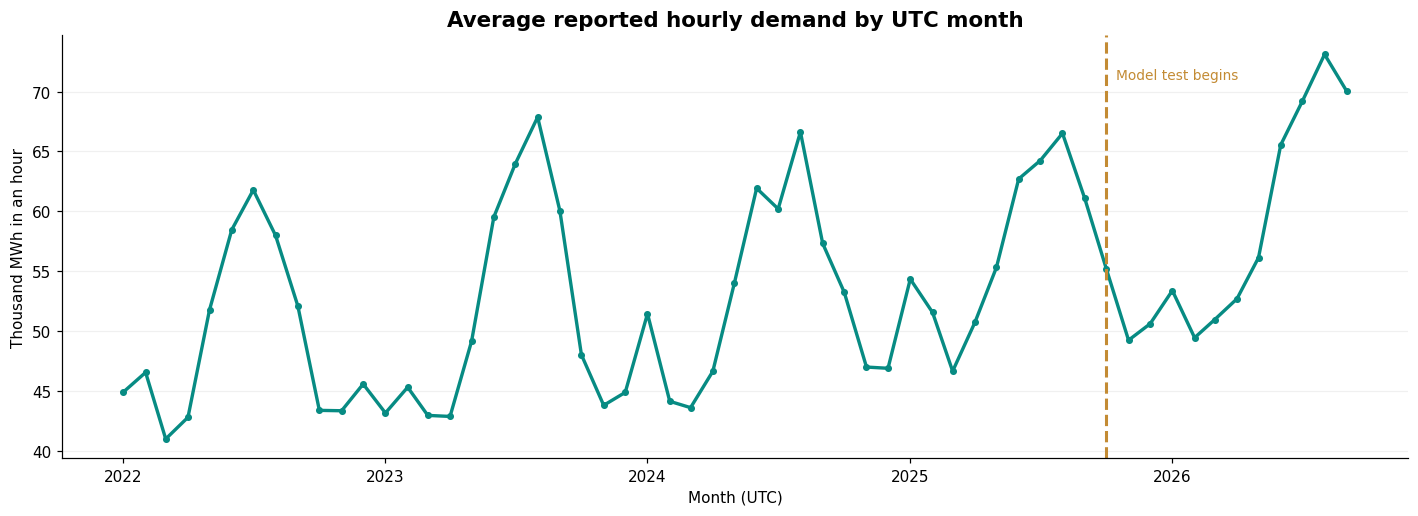

In [4]:
monthly = df.set_index('period_utc')['demand_mwh'].resample('MS').mean() / 1000
fig, ax = plt.subplots(figsize=(13,4.8))
ax.plot(monthly.index, monthly.values, color=TEAL, lw=2.2, marker='o', markersize=3.6)
ax.axvline(pd.Timestamp('2025-10-01', tz='UTC'), color=ORANGE, ls='--', lw=2)
ax.text(pd.Timestamp('2025-10-15',tz='UTC'), monthly.max()*0.985,
        'Model test begins', color=ORANGE, fontsize=9, va='top')
ax.set(title='Average reported hourly demand by UTC month',
       ylabel='Thousand MWh in an hour', xlabel='Month (UTC)')
ax.grid(axis='y',alpha=.18); fig.tight_layout(); finish_figure(fig,'F01_historical_monthly_trend.png')

**What I notice:** The monthly average rises and falls substantially over the calendar, which helps explain why a single overall mean would miss important structure. The orange line at **October 1, 2025 (UTC)** is Andrea's test boundary, not a point where the system itself changed. Her advanced models use the most recent three years of the training era.

**Important distinction:** This is descriptive demand history. It does not identify what caused a long-run change, and it does not directly evaluate forecast accuracy. I'd use it as a transition into the data split rather than overinterpret the line.

**Question:** How can I compare earlier years against an incomplete 2026 without allowing unequal seasonal coverage to dominate?  
**Working presentation priority:** 2/5. This is a useful fairness check in the notebook, even if it does not need its own slide.

### Figure F02 — Year Over Year Jan Sep
**Research question:** *Have January–September demand levels changed across years?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

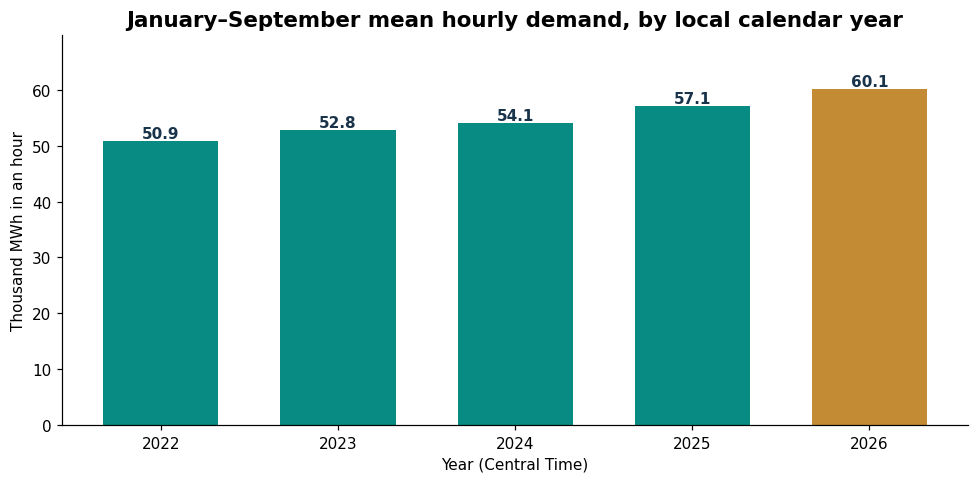

Matched-month table:


,year,Mean thousand MWh/hour
0,2022,50.86
1,2023,52.85
2,2024,54.06
3,2025,57.08
4,2026,60.15


In [5]:
matched = df[(df['year'].between(2022,2026)) & (df['month'].between(1,9))]
yr = (matched.groupby('year',as_index=False)['demand_mwh'].mean())
yr['thousands'] = yr.demand_mwh/1000
fig, ax=plt.subplots(figsize=(9,4.5))
colors=[TEAL]*len(yr); colors[-1]=ORANGE
bars=ax.bar(yr['year'].astype(str),yr.thousands,color=colors,width=.65)
for b,v in zip(bars,yr.thousands): ax.text(b.get_x()+b.get_width()/2,b.get_height()+.5,
                                            f'{v:.1f}',ha='center',weight='bold',color=DEEP)
ax.set(title='January–September mean hourly demand, by local calendar year',
       ylabel='Thousand MWh in an hour', xlabel='Year (Central Time)')
ax.set_ylim(0,yr.thousands.max()*1.16); fig.tight_layout(); finish_figure(fig,'F02_year_over_year_Jan_Sep.png')
print('Matched-month table:');display(yr[['year','thousands']].rename(columns={'thousands':'Mean thousand MWh/hour'}).round(2))

**My interpretation:** The January–September comparison suggests higher observed average hourly demand in more recent years. This is **not a future-demand prediction or a training-data filter**. Matching January through September corrects the descriptive comparison because 2026 has no October–December observations in this file; Andrea's full October 2025–September 2026 test still contains all four seasons.

**Clarification from my review:** If we tried a two-year holdout, that would change the modeling design and the available training history. It is a reasonable experiment to ask Andrea about, not an error established by Figure F02.

**Question:** At what month-hour combinations is typical demand highest, and what calendar structure might forecasting models exploit?  
**Working presentation priority:** **5/5**, one of my leading slide candidates.

### Figure F03 — Month Hour Heatmap
**Research question:** *Which month-by-hour combinations have the highest typical demand?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

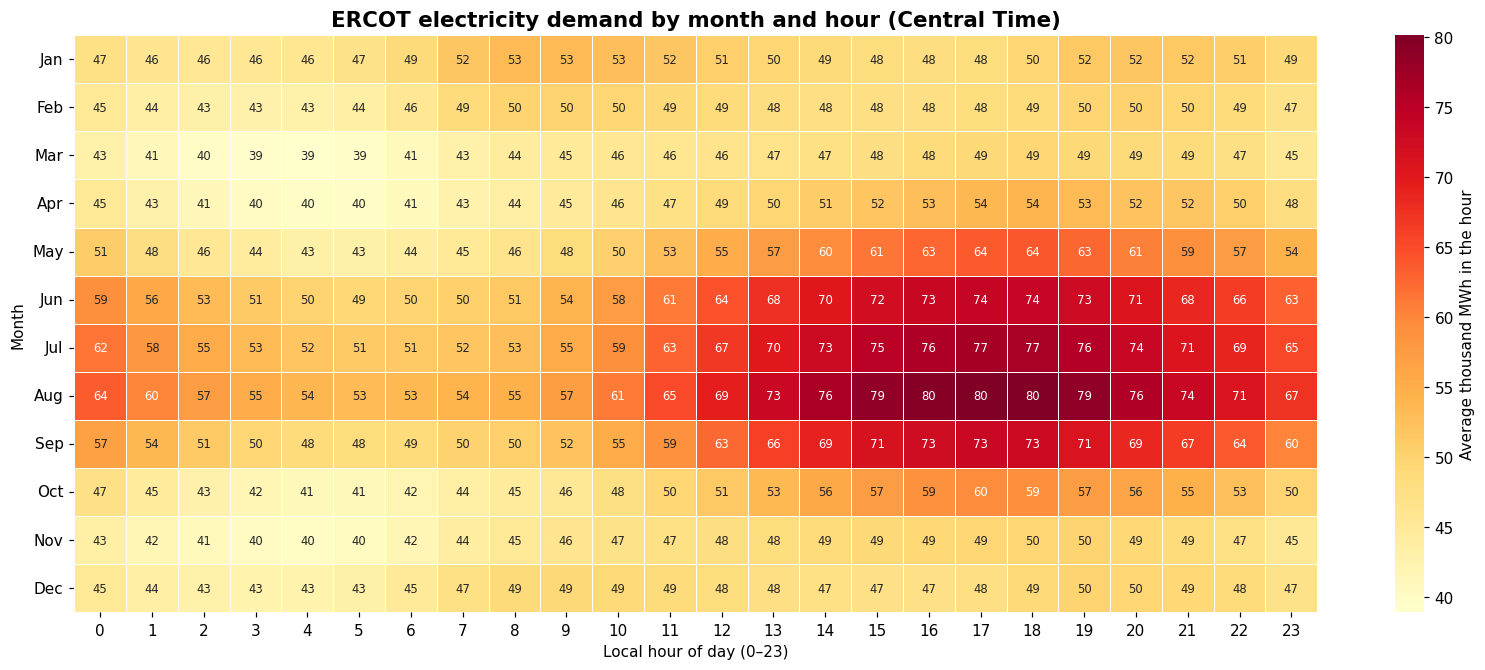

**Strongest typical month–hour cell:** month 8, 17:00 Central, about **80.1 thousand MWh/hour**.

In [6]:
heat = (df.pivot_table(index='month',columns='local_hour',
                       values='demand_mwh',aggfunc='mean')/1000)
heat = heat.reindex(index=range(1,13),columns=range(24))
fig, ax=plt.subplots(figsize=(15,6.2))
sns.heatmap(heat,ax=ax,cmap='YlOrRd',annot=True,fmt='.0f',
            annot_kws={'fontsize':7.6},linewidths=.35,linecolor='white',
            cbar_kws={'label':'Average thousand MWh in the hour'})
ax.set(yticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'],
       title='ERCOT electricity demand by month and hour (Central Time)',
       xlabel='Local hour of day (0–23)',ylabel='Month')
ax.tick_params(axis='y',rotation=0); ax.tick_params(axis='x',rotation=0)
fig.tight_layout(); finish_figure(fig,'F03_month_hour_heatmap.png')
maxpos = np.unravel_index(np.nanargmax(heat.values),heat.shape)
display(Markdown(f'**Strongest typical month–hour cell:** month {heat.index[maxpos[0]]}, '
                 f'{heat.columns[maxpos[1]]}:00 Central, '
                 f'about **{heat.iloc[maxpos]:.1f} thousand MWh/hour**.'))

**What surprised me:** The heatmap makes the monthly and hourly patterns immediately visible in one figure. Its strongest month–hour cell is in August in the late afternoon. It is easier to understand why Sarah created `hour`, `month`, and `season` features after seeing these patterns together.

**What it does and does not demonstrate:** Each cell is a **historical mean pooled over available years**; it is not the highest recorded hour or a forecast. The chart *motivates* relevant inputs to XGBoost but does **not** demonstrate which inputs XGBoost relied on. Showing that would require model interpretation or a feature-ablation comparison.

**Possible presentation development:** Pair it with Figure F04, which separates typical daily profiles by season. I would prioritize the heatmap first because it communicates the calendar relationship efficiently.

**Question:** Does the *shape* of a day vary by season, or only its average level?  
**Working presentation priority:** **5/5**, especially alongside Figure F03.

### Figures F03A–F03E — Looking inside each season, one day and hour at a time

**Why I wanted to add these:** Our original month-by-hour chart shows the *average* shape of demand, but I was interested in what those averages might be hiding. A season can have a consistent daily rhythm while still containing individual days with unusually high or low demand. These heatmaps keep every local calendar day in view: **rows = days, columns = hours (0–23), color = observed hourly electricity demand**.

I used **four complete meteorological seasons from September 2025 through August 2026** so that summer, winter, spring, and fall can be compared without partially recorded seasons. Each panel uses the same color scale; this makes intensity comparisons meaningful. The separate seasonal close-ups make it easier to spot extended stretches of high demand and unusual individual days. For the fall clock change, repeated local hours are averaged *for display only*; the missing local spring-forward hour stays blank. These plots don't change the underlying cleaned demand records.

**Why they matter to our presentation:** Before showing which forecasting model wins, we should establish *why the forecast is challenging*. These figures connect the broad seasonal patterns to day-to-day variation and lead naturally to Andrea's model-error comparisons. We can feature the single four-season comparison on a slide and use the season close-ups as supporting visuals. Unusual demand should not automatically be attributed to weather without confirming the cause.

In [7]:
# F03A–F03E | Four complete seasons: local date by local hour.
SEASON_WINDOWS = {
    'Fall 2025': ('2025-09-01','2025-11-30'),
    'Winter 2025–26': ('2025-12-01','2026-02-28'),
    'Spring 2026': ('2026-03-01','2026-05-31'),
    'Summer 2026': ('2026-06-01','2026-08-31')
}
season_daily=df[['local_date','local_hour','demand_mwh']].copy()
season_daily['local_date']=pd.to_datetime(season_daily['local_date'])
DAILY_HEATMAPS={}
for label,(start,end) in SEASON_WINDOWS.items():
    dates=pd.date_range(start,end,freq='D')
    selected=season_daily[season_daily['local_date'].between(start,end)]
    matrix=(selected.pivot_table(index='local_date',columns='local_hour',
              values='demand_mwh',aggfunc='mean')
              .reindex(index=dates,columns=range(24))/1000)
    if matrix.isna().sum().sum()>1:
        print(f'Note: {label} has {matrix.isna().sum().sum()} missing local-hour positions.')
    assert matrix.notna().sum(axis=1).ge(23).all(),f'Check unexpected missing day in {label}'
    DAILY_HEATMAPS[label]=matrix
heat_scale_min=min(m.min().min() for m in DAILY_HEATMAPS.values())
heat_scale_max=max(m.max().max() for m in DAILY_HEATMAPS.values())
print('Shared color scale (thousand MWh/hour):',round(heat_scale_min,1),'to',round(heat_scale_max,1))
for k,m in DAILY_HEATMAPS.items():
    print(f'{k}: {len(m)} dates; {m.notna().sum().sum()} recorded local-hour positions')

Shared color scale (thousand MWh/hour): 39.0 to 91.1
Fall 2025: 91 dates; 2184 recorded local-hour positions
Winter 2025–26: 90 dates; 2160 recorded local-hour positions
Spring 2026: 92 dates; 2207 recorded local-hour positions
Summer 2026: 92 dates; 2208 recorded local-hour positions


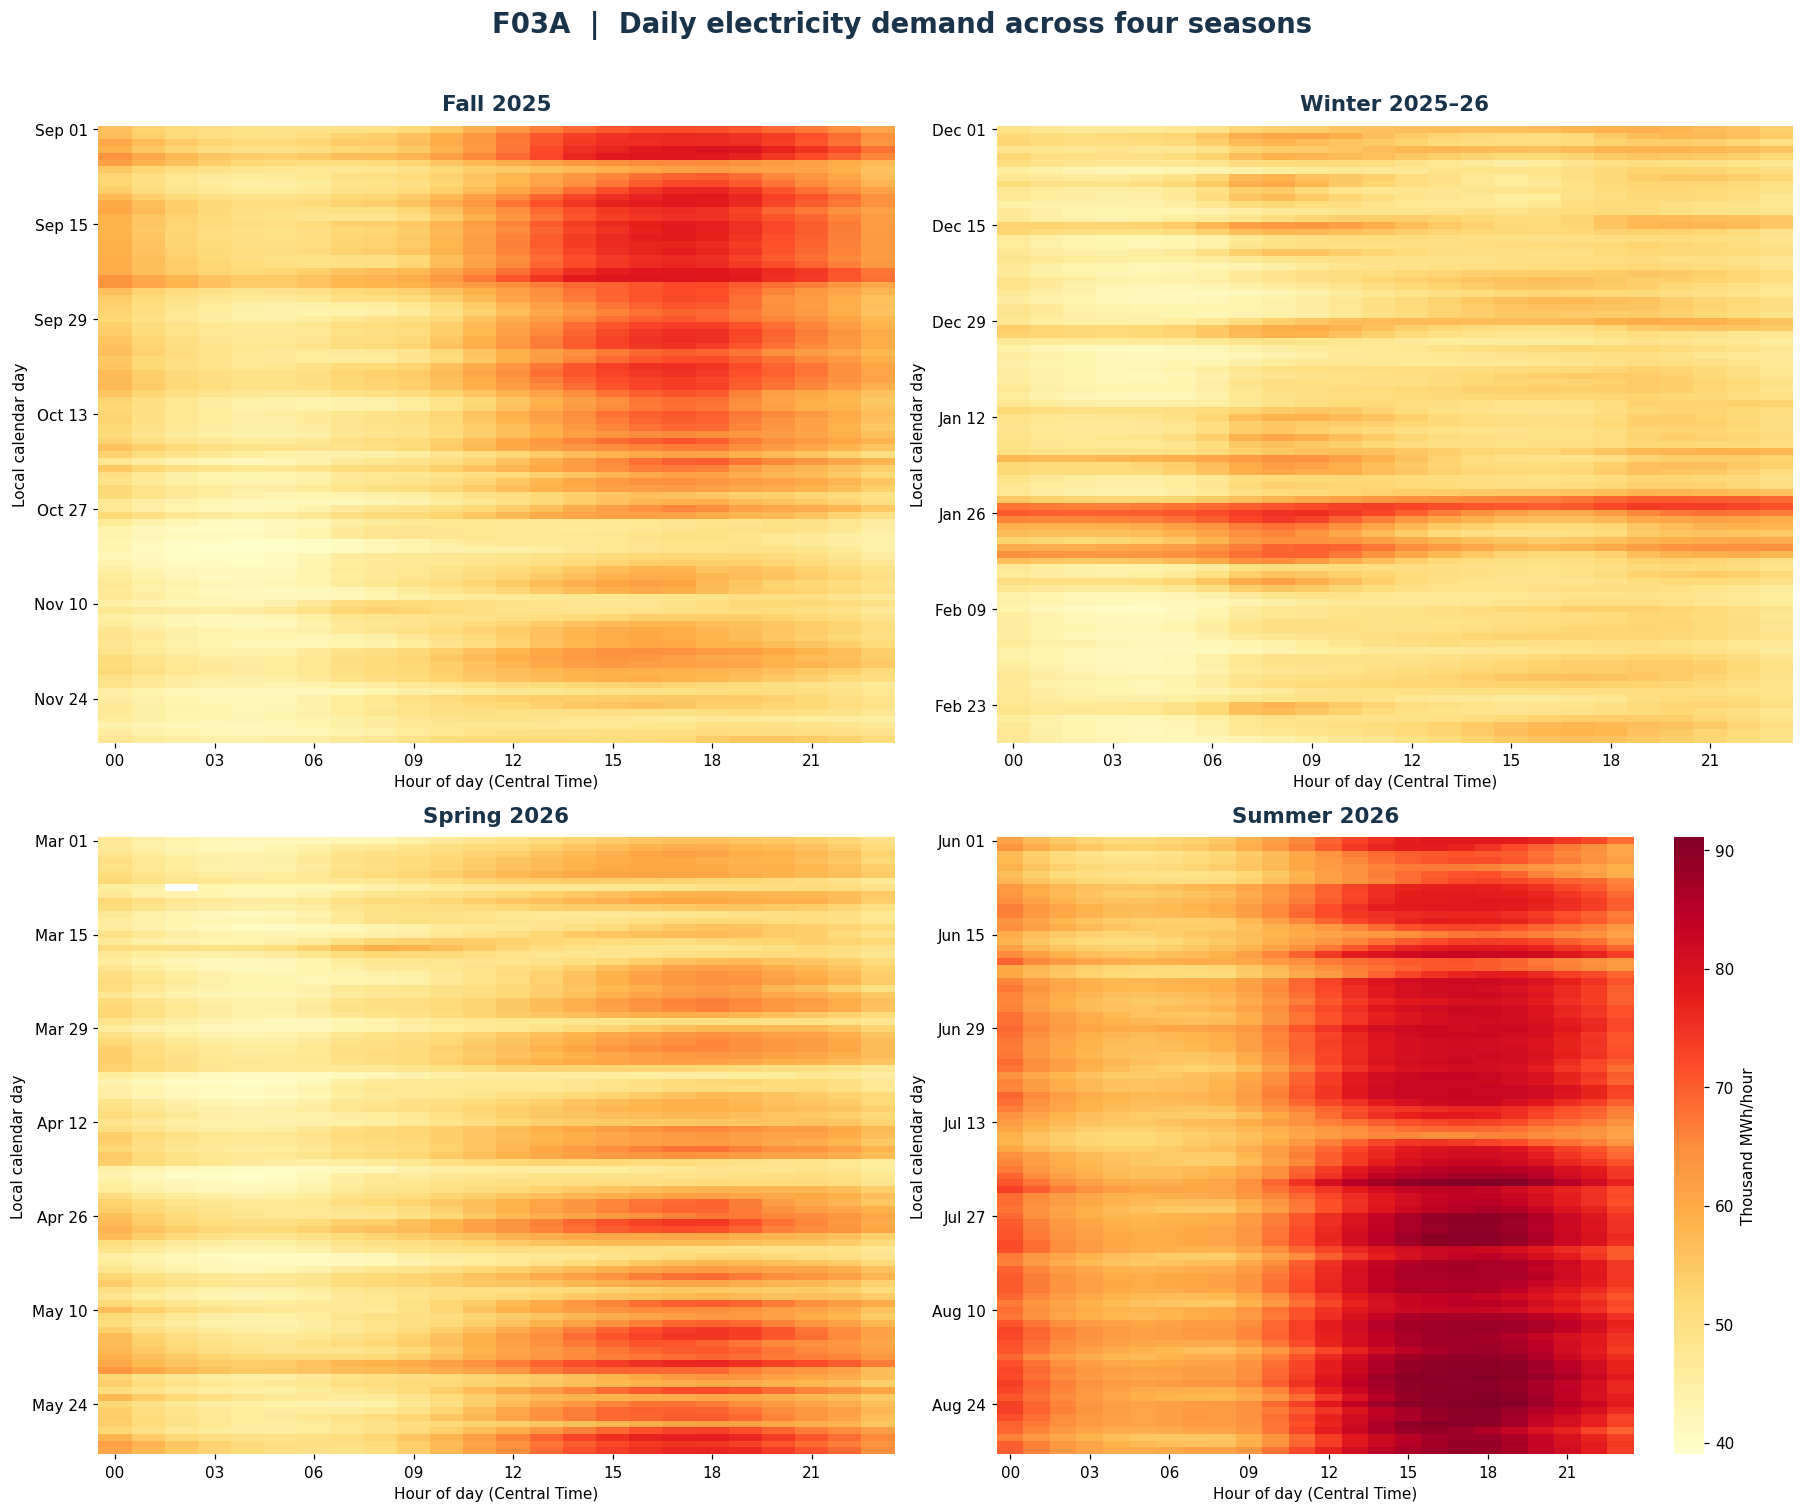

In [8]:
# F03A | One presentation-ready comparison. Fixed scale across all four panels.
fig,axes=plt.subplots(2,2,figsize=(16.5,13.5))
for i,(ax,(label,matrix)) in enumerate(zip(axes.flat,DAILY_HEATMAPS.items())):
    sns.heatmap(matrix,ax=ax,cmap='YlOrRd',vmin=heat_scale_min,vmax=heat_scale_max,
                xticklabels=False,yticklabels=False,cbar=(i==3),
                cbar_kws={'label':'Thousand MWh/hour'})
    xt=list(range(0,24,3)); yt=list(range(0,len(matrix),14))
    ax.set_xticks([t+.5 for t in xt]);ax.set_xticklabels([f'{t:02}' for t in xt],rotation=0)
    ax.set_yticks([t+.5 for t in yt]);ax.set_yticklabels([matrix.index[t].strftime('%b %d') for t in yt],rotation=0)
    ax.set_title(label,color=DEEP,pad=10)
    ax.set_xlabel('Hour of day (Central Time)');ax.set_ylabel('Local calendar day')
fig.suptitle('F03A  |  Daily electricity demand across four seasons',color=DEEP,fontsize=18,fontweight='bold',y=1.015)
finish_figure(fig,'F03A_four_season_daily_comparison.png')

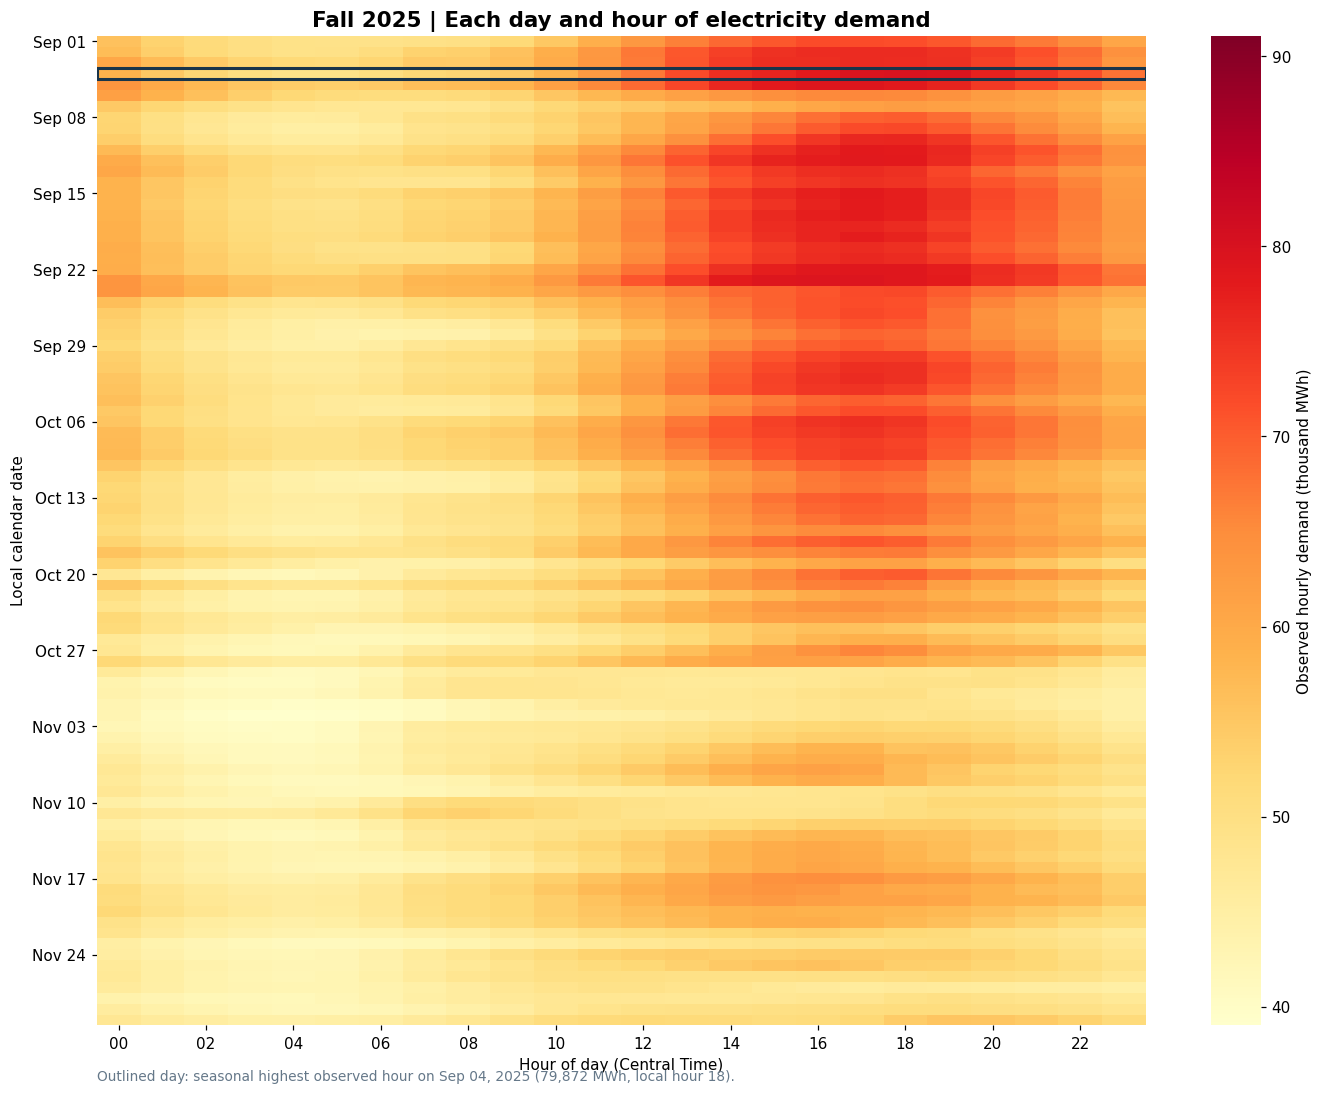

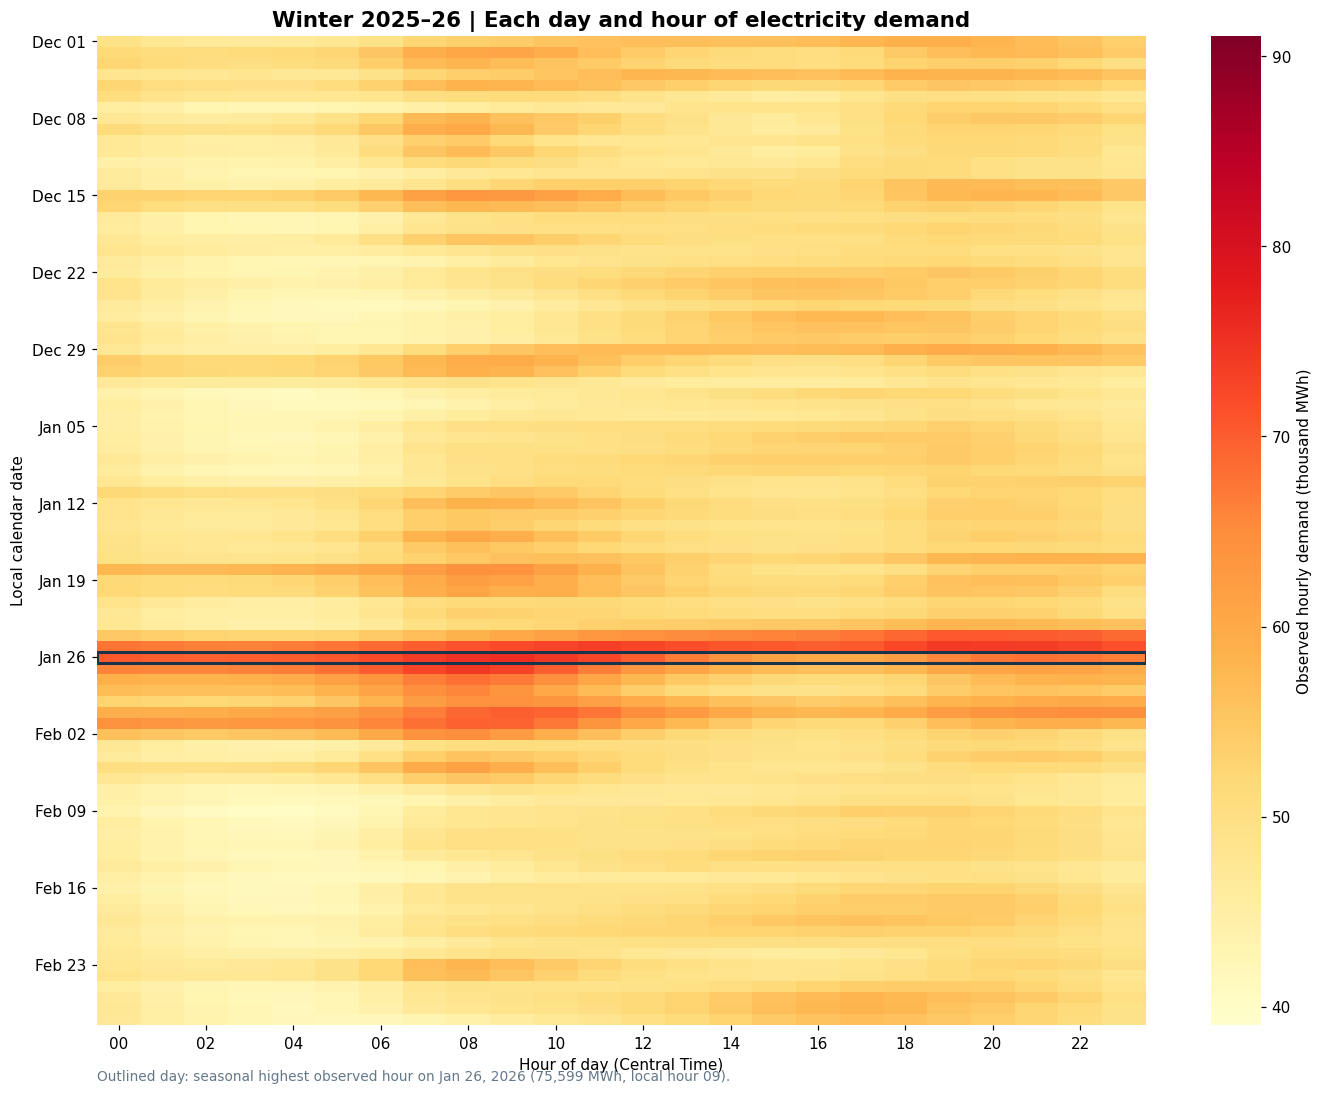

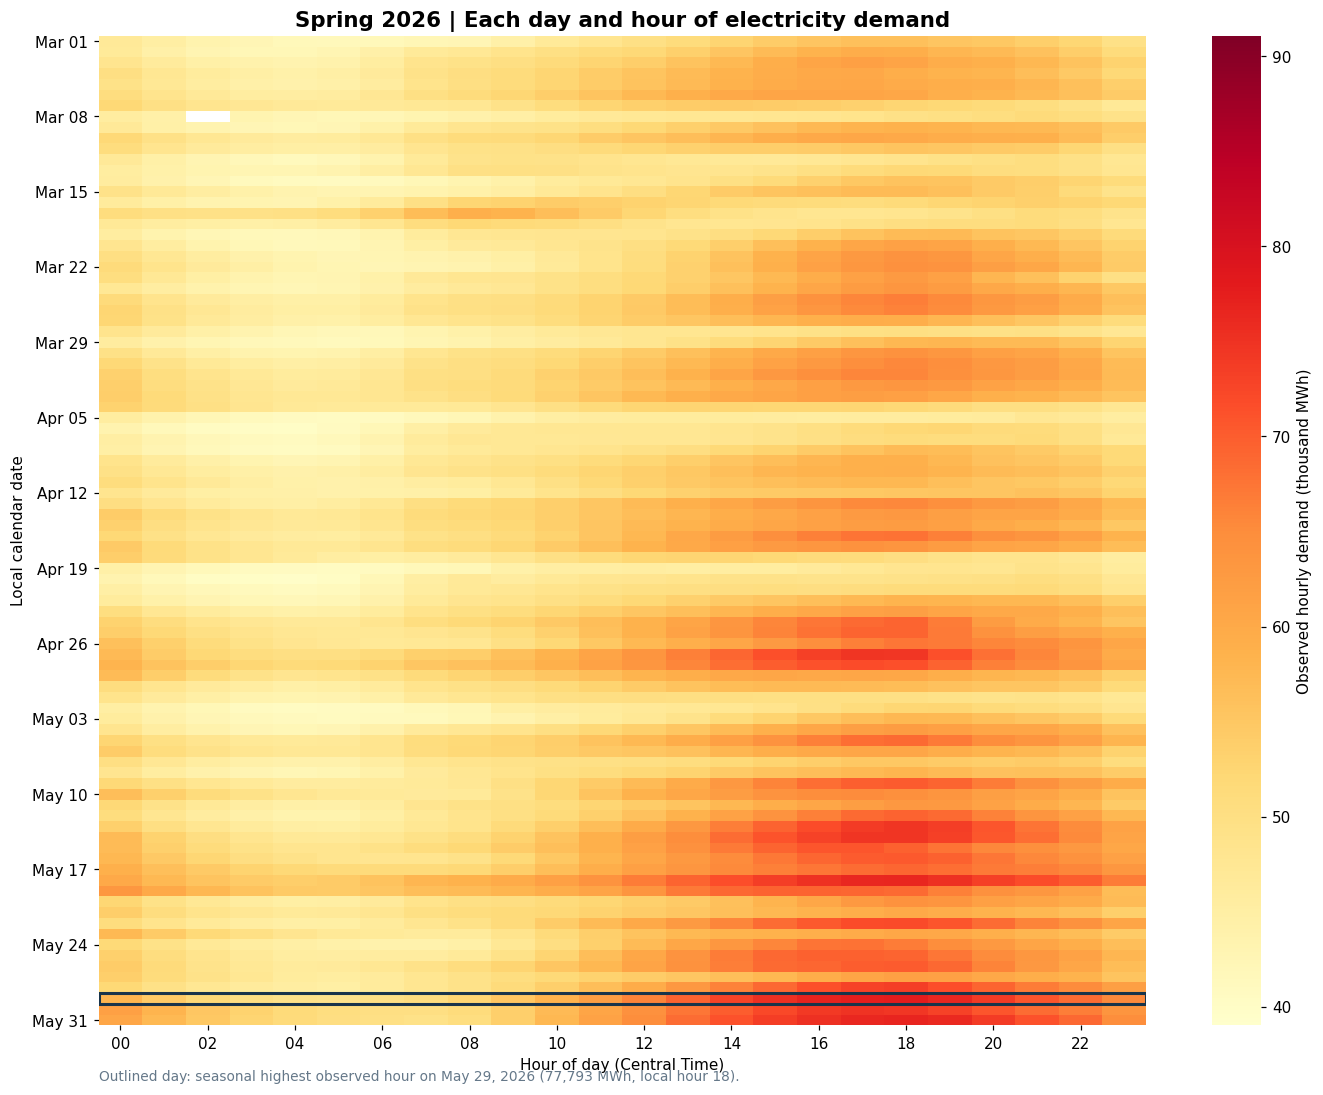

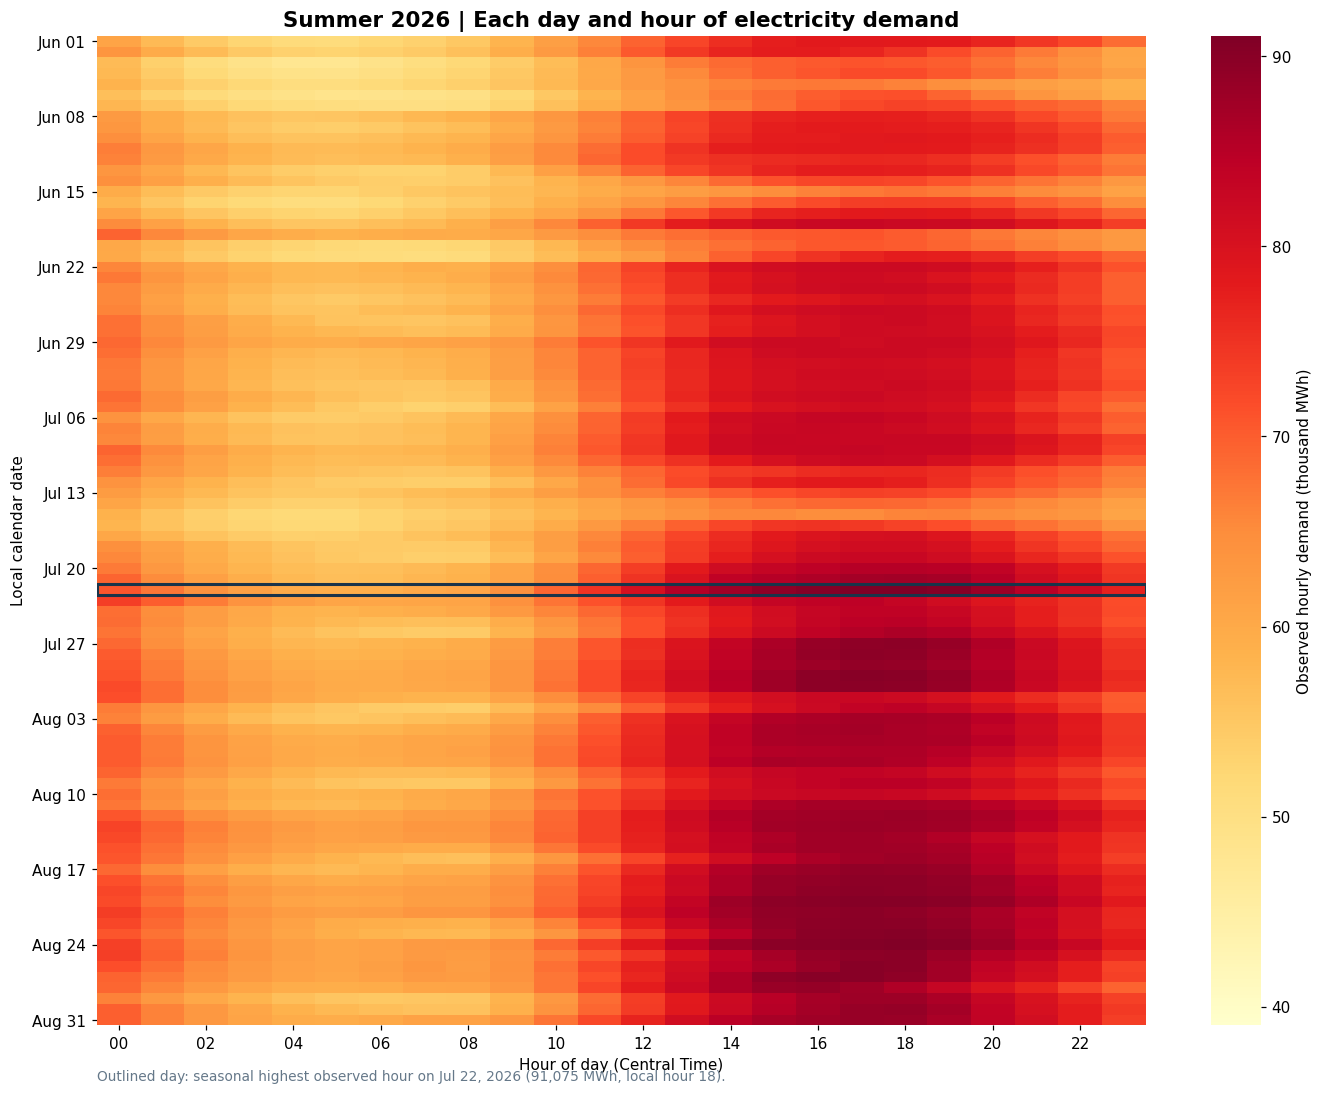

,Season,Highest-demand date,Local hour,Peak hourly demand (MWh)
0,Fall 2025,2025-09-04,18,79872
1,Winter 2025–26,2026-01-26,9,75599
2,Spring 2026,2026-05-29,18,77793
3,Summer 2026,2026-07-22,18,91075


In [9]:
# F03B–F03E | Separate close-ups for the appendix or report.
SEASON_FIG_NAMES={
    'Fall 2025':'F03B_fall_daily_heatmap.png',
    'Winter 2025–26':'F03C_winter_daily_heatmap.png',
    'Spring 2026':'F03D_spring_daily_heatmap.png',
    'Summer 2026':'F03E_summer_daily_heatmap.png'
}
season_peaks=[]
for label,matrix in DAILY_HEATMAPS.items():
    fig,ax=plt.subplots(figsize=(13,10))
    sns.heatmap(matrix,ax=ax,cmap='YlOrRd',vmin=heat_scale_min,vmax=heat_scale_max,
                xticklabels=False,yticklabels=False,
                cbar_kws={'label':'Observed hourly demand (thousand MWh)'})
    row,hour=np.unravel_index(np.nanargmax(matrix.to_numpy()),matrix.shape)
    day=matrix.index[row]; amount=matrix.iloc[row,hour]*1000
    ax.add_patch(Rectangle((0,row),24,1,fill=False,edgecolor=DEEP,lw=2))
    xt=list(range(0,24,2));yt=list(range(0,len(matrix),7))
    ax.set_xticks([t+.5 for t in xt]);ax.set_xticklabels([f'{t:02}' for t in xt],rotation=0)
    ax.set_yticks([t+.5 for t in yt]);ax.set_yticklabels([matrix.index[t].strftime('%b %d') for t in yt],rotation=0)
    ax.set(title=f'{label} | Each day and hour of electricity demand',
           xlabel='Hour of day (Central Time)',ylabel='Local calendar date')
    ax.text(0,-.045,f'Outlined day: seasonal highest observed hour on {day:%b %d, %Y} '
                 f'({amount:,.0f} MWh, local hour {hour:02}).',
            transform=ax.transAxes,color=MUTED,fontsize=9,va='top')
    finish_figure(fig,SEASON_FIG_NAMES[label])
    season_peaks.append({'Season':label,'Highest-demand date':day.date(),
                         'Local hour':int(hour),'Peak hourly demand (MWh)':round(amount)})
display(pd.DataFrame(season_peaks))

**Interpretation and speaking note.** What I find most useful is how much variation becomes visible when I stop averaging every day together. The four-season comparison offers a broad pattern, but the separate panels let us discuss the timing, duration and concentration of demanding hours without assuming that every day behaves like a typical day. This provides context for later Figures F17–F19 and F26–F33, which ask whether particular periods are also harder for the forecasting models. **A high-demand hour is not automatically a high-error hour:** we verify that relationship using actual predictions instead of inferring it from color intensity.

### Figure F04 — Season Hour Profiles
**Research question:** *How do the 24-hour shapes differ across winter, spring, summer and fall?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

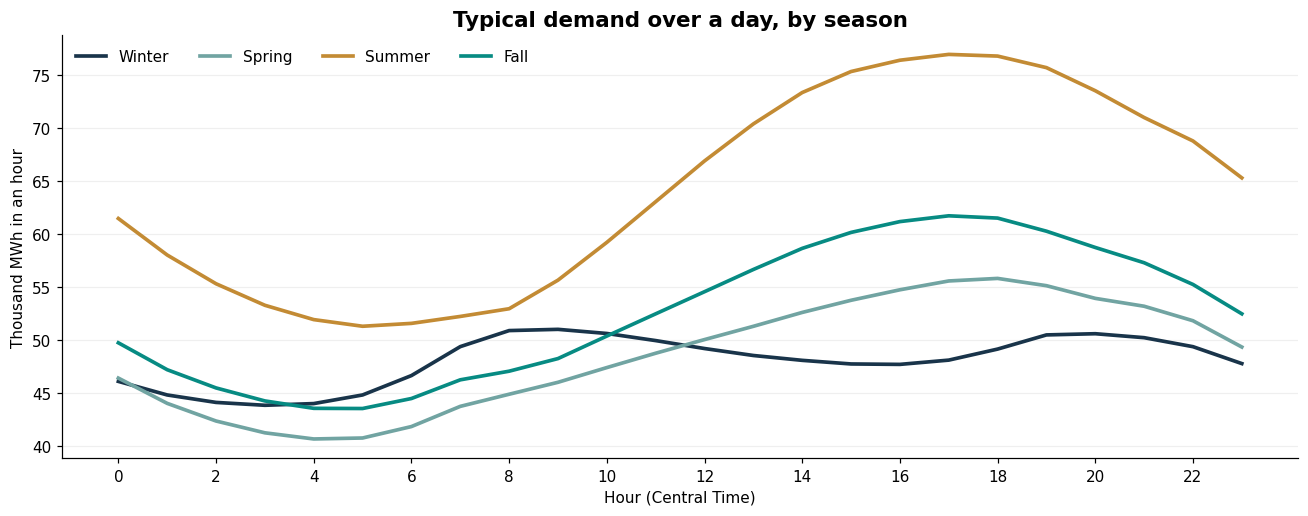

In [10]:
profiles=(df.groupby(['season','local_hour'])['demand_mwh'].mean()/1000).unstack(0)
fig,ax=plt.subplots(figsize=(12,4.8))
for season,color in [('Winter',DEEP),('Spring','#71A4A2'),('Summer',ORANGE),('Fall',TEAL)]:
    if season in profiles: ax.plot(profiles.index,profiles[season],label=season,lw=2.4,color=color)
ax.set(title='Typical demand over a day, by season',xlabel='Hour (Central Time)',
       ylabel='Thousand MWh in an hour',xticks=range(0,24,2)); ax.grid(axis='y',alpha=.2)
ax.legend(ncol=4,frameon=False);fig.tight_layout();finish_figure(fig,'F04_season_hour_profiles.png')

**My interpretation:** Summer's typical daily profile differs from other seasons in both level and shape. The line chart provides a clearer account of the daily curve than the heatmap alone and helps motivate temporal modeling.

**Connection to Andrea:** SARIMA includes a 24-hour seasonal period. Prophet was configured with daily, weekly, and annual seasonal terms. XGBoost received calendar and lag features. These choices are related to the structures shown here, though their ability to model those structures must still be judged from held-out predictions.

**Presentation decision:** Figure F03 and Figure F04 both scored highly in my review, but they overlap. They might work best as complementary panels rather than two slides saying the same thing.

**Question:** Are daily demand profiles associated with day type?  
**Working presentation priority:** 3/5, useful support for `day_of_week` and `is_weekend` rather than a main result.

### Figure F05 — Weekday Weekend Profiles
**Research question:** *How do weekend and weekday demand patterns compare?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

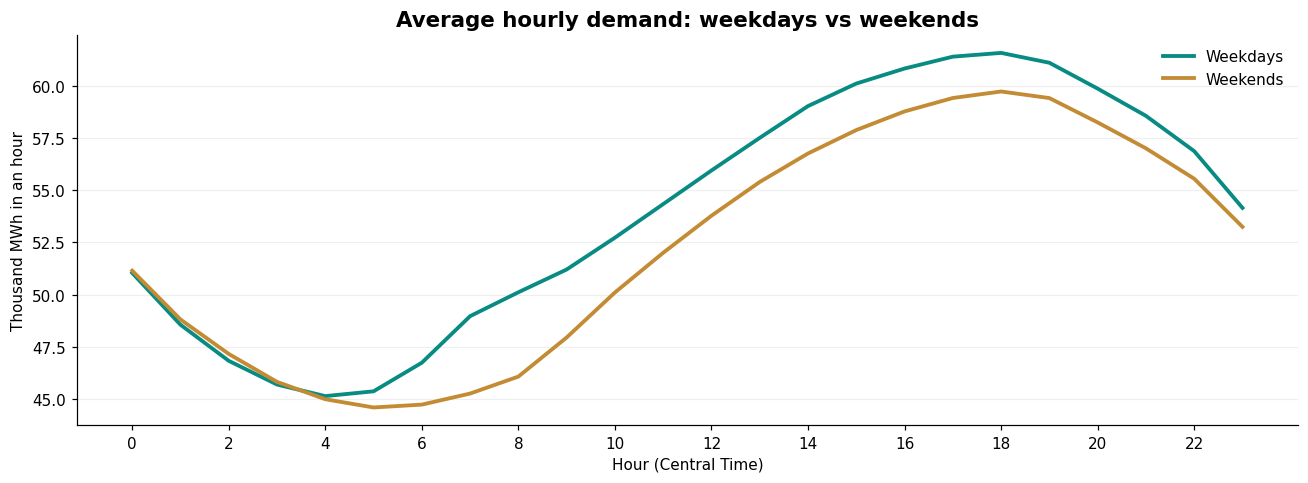

In [11]:
dow=(df.groupby(['is_weekend','local_hour'])['demand_mwh'].mean()/1000).unstack(0)
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(dow.index,dow[0],label='Weekdays',lw=2.5,color=TEAL)
ax.plot(dow.index,dow[1],label='Weekends',lw=2.5,color=ORANGE)
ax.set(title='Average hourly demand: weekdays vs weekends',xlabel='Hour (Central Time)',
       ylabel='Thousand MWh in an hour',xticks=range(0,24,2)); ax.legend(frameon=False)
ax.grid(axis='y',alpha=.2);fig.tight_layout();finish_figure(fig,'F05_weekday_weekend_profiles.png')

**My interpretation:** Day type is associated with different demand patterns. Sarah prepared `is_weekend`, and Andrea uses it in XGBoost. The figure is useful evidence for exploring weekly structure.

**Caution:** The EIA-930 demand series does not split electricity use by residential, commercial, or industrial sector. I can describe an association with weekday and weekend routines, but I cannot attribute a numerical difference to a particular customer group from this dataset.

**Question:** How different are typical and higher-demand observations within the same month?  
**Working presentation priority:** **5/5** in my review of exploratory analysis.

### Figure F06 — Monthly Boxplots
**Research question:** *How much variation is concealed by monthly means?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

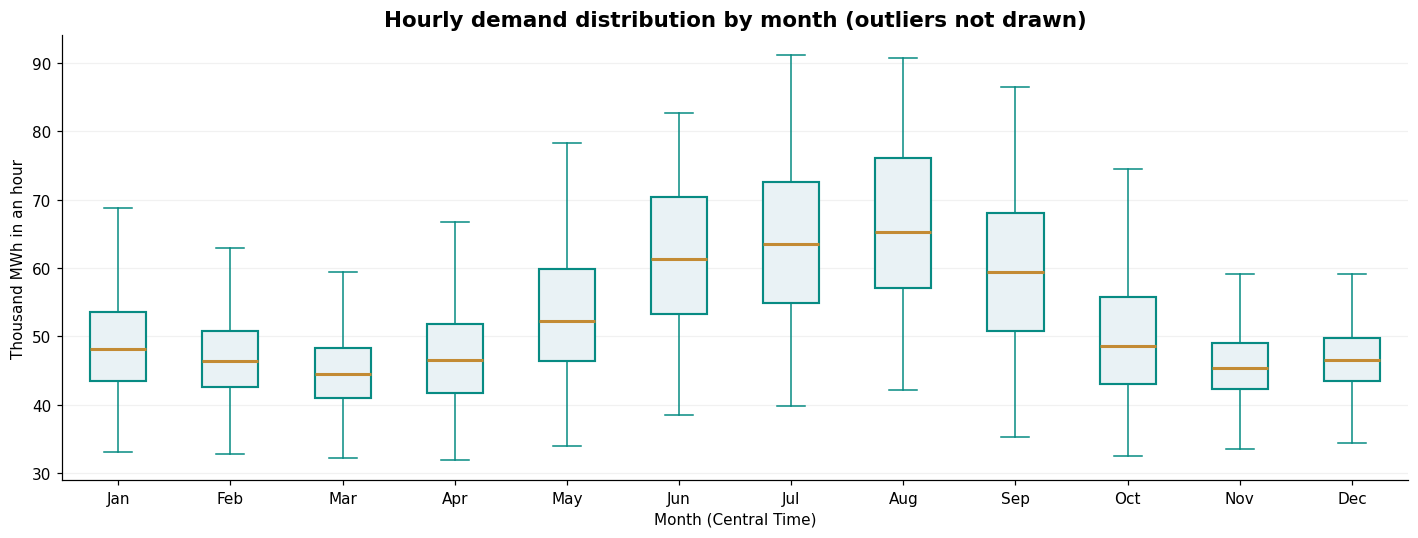

In [12]:
fig,ax=plt.subplots(figsize=(13,5))
vals=[df.loc[df.month==m,'demand_mwh'].values/1000 for m in range(1,13)]
artists=ax.boxplot(vals,patch_artist=True,showfliers=False,medianprops={'color':ORANGE,'linewidth':2})
for p in artists['boxes']:p.set(facecolor=LIGHT,edgecolor=TEAL,linewidth=1.4)
for part in ['whiskers','caps']:
    for p in artists[part]:p.set(color=TEAL)
ax.set(title='Hourly demand distribution by month (outliers not drawn)',
       ylabel='Thousand MWh in an hour',xlabel='Month (Central Time)',
       xticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.grid(axis='y',alpha=.17);fig.tight_layout();finish_figure(fig,'F06_monthly_boxplots.png')

**What I wanted to investigate:** A monthly mean alone hides the range and dispersion of hourly demand. These **boxplots pool all available years for each local month**, not one particular year. The figure displays median and quartiles; individual outlier points are hidden **only from the drawing**, not deleted from the data.

**My possible revision:** I would like to compare this against a violin plot, which can show the shape of each monthly distribution in more detail. But a violin plot is not automatically more understandable for our presentation. I would test the alternative and choose the form that makes the business point clearest.

**Model-evaluation connection:** More variability in observed demand is worth investigating, but variability alone does not prove that a model has a larger MAE or RMSE in that month.

**Question:** In which months does a larger share of hours exceed the dataset-wide 95th-percentile demand threshold?  
**Working presentation priority:** 3/5, useful as a bridge to peak-demand forecasting.

### Figure F07 — Peak Share By Month
**Research question:** *In which months are top-five-percent demand hours concentrated?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

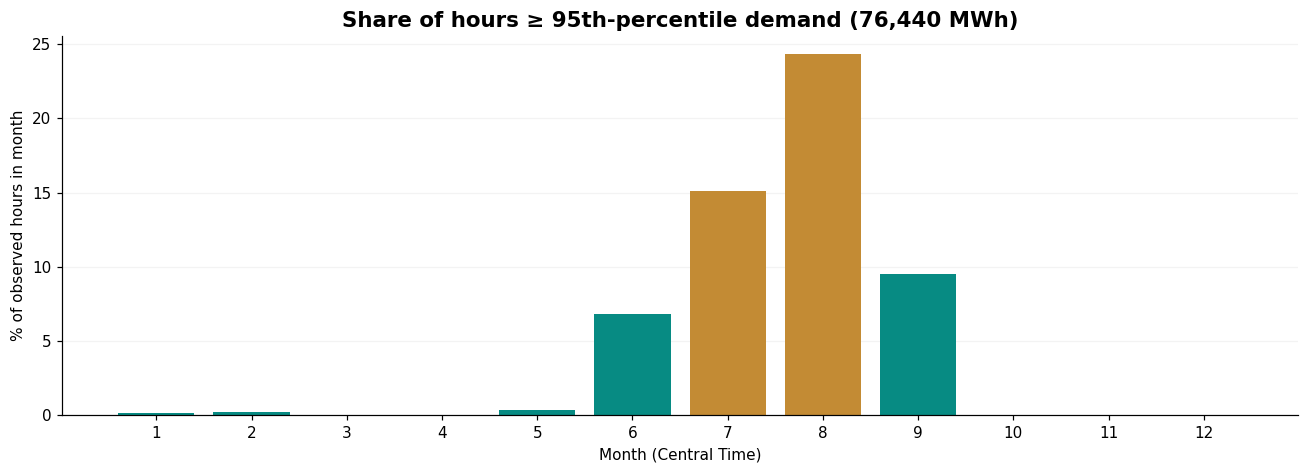

In [13]:
threshold=df['demand_mwh'].quantile(.95)
peakshare=df.assign(top5=df['demand_mwh']>=threshold).groupby('month')['top5'].mean().reindex(range(1,13))*100
fig,ax=plt.subplots(figsize=(12,4.4))
ax.bar([str(m) for m in peakshare.index],peakshare.values,
       color=[ORANGE if v>10 else TEAL for v in peakshare.values])
ax.set(title=f'Share of hours ≥ 95th-percentile demand ({threshold:,.0f} MWh)',
       ylabel='% of observed hours in month',xlabel='Month (Central Time)')
ax.grid(axis='y',alpha=.15);fig.tight_layout();finish_figure(fig,'F07_peak_share_by_month.png')

**My interpretation:** The chart finds where very high-demand **hours** cluster, especially during summer. The denominator is **the number of observed hours in each particular month**, not the number of months. This avoids confusing a raw count with a proportion when year coverage is uneven.

**What the chart suggests:** Since these hours are operationally interesting, I wanted to know whether models make larger errors during them. But Figure F07 itself does not evaluate errors. Figure F13 performs that analysis for ERCOT's published forecast; we would need exported predictions to repeat it for SARIMA or XGBoost.

**Question:** When does demand typically change more sharply from one hour to the next?  
**Working presentation priority:** 2/5, potentially valuable for discussing ramps but lower priority than the heatmap and case study.

### Figure F08 — Hourly Ramping
**Research question:** *At which hours does demand change fastest?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

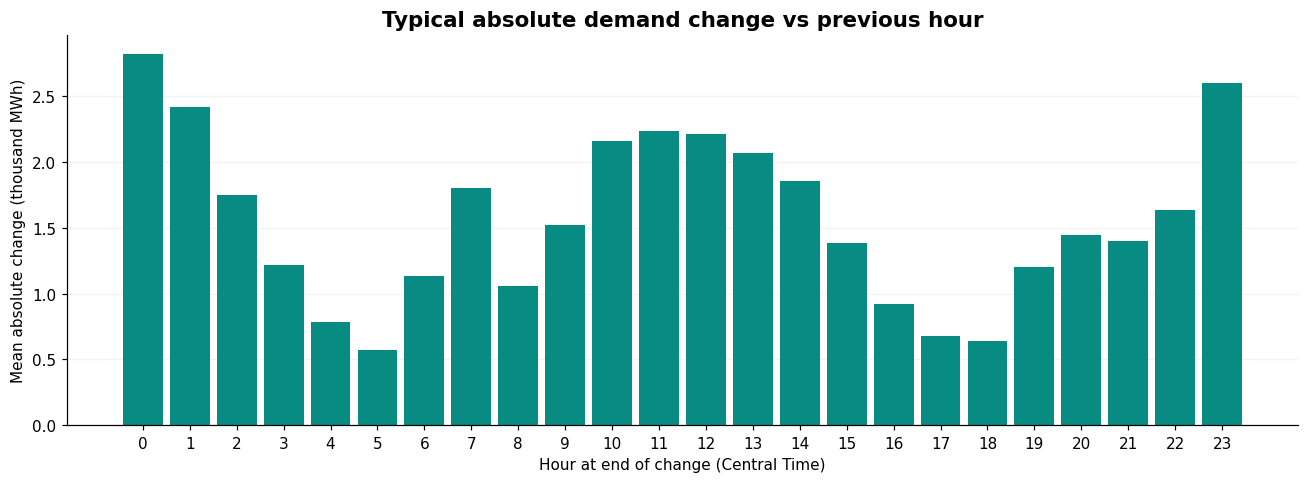

In [14]:
df['hourly_change_mwh']=df['demand_mwh'].diff()
ramp=df.groupby('local_hour')['hourly_change_mwh'].apply(lambda x:x.abs().mean())/1000
fig,ax=plt.subplots(figsize=(12,4.5))
ax.bar(ramp.index,ramp.values,color=TEAL,width=.85)
ax.set(title='Typical absolute demand change vs previous hour',
       xlabel='Hour at end of change (Central Time)',ylabel='Mean absolute change (thousand MWh)',
       xticks=range(24));ax.grid(axis='y',alpha=.14);fig.tight_layout();finish_figure(fig,'F08_hourly_ramping.png')

**My interpretation:** This chart is about **change**, not total demand. A hour with high demand does not necessarily have a large change relative to the preceding hour, and a large ramp does not automatically mean a large forecasting error.

**Connection to operational planning:** Rapid shifts can be important to prepare for, but we have not quantified the costs or reliability consequences. I initially wondered about using this to discuss generation scheduling, but I would keep that explanation general unless we add a credible operational source.

**Why it may stay in the notebook:** It raises a useful question about forecasting complexity, but I do not yet see it outperforming the other figures for the main slide sequence.

**Question:** What does an unusually demanding week look like instead of an abstract average?  
**Working presentation priority:** **4/5**, strong narrative example.

### Figure F09 — July Peak Week
**Research question:** *What does a real high-load week look like?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

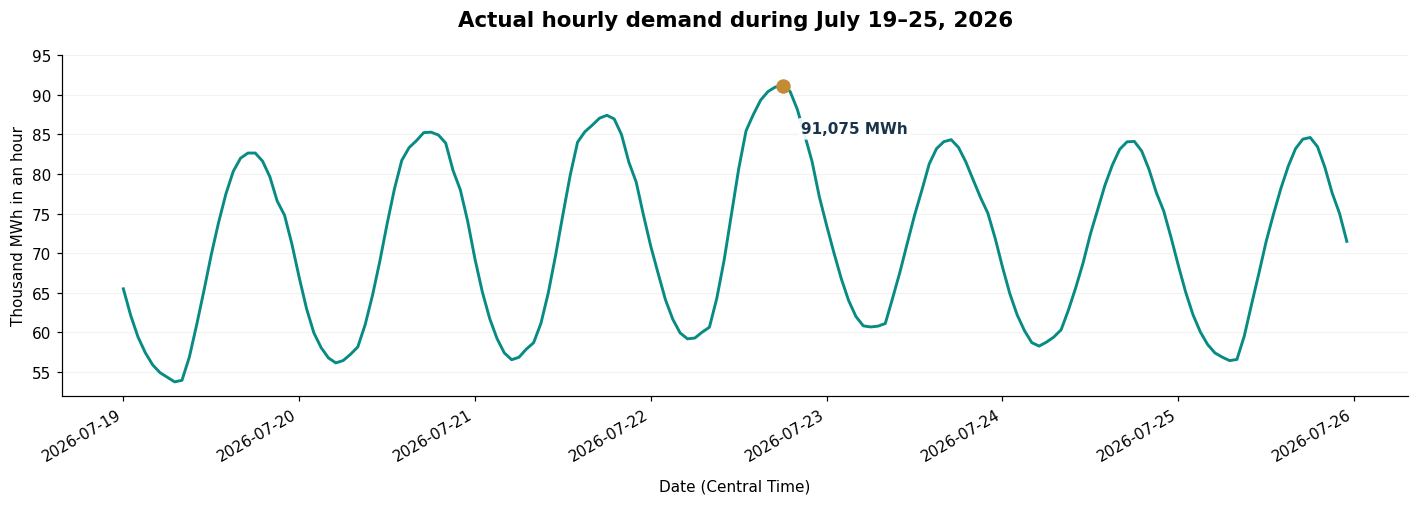

In [15]:

week = df[
    (df.period_central >= pd.Timestamp('2026-07-19', tz='America/Chicago')) &
    (df.period_central < pd.Timestamp('2026-07-26', tz='America/Chicago'))
]

fig, ax = plt.subplots(figsize=(13, 4.7))

ax.plot(
    week.period_central,
    week.demand_mwh / 1000,
    color=TEAL,
    lw=1.9
)

if not week.empty:
    p = week.loc[week.demand_mwh.idxmax()]

    ax.scatter(
        [p.period_central],
        [p.demand_mwh / 1000],
        s=72,
        color=ORANGE,
        zorder=5
    )

    ax.annotate(
        f'{p.demand_mwh:,.0f} MWh',
        xy=(p.period_central, p.demand_mwh / 1000),
        xytext=(12, -23),
        textcoords='offset points',
        ha='left',
        va='top',
        color=DEEP,
        weight='bold',
        fontsize=10,
        bbox=dict(
            boxstyle='round,pad=.22',
            facecolor='white',
            edgecolor='none',
            alpha=.90
        ),
        zorder=6
    )

ax.set_title(
    'Actual hourly demand during July 19–25, 2026',
    pad=19
)
ax.set_ylabel('Thousand MWh in an hour')
ax.set_xlabel('Date (Central Time)', labelpad=10)
ax.grid(axis='y', alpha=.16)
ax.set_ylim(bottom=52, top=95)

fig.autofmt_xdate()
fig.tight_layout(pad=1.65)

finish_figure(fig, 'F09_july_peak_week.png')


**What I notice:** A real week helps make the forecasting problem tangible. The dataset records **91,075 MWh on July 22, 2026**, during a one-hour interval. EIA also reported an ERCOT hourly peak-load record that day (see references).

**What I would say:** The figure shows that even during a particularly demanding week, electricity use rises and falls throughout the day. I want to understand whether a forecasting method can anticipate that *shape* as well as the peak itself.

**What not to infer:** This shows *actual demand*, not whether our models forecast that week well. The historical record and external reporting give context for the event, not an explanation of our models' errors.

## 4. Forecast evaluation | F10–F15

First we examine the ERCOT-reported forecast, then recalculate eight-series errors from Andrea's predictions on the identical **8,640 benchmark-available hours**. Forecast parity is not fully audited.

**Consistent sign convention throughout this notebook:** signed error = **forecast − actual** (positive = overforecast, negative = underforecast). Absolute error and MAE do not have a sign. Higher-demand bins in later figures are formed using *observed* load for retrospective evaluation only.

In [16]:
test=df.loc[df.period_utc>=pd.Timestamp('2025-10-01',tz='UTC')].copy()
shared=test.loc[test.demand_forecast_mwh.notna()].copy()
shared['forecast_error_mwh']=shared['demand_forecast_mwh']-shared['demand_mwh']
shared['absolute_error_mwh']=shared['forecast_error_mwh'].abs()
print(f'Test hours: {len(test):,} | ERCOT reported forecast hours: {len(shared):,} | '
      f'Not available: {len(test)-len(shared):,}')
assert len(test)==8760 and len(shared)==8640, 'Data window changed: investigate before comparing metrics'
benchmark_mae=shared.absolute_error_mwh.mean()
benchmark_rmse=np.sqrt(np.mean(shared.forecast_error_mwh**2))
benchmark_mape=(shared.absolute_error_mwh/shared.demand_mwh).mean()*100
print(f'Independent ERCOT check: MAE {benchmark_mae:,.2f}; RMSE {benchmark_rmse:,.2f}; '
      f'MAPE {benchmark_mape:.2f}%')

Test hours: 8,760 | ERCOT reported forecast hours: 8,640 | Not available: 120
Independent ERCOT check: MAE 1,134.80; RMSE 1,594.34; MAPE 2.00%


**Question:** What does a forecast look like when laid over actual hourly demand?  
**Working presentation priority:** **5/5**. It directly explains the concept of prediction to a nontechnical viewer.

**Source label to preserve:** The orange line is **ERCOT's EIA-930 reported demand forecast**, not SARIMA or XGBoost. This figure shows one week, **not the entire 2022–2026 period**.

### Figure F10 — Ercot Actual Vs Forecast
**Research question:** *How closely does ERCOT’s published prediction follow observed load?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

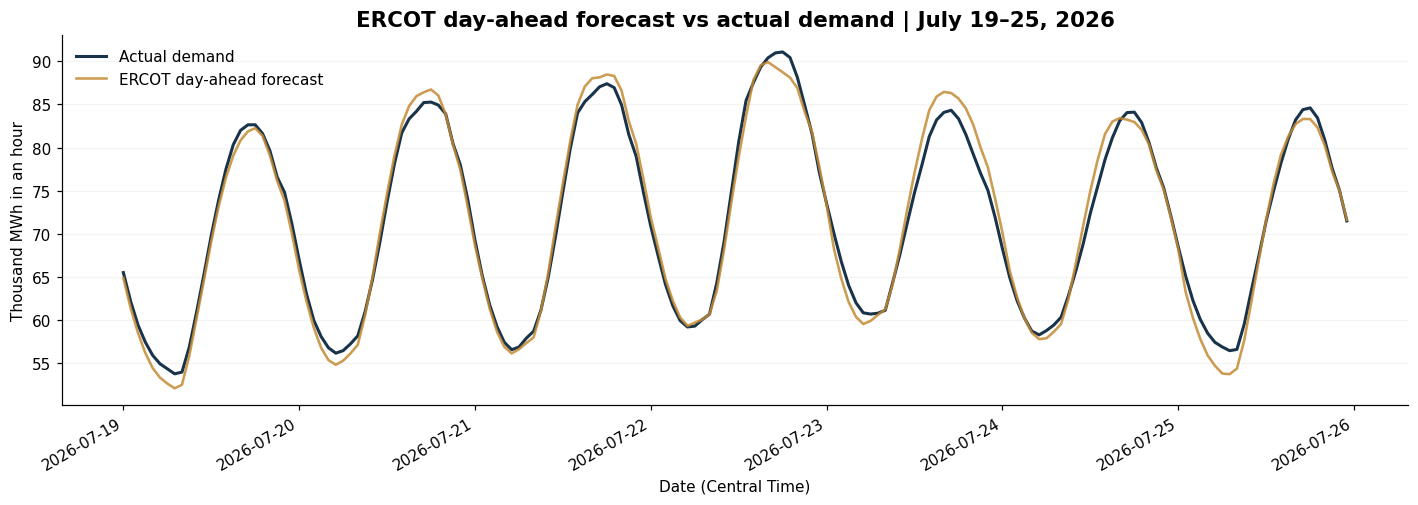

In [17]:
view=shared[(shared.period_central>=pd.Timestamp('2026-07-19',tz='America/Chicago')) &
            (shared.period_central<pd.Timestamp('2026-07-26',tz='America/Chicago'))]
fig,ax=plt.subplots(figsize=(13,4.7))
ax.plot(view.period_central,view.demand_mwh/1000,label='Actual demand',color=DEEP,lw=2)
ax.plot(view.period_central,view.demand_forecast_mwh/1000,label='ERCOT day-ahead forecast',
        color=ORANGE,lw=1.7,alpha=.85)
ax.set(title='ERCOT day-ahead forecast vs actual demand | July 19–25, 2026',
       xlabel='Date (Central Time)',ylabel='Thousand MWh in an hour')
ax.legend(loc='upper left',frameon=False);ax.grid(axis='y',alpha=.15)
fig.autofmt_xdate();fig.tight_layout();finish_figure(fig,'F10_ercot_actual_vs_forecast.png')

**My interpretation:** The two lines follow similar daily movements, but the vertical scale can make meaningful differences appear tiny. I do not want the audience to assume that overlapping lines mean near-perfect predictions.

**Next investigation:** Hourly and seasonal error patterns are explored below, leading to Figures F11–F13 and later cross-model diagnostic figures.

**Source:** Actual demand and ERCOT reported forecasts come from Sarah's cleaned table; Andrea's pointwise model predictions are already supplied separately and appear in F14–F25.

**Next question:** At what local hours does the benchmark make larger average errors?

### Figure F11 — Ercot Mae By Hour
**Research question:** *When is ERCOT’s typical absolute forecasting error largest?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

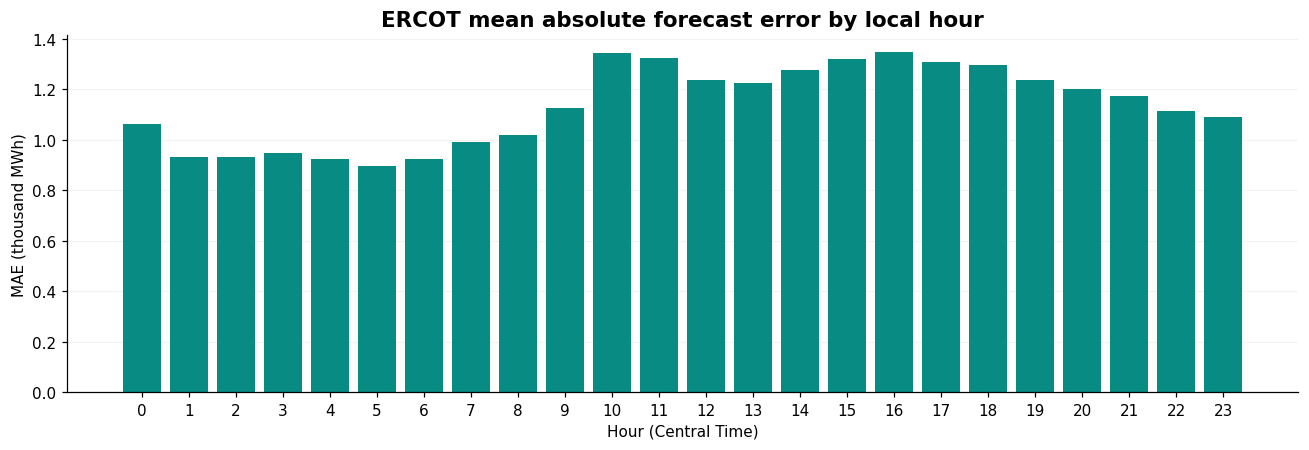

In [18]:
hourerr=shared.groupby('local_hour')['absolute_error_mwh'].mean()/1000
fig,ax=plt.subplots(figsize=(12,4.2))
ax.bar(hourerr.index,hourerr,color=TEAL)
ax.set(title='ERCOT mean absolute forecast error by local hour',
       xlabel='Hour (Central Time)',ylabel='MAE (thousand MWh)',xticks=range(24))
ax.grid(axis='y',alpha=.14);fig.tight_layout();finish_figure(fig,'F11_ercot_mae_by_hour.png')

**What I notice:** A single overall MAE hides when errors occur. The hourly bar chart makes the benchmark's average *error magnitude* visible across the clock. It uses only the **8,640 ERCOT-available test hours**, so it is not a claim about the whole 2022–2026 dataset or about Andrea's model-specific hourly performance.

**My hand-drawn redesign idea:** I sketched bars extending above and below a zero line. After reviewing the metric, I recognize that **this would represent signed error (bias), not MAE**. Since absolute errors cannot be negative, I would keep Figure F11 as an absolute-error comparison and use Figure F12 to explain overforecasting versus underforecasting.

**Question worth discussing:** Do the hours with larger MAE also have larger average demand, sharper hour-to-hour changes, or unusual seasonal conditions? We would need more analysis before naming a cause.

**Question:** How often does the benchmark overforecast or underforecast, and how does that differ from the size of its errors?

### Figure F12 — Ercot Mae And Bias
**Research question:** *How does benchmark forecast magnitude differ from signed bias?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

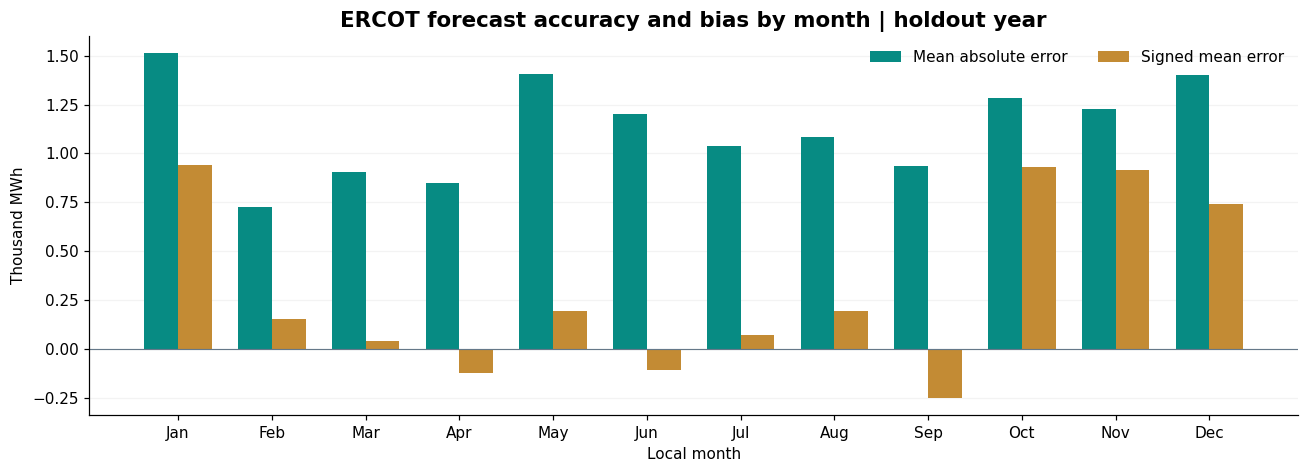

In [19]:
monthlyerr=shared.groupby('month').agg(
    MAE=('absolute_error_mwh','mean'),
    Bias=('forecast_error_mwh','mean')).reindex(range(1,13))/1000
fig,ax=plt.subplots(figsize=(12,4.4))
idx=np.arange(12);w=.36
ax.bar(idx-w/2,monthlyerr.MAE,width=w,color=TEAL,label='Mean absolute error')
ax.bar(idx+w/2,monthlyerr.Bias,width=w,color=ORANGE,label='Signed mean error')
ax.axhline(0,color=GREY,lw=.75);ax.set_xticks(idx,labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set(title='ERCOT forecast accuracy and bias by month | holdout year',
       ylabel='Thousand MWh',xlabel='Local month')
ax.legend(frameon=False,ncol=2);ax.grid(axis='y',alpha=.14)
fig.tight_layout();finish_figure(fig,'F12_ercot_mae_and_bias.png')

**Important interpretation:** Signed error is defined here as **forecast minus actual**. A positive monthly bias indicates overforecasting on average, while negative bias indicates underforecasting on average. The MAE bars cannot be negative. The two metrics describe different aspects of performance.

**What I learned from revising the visuals:** Opposite signed errors can cancel when averaged, so bias near zero does **not** mean the forecast is highly accurate. The MAE is needed to understand how large the typical misses remain.

**Presentation idea:** My positive/negative bar sketch may communicate bias more cleanly than a mixed chart, but I would preserve Figure F12's figure number if I redesign it. The present chart includes both monthly MAE and monthly signed bias for a side-by-side comparison.

**Question:** Does the benchmark's MAE rise dramatically during the highest-demand hours?

### Figure F13 — Ercot Peak Decile Mae
**Research question:** *Does ERCOT make larger misses during the highest-demand decile?*  
**Reading rule:** This figure is descriptive unless it explicitly shows forecast errors; patterns alone do not prove causation or model feature importance.

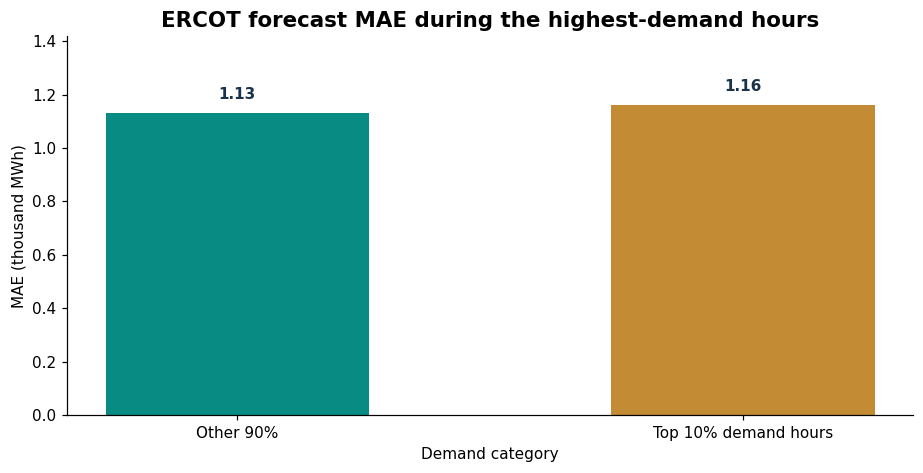

In [20]:
peakcut=shared.demand_mwh.quantile(.9)
shared['peak_decile']=np.where(shared.demand_mwh>=peakcut,'Top 10% demand hours','Other 90%')
pergroup=shared.groupby('peak_decile')['absolute_error_mwh'].mean().reindex(['Other 90%','Top 10% demand hours'])/1000
fig,ax=plt.subplots(figsize=(8.5,4.4))
bar=ax.bar(pergroup.index,pergroup.values,color=[TEAL,ORANGE],width=.52)
for b,v in zip(bar,pergroup):ax.text(b.get_x()+b.get_width()/2,v+.05,f'{v:.2f}',ha='center',weight='bold',color=DEEP)
ax.set(title='ERCOT forecast MAE during the highest-demand hours',
       ylabel='MAE (thousand MWh)',xlabel='Demand category')
ax.set_ylim(0,pergroup.max()*1.22);fig.tight_layout();finish_figure(fig,'F13_ercot_peak_decile_mae.png')

**What the result actually says:** During the shared holdout, ERCOT's MAE is about **1,132 MWh** outside the top demand decile and about **1,163 MWh** within it. That is a **modest difference**, not evidence of a dramatic breakdown in peak-hour forecasting.

**Why this matters to me:** I initially expected high demand to imply more difficult prediction. This chart shows why I should test an intuition instead of writing the conclusion beforehand. It is still useful to study peak-period errors, perhaps with percentage error, day-specific case studies, and team-model predictions.

**Retrospective-only condition:** The top 10% groups are created using the *actual outcome after the fact*, which is valid for evaluation. We could not use tomorrow's unknown actual demand to choose a forecast in real time.

**Question:** How did the project-developed methods perform against the simple baseline and ERCOT on the *same* hours?  
**Working presentation priority:** **5/5**, the main quantitative conclusion.

Identical-hour comparison (n = 8,640):


,Model,MAE,RMSE,MAPE,N
0,ERCOT day-ahead,1134.80,1594.34,2.00,8640
1,50/50 Hybrid,2005.85,2744.61,3.54,8640
2,Weather XGBoost,2476.68,3352.67,4.18,8640
3,XGBoost,2647.42,3544.65,4.52,8640
4,Rolling SARIMA,2661.58,3730.03,4.87,8640
5,Weather SARIMAX,2729.84,3823.10,4.99,8640
6,Seasonal naive,4205.29,5734.71,7.46,8640
7,Prophet,4846.27,6239.82,8.05,8640


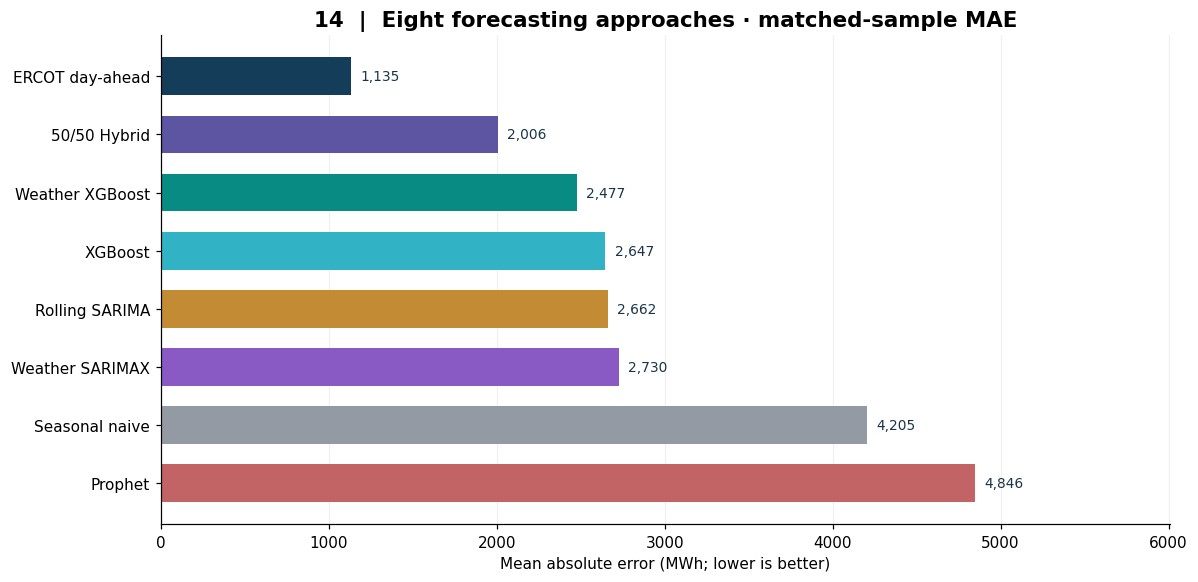

In [21]:
# Metrics are calculated from actual predictions, never hard-coded.
models=list(MODEL_NAMES)
common=preds.dropna(subset=models).copy()
assert len(common)==8640
rows=[]
for model in models:
    y=common['ACTUAL_DEMAND_MWH'].to_numpy(); q=common[model].to_numpy()
    err=y-q
    rows.append({'Model':MODEL_NAMES[model],'Code':model,
      'MAE':np.abs(err).mean(),'RMSE':np.sqrt(np.mean(err**2)),
      'MAPE':100*np.mean(np.abs(err/y)),'N':len(y)})
metrics=pd.DataFrame(rows).sort_values('MAE').reset_index(drop=True)
assert abs(metrics.loc[0,'MAE']-benchmark_mae)<.05
print('Identical-hour comparison (n = 8,640):')
display(metrics[['Model','MAE','RMSE','MAPE','N']].round(2))
fig,ax=plt.subplots(figsize=(11,5.4))
y=np.arange(len(metrics))
colors=[MODELCOLORS[k] for k in metrics.Code]
bars=ax.barh(y,metrics.MAE,color=colors,height=.65)
ax.set_yticks(y,metrics.Model);ax.invert_yaxis();ax.set_xlim(0,metrics.MAE.max()*1.24)
for b,v in zip(bars,metrics.MAE):
    ax.text(v+55,b.get_y()+b.get_height()/2,f'{v:,.0f}',va='center',fontsize=9,color=INK)
ax.set(title='14  |  Eight forecasting approaches · matched-sample MAE',
 xlabel='Mean absolute error (MWh; lower is better)')
ax.xaxis.grid(True)
finish_figure(fig,'F14_model_mae.png')

**Interpretation:** Recomputing all eight approaches on the 8,640 shared test hours shows ERCOT's day-ahead forecast remains best overall (~1,135 MWh MAE). The **50/50 hybrid is the strongest team model** (~2,006 MWh), followed by weather-enhanced XGBoost (~2,477 MWh). The forecast errors are real retrospective results, but differences in forecast-update schedules and feature availability prevent us from treating the exercise as a fully standardized operational benchmark until the audit is completed. The professional ERCOT forecast is not our model.

### Figure F15 — Model accuracy in relative terms
**Research question:** *Do our conclusions about forecasting models hold when error is expressed as a percentage of actual demand?*  
**Interpretation safeguard:** MAPE gives a unitless comparison on matched hours; it is not an estimate of electricity procurement cost.

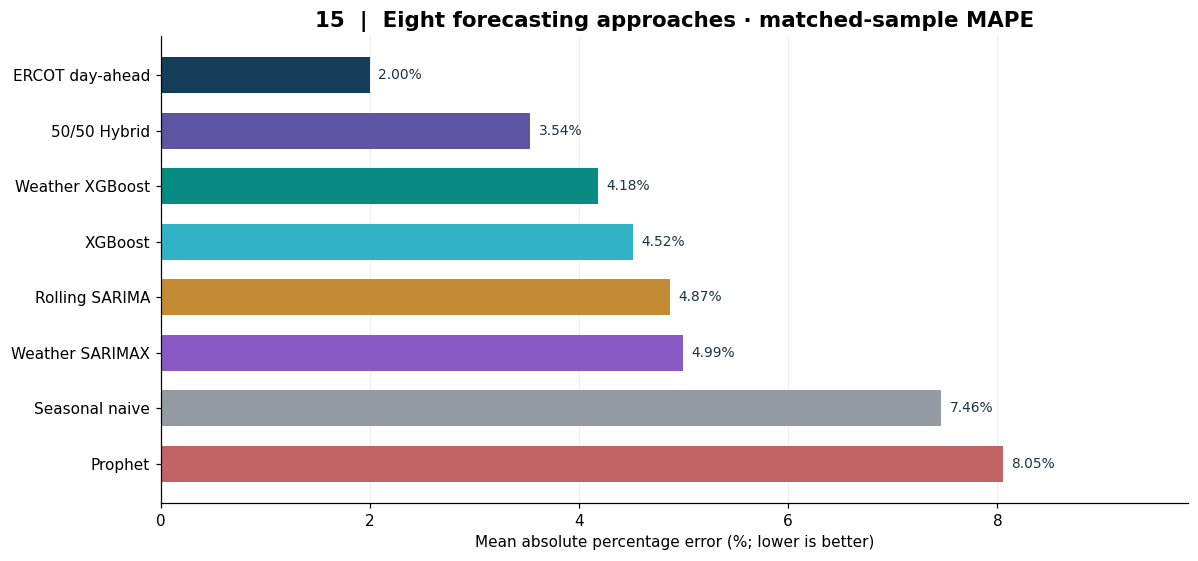

In [22]:
fig,ax=plt.subplots(figsize=(11,5.2))
y=np.arange(len(metrics));bars=ax.barh(y,metrics.MAPE,color=[MODELCOLORS[k] for k in metrics.Code],height=.65)
ax.set_yticks(y,metrics.Model);ax.invert_yaxis();ax.set_xlim(0,metrics.MAPE.max()*1.22)
for b,v in zip(bars,metrics.MAPE):
    ax.text(v+.08,b.get_y()+b.get_height()/2,f'{v:.2f}%',va='center',fontsize=9,color=INK)
ax.set(title='15  |  Eight forecasting approaches · matched-sample MAPE',
 xlabel='Mean absolute percentage error (%; lower is better)')
ax.xaxis.grid(True)
finish_figure(fig,'F15_model_mape.png')

**Interpretation:** MAPE expresses absolute misses relative to actual hourly demand. About **2.00%** for ERCOT, **3.54%** for the 50/50 hybrid, and **4.18%** for weather-enhanced XGBoost is easier to explain to a nontechnical audience than MWh alone. All eight approaches are measured on the same timestamps. A typical relative-error figure cannot stand in for the risk of large misses at extreme load.

## 5. From foundational charts to a concrete forecast story | F16

Andrea exported real hourly predictions for all seven of the team's model series, including the 50/50 hybrid, and ERCOT's benchmark is available on most hours. This is now a *required reproducible overlay*, not a speculative export request. The July case-study window contains unusually high actual demand; observing how lines diverge illustrates why aggregate metrics need to be complemented with diagnostic visuals.

In [23]:
# Forecast availability and missingness audit for the prediction table.
print('Prediction columns:', list(preds.columns))
print('Missing forecasts by model:')
display(preds[models].isna().sum().to_frame('Missing hours'))
print('The prediction CSV is already supplied. No model refitting or simulated predictions are needed.')

Prediction columns: ['TIMESTAMP', 'ACTUAL_DEMAND_MWH', 'ERCOT_DAY_AHEAD', 'SEASONAL_NAIVE', 'ROLLING_SARIMA', 'PROPHET', 'XGBOOST', 'WEATHER_SARIMAX', 'WEATHER_XGBOOST', 'HYBRID_50_50', 'timestamp_utc']
Missing forecasts by model:


,Missing hours
ERCOT_DAY_AHEAD,120
WEATHER_XGBOOST,0
XGBOOST,0
ROLLING_SARIMA,0
WEATHER_SARIMAX,0
SEASONAL_NAIVE,0
PROPHET,0
HYBRID_50_50,0


The prediction CSV is already supplied. No model refitting or simulated predictions are needed.


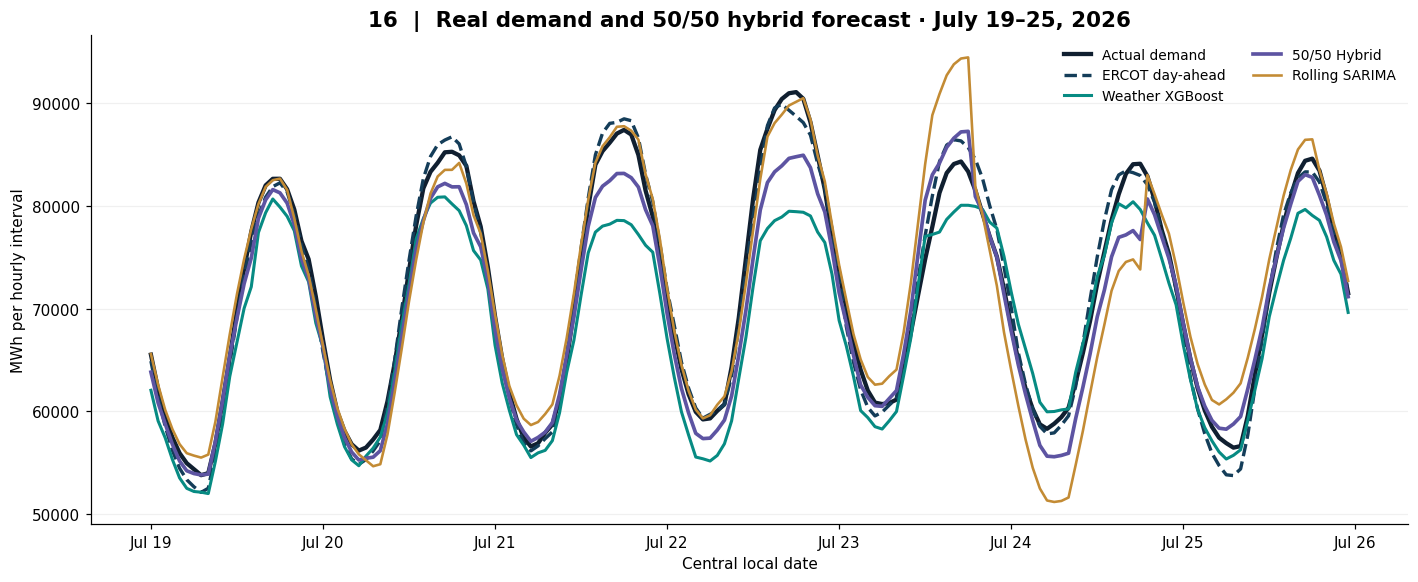

In [24]:
start=pd.Timestamp('2026-07-19',tz='America/Chicago').tz_convert('UTC')
end=pd.Timestamp('2026-07-26',tz='America/Chicago').tz_convert('UTC')
win=preds[(preds.timestamp_utc>=start)&(preds.timestamp_utc<end)].copy()
assert len(win)>=160, 'Case-study week not found in prediction export.'
local=win.timestamp_utc.dt.tz_convert('America/Chicago')
fig,ax=plt.subplots(figsize=(13,5.4))
for name,color,lw,ls in [('ACTUAL_DEMAND_MWH','#101F30',2.8,'-'),
 ('ERCOT_DAY_AHEAD',MODELCOLORS['ERCOT_DAY_AHEAD'],2.2,'--'),
 ('WEATHER_XGBOOST',MODELCOLORS['WEATHER_XGBOOST'],2.0,'-'),
 ('HYBRID_50_50',MODELCOLORS['HYBRID_50_50'],2.4,'-'),
 ('ROLLING_SARIMA',MODELCOLORS['ROLLING_SARIMA'],1.7,'-')]:
    ax.plot(local,win[name],label=('Actual demand' if name=='ACTUAL_DEMAND_MWH' else MODEL_NAMES[name]),
      color=color,lw=lw,ls=ls)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d',tz=local.dt.tz))
ax.set(title='16  |  Real demand and 50/50 hybrid forecast · July 19–25, 2026',
 ylabel='MWh per hourly interval',xlabel='Central local date')
ax.yaxis.grid(True);ax.legend(ncol=2,frameon=False,fontsize=9)
finish_figure(fig,'F16_july_forecast_overlay.png')

## 6. Advanced model diagnostics | F17–F20

These figures extend the earlier model comparison. The overall lowest-MAE method may not be the strongest at peak demand, and average scores conceal differences across the calendar and clock. **Every comparison in this section uses the same 8,640 timestamps** (including seven team models and ERCOT where observed).

We use cutoffs from **all 8,760 observed test-year hours** but compute MAE on 8,640 shared hours (88 of which are in the top 1%). Bins use **observed actual demand** because these are diagnostic groups. This is appropriate *after the event* but cannot be used by a future live forecaster to select the winning model before actual demand is known. The smallest category, the top 1%, has relatively few observations, so we report the counts.

In [25]:
# Shared evaluation table: UTC time, Central-local features and signed / absolute model errors.
eval_df = common.copy().sort_values('timestamp_utc').reset_index(drop=True)
eval_df['time_central'] = eval_df['timestamp_utc'].dt.tz_convert('America/Chicago')
eval_df['local_hour'] = eval_df['time_central'].dt.hour
eval_df['local_month'] = eval_df['time_central'].dt.month
for col in models:
    eval_df[f'error_{col}'] = eval_df[col] - eval_df['ACTUAL_DEMAND_MWH']
    eval_df[f'abs_{col}'] = eval_df[f'error_{col}'].abs()

bins = preds['ACTUAL_DEMAND_MWH'].quantile([.50, .90, .95, .99])
BIN_LABELS = ['Bottom 50%', '50–90%', '90–95%', '95–99%', 'Top 1%']
assert bins.is_monotonic_increasing and bins.is_unique
cutoffs = [-np.inf, *bins.tolist(), np.inf]
eval_df['demand_group'] = pd.cut(eval_df['ACTUAL_DEMAND_MWH'], bins=cutoffs,
                                  labels=BIN_LABELS, include_lowest=True)
counts = eval_df.groupby('demand_group', observed=True).size().reindex(BIN_LABELS)
assert counts.sum() == len(eval_df) and counts.loc['Top 1%'] == 88
display(pd.DataFrame({'Matched hours': counts.astype(int),
 'Share of matched hours (%)': (100*counts / len(eval_df)).round(2)}))
print('Actual-demand bin cutoffs (MWh):', bins.round(0).astype(int).to_dict())

,Matched hours,Share of matched hours (%)
demand_group,,
Bottom 50%,4334,50.16
50–90%,3456,40.00
90–95%,428,4.95
95–99%,334,3.87
Top 1%,88,1.02


Actual-demand bin cutoffs (MWh): {0.5: 55206, 0.9: 76966, 0.95: 82069, 0.99: 87966}


### Figure F17 — Accuracy across observed demand levels
**Business question:** Do our conclusions about model performance change during high-load hours?  
**Reading rule:** Lower is better. Colors preserve the team's original model assignments. Groups use actual demand, so the chart is **retrospective**, not a mechanism for choosing a model in real time.

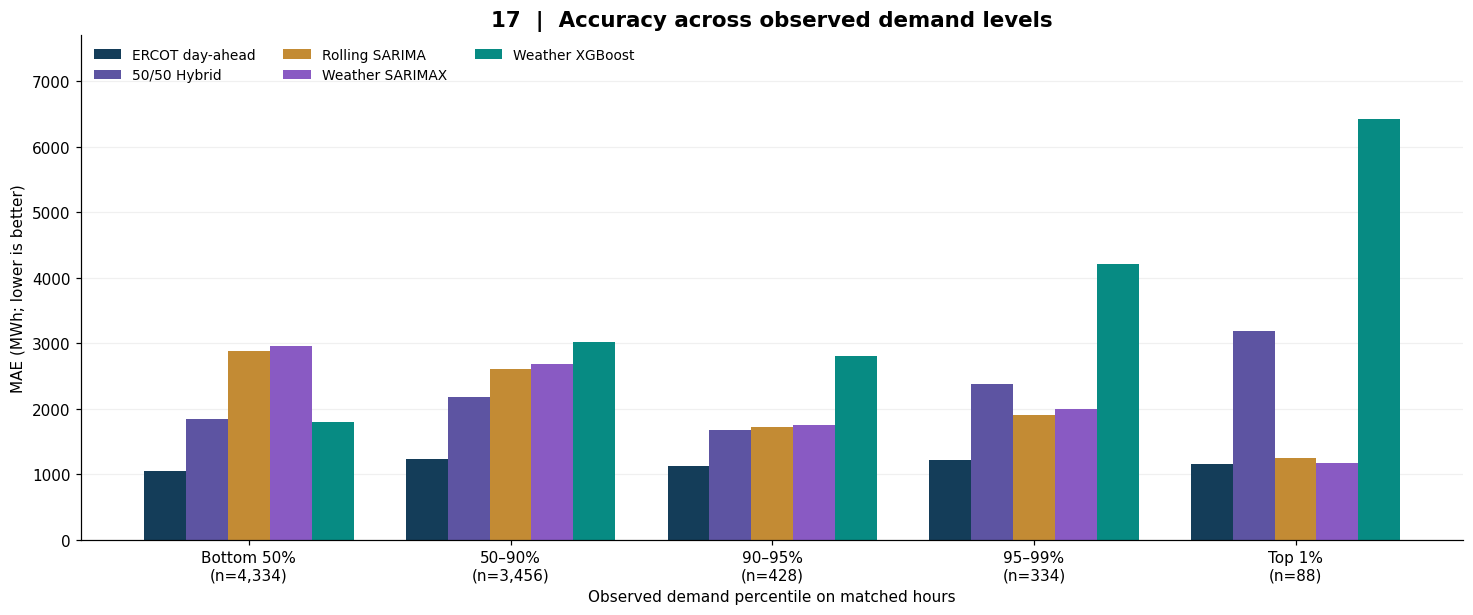

MAE (MWh) by demand level:


,ERCOT day-ahead,50/50 Hybrid,Rolling SARIMA,Weather SARIMAX,Weather XGBoost
demand_group,,,,,
Bottom 50%,1052.0,1843.0,2883.0,2952.0,1801.0
50–90%,1232.0,2183.0,2611.0,2682.0,3014.0
90–95%,1120.0,1682.0,1717.0,1756.0,2814.0
95–99%,1222.0,2385.0,1898.0,2004.0,4216.0
Top 1%,1158.0,3189.0,1242.0,1176.0,6421.0


In [26]:
# Original Figure 09 question rebuilt directly from the provided hourly prediction table.
focus = ['ERCOT_DAY_AHEAD','HYBRID_50_50','ROLLING_SARIMA','WEATHER_SARIMAX','WEATHER_XGBOOST']
by_group = (eval_df.groupby('demand_group',observed=True)
            [[f'abs_{c}' for c in focus]].mean().reindex(BIN_LABELS))
fig,ax=plt.subplots(figsize=(13.5,5.7))
x=np.arange(len(BIN_LABELS)); width=.16
for j,col in enumerate(focus):
    bars=ax.bar(x+(j-(len(focus)-1)/2)*width,by_group[f'abs_{col}'],width,
                color=MODELCOLORS[col],label=MODEL_NAMES[col])
ax.set_xticks(x,[f'{name}\n(n={counts[name]:,})' for name in BIN_LABELS])
ax.set(title='17  |  Accuracy across observed demand levels',ylabel='MAE (MWh; lower is better)',
       xlabel='Observed demand percentile on matched hours')
ax.legend(ncol=3,frameon=False,loc='upper left',fontsize=9)
ax.yaxis.grid(True)
ax.set_ylim(0,by_group.max().max()*1.20)
finish_figure(fig,'F17_accuracy_by_demand_level.png')
print('MAE (MWh) by demand level:')
display(by_group.rename(columns={f'abs_{c}':MODEL_NAMES[c] for c in focus}).round(0))

In [27]:
s_top = by_group.loc['Top 1%',f'abs_ROLLING_SARIMA']
w_top = by_group.loc['Top 1%',f'abs_WEATHER_XGBOOST']
s_low = by_group.loc['Bottom 50%',f'abs_ROLLING_SARIMA']
w_low = by_group.loc['Bottom 50%',f'abs_WEATHER_XGBOOST']
display(Markdown(f"""**What surprised me:** Weather XGBoost has the lower MAE in the bottom half
of demand hours ({w_low:,.0f} versus {s_low:,.0f} MWh), but Rolling SARIMA is much better
in the observed top 1% ({s_top:,.0f} versus {w_top:,.0f} MWh, n={counts['Top 1%']}).
The exported hybrid does improve annual MAE, but SARIMA-family models remain stronger at these peak hours. It does **not**
establish that we can identify actual peak hours ahead of time, nor does a small extreme-hour
sample prove that SARIMA will always be stronger on future peaks."""))

**What surprised me:** Weather XGBoost has the lower MAE in the bottom half
of demand hours (1,801 versus 2,883 MWh), but Rolling SARIMA is much better
in the observed top 1% (1,242 versus 6,421 MWh, n=88).
The exported hybrid does improve annual MAE, but SARIMA-family models remain stronger at these peak hours. It does **not**
establish that we can identify actual peak hours ahead of time, nor does a small extreme-hour
sample prove that SARIMA will always be stronger on future peaks.

### Figure F18 — Typical errors by local hour
**Question:** Are model differences concentrated at particular times of day?  
**Limitation:** Local hours are descriptive groups; they do not control for season, temperature, or demand level.

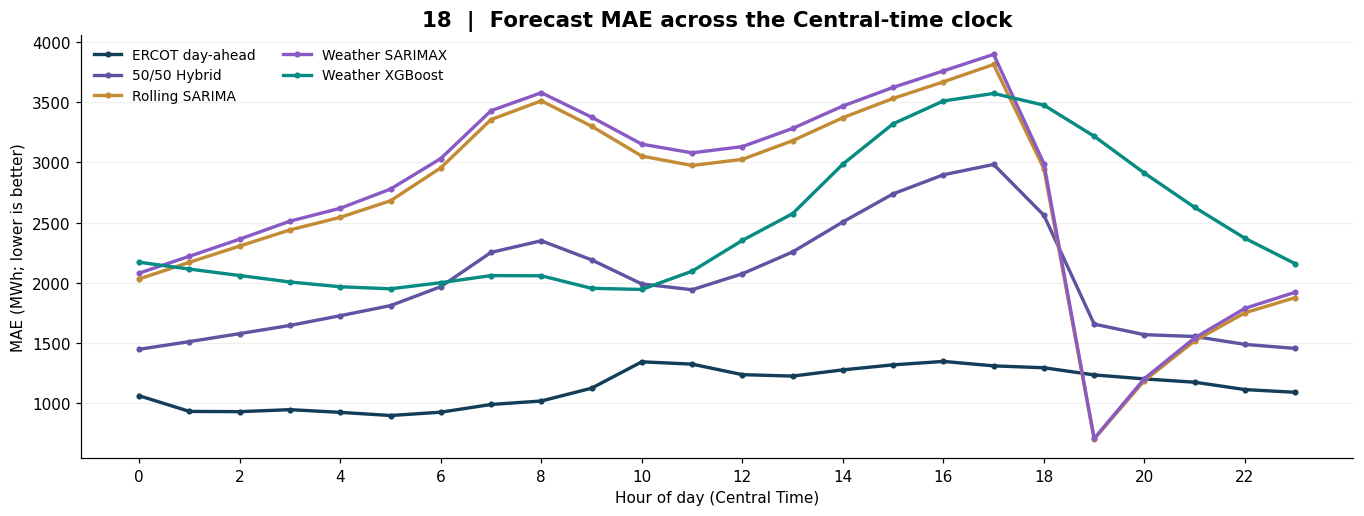

In [28]:
hourly = eval_df.groupby('local_hour')[[f'abs_{c}' for c in focus]].mean()
fig,ax=plt.subplots(figsize=(12.5,4.8))
for col in focus:
    ax.plot(hourly.index,hourly[f'abs_{col}'],label=MODEL_NAMES[col],
            color=MODELCOLORS[col],lw=2.2,marker='o',ms=3)
ax.set(title='18  |  Forecast MAE across the Central-time clock',
       xlabel='Hour of day (Central Time)',ylabel='MAE (MWh; lower is better)',xticks=range(0,24,2))
ax.legend(frameon=False,ncol=2,fontsize=9);ax.yaxis.grid(True)
finish_figure(fig,'F18_model_mae_by_local_hour.png')

### Figure F19 — Seasonal stability of model error
**Question:** Does a strong annual average obscure months where a model struggles?  
**Definition:** Calendar months are derived from each hour's Central-local timestamp. The test is one year; this is not a multi-year model-stability claim.

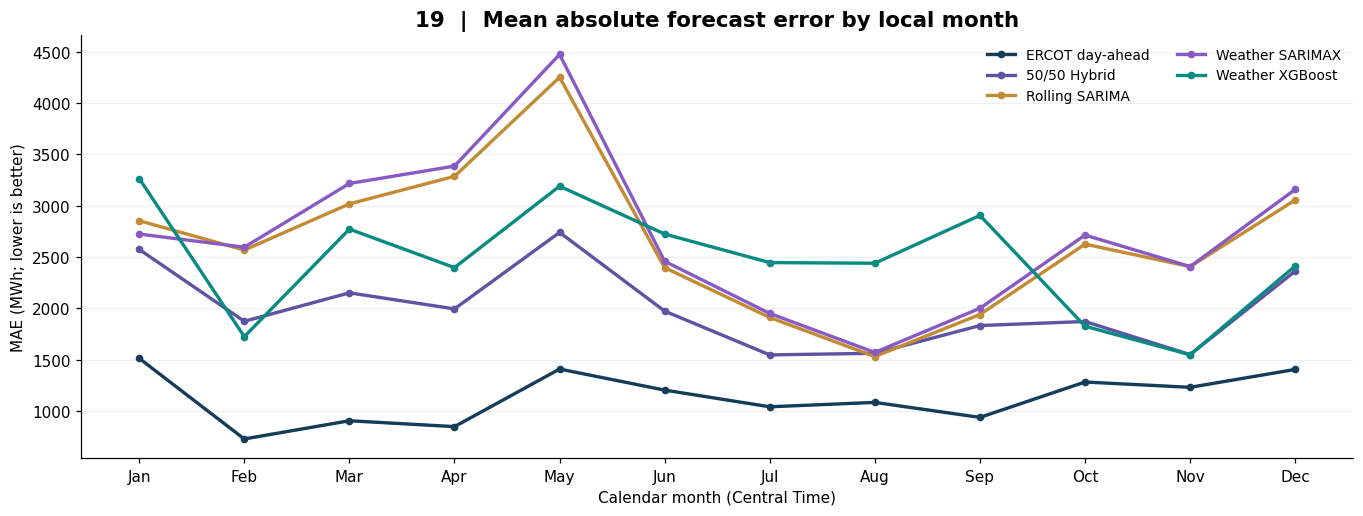

In [29]:
monthly_model = eval_df.groupby('local_month')[[f'abs_{c}' for c in focus]].mean()
fig,ax=plt.subplots(figsize=(12.5,4.8))
for col in focus:
    ax.plot(monthly_model.index,monthly_model[f'abs_{col}'],label=MODEL_NAMES[col],
            color=MODELCOLORS[col],lw=2.2,marker='o',ms=4)
ax.set(title='19  |  Mean absolute forecast error by local month',
       xlabel='Calendar month (Central Time)',ylabel='MAE (MWh; lower is better)',xticks=range(1,13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.legend(frameon=False,ncol=2,fontsize=9);ax.yaxis.grid(True)
finish_figure(fig,'F19_monthly_model_error.png')

### Figure F20 — Do Rolling SARIMA and Weather XGBoost make similar mistakes?

Plot **signed** errors (forecast minus actual) for each of the same hours. If both models make nearly identical errors, averaging offers little opportunity for cancellation. If their mistakes differ, an ensemble *might* improve accuracy. The correlation is an empirical diagnostic, **not** a guarantee of better results. The axes cross at zero, so points on opposite-sign quadrants indicate hours where one model overpredicted while the other underpredicted.

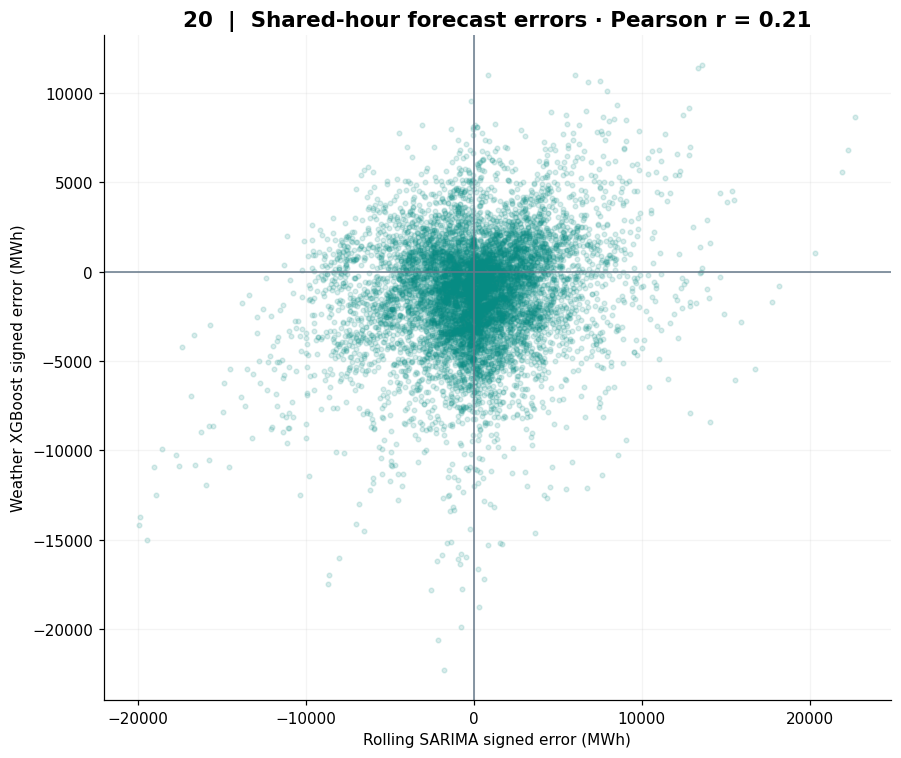

**Finding:** Their signed-error correlation is **0.213** across
8,640 matched hours. They fall on opposite sides of zero for
approximately **46.6%** of hours. I think this is the strongest reason
to **test** a combined forecast rather than assume their strengths cannot work together.
Error cancellation is possible, but it must be measured by a genuine MAE calculation.

In [30]:
err_s = eval_df['error_ROLLING_SARIMA'].to_numpy()
err_w = eval_df['error_WEATHER_XGBOOST'].to_numpy()
r = np.corrcoef(err_s,err_w)[0,1]
opposite = np.mean(np.sign(err_s) != np.sign(err_w))*100
fig,ax=plt.subplots(figsize=(8.3,7))
ax.scatter(err_s,err_w,s=9,alpha=.15,color=TEAL,rasterized=True)
ax.axvline(0,color=GREY,lw=1);ax.axhline(0,color=GREY,lw=1)
ax.set(title=f'20  |  Shared-hour forecast errors · Pearson r = {r:.2f}',
       xlabel='Rolling SARIMA signed error (MWh)',
       ylabel='Weather XGBoost signed error (MWh)')
ax.xaxis.grid(True,alpha=.13);ax.yaxis.grid(True,alpha=.13)
finish_figure(fig,'F20_sarima_weather_xgb_error_scatter.png')
display(Markdown(f"""**Finding:** Their signed-error correlation is **{r:.3f}** across
{len(eval_df):,} matched hours. They fall on opposite sides of zero for
approximately **{opposite:.1f}%** of hours. I think this is the strongest reason
to **test** a combined forecast rather than assume their strengths cannot work together.
Error cancellation is possible, but it must be measured by a genuine MAE calculation."""))

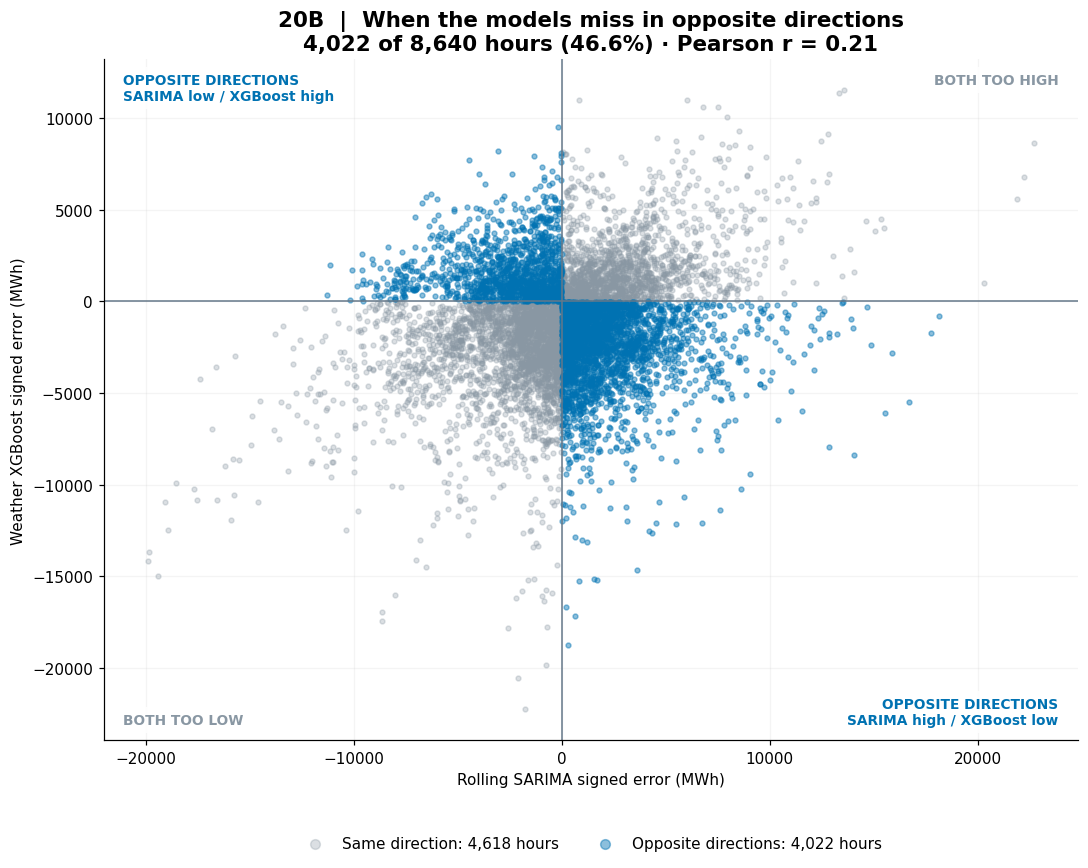


**Finding:** Each dot represents one matched hour, combining both models’
errors. Blue points show the **4,022 hours
(46.6%)** when one model predicted above actual demand
while the other predicted below it.

Signed error means **forecast minus actual**: positive is too high;
negative is too low. Opposite errors can partly offset when averaged,
but this chart alone does not establish that combining forecasts improves
accuracy. That must be tested using the combined forecast’s actual MAE.


In [45]:
err_s = eval_df['error_ROLLING_SARIMA'].to_numpy(dtype=float)
err_w = eval_df['error_WEATHER_XGBOOST'].to_numpy(dtype=float)

# Keep only hours with valid errors from both models.
valid = np.isfinite(err_s) & np.isfinite(err_w)
err_s, err_w = err_s[valid], err_w[valid]

r = np.corrcoef(err_s, err_w)[0, 1]

# Exact-zero errors are separate from opposite-direction errors.
opposite_mask = (
    ((err_s < 0) & (err_w > 0)) |
    ((err_s > 0) & (err_w < 0))
)
same_mask = (
    ((err_s < 0) & (err_w < 0)) |
    ((err_s > 0) & (err_w > 0))
)
zero_mask = (err_s == 0) | (err_w == 0)

n = len(err_s)
opposite_pct = opposite_mask.mean() * 100
BLUE = '#0072B2'
MUTED_GREY = '#8997A3'

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    err_s[same_mask], err_w[same_mask],
    s=10, alpha=.30, color=MUTED_GREY, rasterized=True,
    label=f'Same direction: {same_mask.sum():,} hours'
)
ax.scatter(
    err_s[opposite_mask], err_w[opposite_mask],
    s=10, alpha=.45, color=BLUE, rasterized=True,
    label=f'Opposite directions: {opposite_mask.sum():,} hours'
)

if zero_mask.any():
    ax.scatter(
        err_s[zero_mask], err_w[zero_mask],
        s=20, marker='x', color='black',
        label=f'At least one exact-zero error: {zero_mask.sum():,} hours'
    )

ax.axvline(0, color=GREY, lw=1)
ax.axhline(0, color=GREY, lw=1)

ax.set(
    title=(
        '20B  |  When the models miss in opposite directions\n'
        f'{opposite_mask.sum():,} of {n:,} hours '
        f'({opposite_pct:.1f}%) · Pearson r = {r:.2f}'
    ),
    xlabel='Rolling SARIMA signed error (MWh)',
    ylabel='Weather XGBoost signed error (MWh)'
)

# Direct labels explain what each quadrant means.
for x, y, text, color, ha, va in [
    (.02, .98, 'OPPOSITE DIRECTIONS\nSARIMA low / XGBoost high',
     BLUE, 'left', 'top'),
    (.98, .98, 'BOTH TOO HIGH',
     MUTED_GREY, 'right', 'top'),
    (.02, .02, 'BOTH TOO LOW',
     MUTED_GREY, 'left', 'bottom'),
    (.98, .02, 'OPPOSITE DIRECTIONS\nSARIMA high / XGBoost low',
     BLUE, 'right', 'bottom')
]:
    ax.text(
        x, y, text, transform=ax.transAxes,
        ha=ha, va=va, fontsize=9, fontweight='bold', color=color,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.90, pad=4)
    )

ax.grid(True, alpha=.13)
ax.set_axisbelow(True)
ax.legend(
    loc='upper center', bbox_to_anchor=(.5, -.12),
    ncol=2, frameon=False, markerscale=2
)

fig.tight_layout()
finish_figure(fig, 'F20B_opposite_direction_errors.png')

display(Markdown(f"""
**Finding:** Each dot represents one matched hour, combining both models’
errors. Blue points show the **{opposite_mask.sum():,} hours
({opposite_pct:.1f}%)** when one model predicted above actual demand
while the other predicted below it.

Signed error means **forecast minus actual**: positive is too high;
negative is too low. Opposite errors can partly offset when averaged,
but this chart alone does not establish that combining forecasts improves
accuracy. That must be tested using the combined forecast’s actual MAE.
"""))

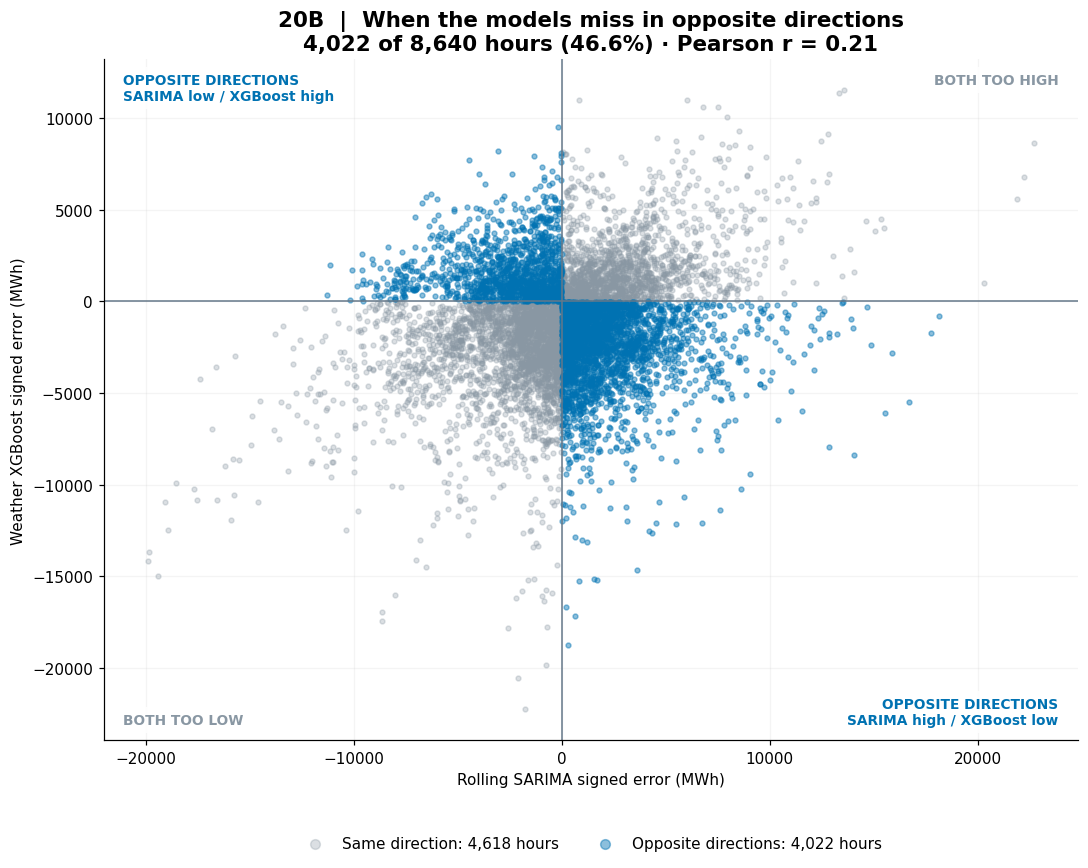


**Finding:** Each dot represents one matched hour, combining both models’
errors. Blue points show the **4,022 hours
(46.6%)** when one model predicted above actual demand
while the other predicted below it.

Signed error means **forecast minus actual**: positive is too high;
negative is too low. Opposite errors can partly offset when averaged,
but this chart alone does not establish that combining forecasts improves
accuracy. That must be tested using the combined forecast’s actual MAE.


In [31]:
err_s = eval_df['error_ROLLING_SARIMA'].to_numpy(dtype=float)
err_w = eval_df['error_WEATHER_XGBOOST'].to_numpy(dtype=float)

# Keep only hours with valid errors from both models.
valid = np.isfinite(err_s) & np.isfinite(err_w)
err_s, err_w = err_s[valid], err_w[valid]

r = np.corrcoef(err_s, err_w)[0, 1]

# Exact-zero errors are separate from opposite-direction errors.
opposite_mask = (
    ((err_s < 0) & (err_w > 0)) |
    ((err_s > 0) & (err_w < 0))
)
same_mask = (
    ((err_s < 0) & (err_w < 0)) |
    ((err_s > 0) & (err_w > 0))
)
zero_mask = (err_s == 0) | (err_w == 0)

n = len(err_s)
opposite_pct = opposite_mask.mean() * 100
BLUE = '#0072B2'
MUTED_GREY = '#8997A3'

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    err_s[same_mask], err_w[same_mask],
    s=10, alpha=.30, color=MUTED_GREY, rasterized=True,
    label=f'Same direction: {same_mask.sum():,} hours'
)
ax.scatter(
    err_s[opposite_mask], err_w[opposite_mask],
    s=10, alpha=.45, color=BLUE, rasterized=True,
    label=f'Opposite directions: {opposite_mask.sum():,} hours'
)

if zero_mask.any():
    ax.scatter(
        err_s[zero_mask], err_w[zero_mask],
        s=20, marker='x', color='black',
        label=f'At least one exact-zero error: {zero_mask.sum():,} hours'
    )

ax.axvline(0, color=GREY, lw=1)
ax.axhline(0, color=GREY, lw=1)

ax.set(
    title=(
        '20B  |  When the models miss in opposite directions\n'
        f'{opposite_mask.sum():,} of {n:,} hours '
        f'({opposite_pct:.1f}%) · Pearson r = {r:.2f}'
    ),
    xlabel='Rolling SARIMA signed error (MWh)',
    ylabel='Weather XGBoost signed error (MWh)'
)

# Direct labels explain what each quadrant means.
for x, y, text, color, ha, va in [
    (.02, .98, 'OPPOSITE DIRECTIONS\nSARIMA low / XGBoost high',
     BLUE, 'left', 'top'),
    (.98, .98, 'BOTH TOO HIGH',
     MUTED_GREY, 'right', 'top'),
    (.02, .02, 'BOTH TOO LOW',
     MUTED_GREY, 'left', 'bottom'),
    (.98, .02, 'OPPOSITE DIRECTIONS\nSARIMA high / XGBoost low',
     BLUE, 'right', 'bottom')
]:
    ax.text(
        x, y, text, transform=ax.transAxes,
        ha=ha, va=va, fontsize=9, fontweight='bold', color=color,
        bbox=dict(facecolor='white', edgecolor='none', alpha=.90, pad=4)
    )

ax.grid(True, alpha=.13)
ax.set_axisbelow(True)
ax.legend(
    loc='upper center', bbox_to_anchor=(.5, -.12),
    ncol=2, frameon=False, markerscale=2
)

fig.tight_layout()
finish_figure(fig, 'F20B_opposite_direction_errors.png')

display(Markdown(f"""
**Finding:** Each dot represents one matched hour, combining both models’
errors. Blue points show the **{opposite_mask.sum():,} hours
({opposite_pct:.1f}%)** when one model predicted above actual demand
while the other predicted below it.

Signed error means **forecast minus actual**: positive is too high;
negative is too low. Opposite errors can partly offset when averaged,
but this chart alone does not establish that combining forecasts improves
accuracy. That must be tested using the combined forecast’s actual MAE.
"""))

## 7. Official 50/50 hybrid and exploratory alternative weights | F21–F25

### What I wanted to test

Andrea has now included the fixed 50/50 hybrid in the team prediction CSV, and it ranks first among the team models across the matched test year. The additional **weight-tuning experiment below is exploratory**, conducted after seeing the model forecasts. The demand-level plot originally motivated a specific question: *If Rolling SARIMA and Weather XGBoost make different errors, could a blended prediction be more accurate than either one on its own?*

We **do not retrain** Andrea's original models. For each shared target hour, define

\\[
\\widehat{y}_{\\mathrm{blend},t} = w\\,\\widehat{y}_{\\mathrm{SARIMA},t}+(1-w)\\,\\widehat{y}_{\\mathrm{WeatherXGB},t}
\\]

where `w` is the Rolling SARIMA weight (0 = entirely Weather XGBoost, 1 = entirely Rolling SARIMA). We compare **(a) a fixed 50/50 average**, which needs no tuning, with **(b) a weighted average selected using an earlier chronological segment**.

### Safeguards before evaluating the combination

- **Earlier analysis / weight selection:** October 1, 2025–March 31, 2026 (UTC).  
- **Later assessment:** April 1–September 30, 2026 (UTC).  
- Both periods include only hours where **all eight** forecast series are present.  
- The weight is selected only with earlier actual demand and earlier forecasts; the later period **cannot** influence the chosen weight.  
- These are two portions of Andrea's **already-exported evaluation year**. Consequently the later score is a held-out *ensemble-weight comparison*, not a new external test set for the base models, and cannot resolve historical training overlap or issue-time leakage.  
- **Operational limitation:** Observed weather, original model forecast origins, and predictors' issuance availability require Andrea's modeling-level verification. These are model-comparison experiments, **not** deployable 24-hour-ahead forecasts.

We include the ERCOT benchmark for context. The blend should be evaluated against the stronger component model **and ERCOT**, not just against an easy baseline.

In [32]:
# Chronological partition; time chosen before searching the weight grid.
SPLIT = pd.Timestamp('2026-04-01', tz='UTC')
earlier = eval_df.loc[eval_df.timestamp_utc < SPLIT].copy()
later = eval_df.loc[eval_df.timestamp_utc >= SPLIT].copy()
assert len(earlier) > 0 and len(later) > 0
assert earlier.timestamp_utc.max() < later.timestamp_utc.min()
assert len(earlier)+len(later)==len(eval_df)
WEIGHTS=np.linspace(0,1,101)
def blend(frame, weight):
    return weight*frame['ROLLING_SARIMA']+(1-weight)*frame['WEATHER_XGBOOST']
def mae(frame, prediction):
    return float(np.mean(np.abs(frame['ACTUAL_DEMAND_MWH']-prediction)))
def rmse(frame, prediction):
    return float(np.sqrt(np.mean((frame['ACTUAL_DEMAND_MWH']-prediction)**2)))
def mape(frame, prediction):
    return float(100*np.mean(np.abs(frame['ACTUAL_DEMAND_MWH']-prediction)/frame['ACTUAL_DEMAND_MWH']))
weight_mae=np.array([mae(earlier,blend(earlier,w)) for w in WEIGHTS])
best_weight=float(WEIGHTS[np.argmin(weight_mae)])
print(f'Earlier hours (used for blend-weight choice): {len(earlier):,}')
print(f'Later hours (reserved for checking the chosen blend): {len(later):,}')
print(f'Earlier-selected Rolling SARIMA weight: {best_weight:.2f}; Weather XGBoost weight: {1-best_weight:.2f}')
assert 0 <= best_weight <= 1
for frame in (earlier,later):
    frame['BLEND_EQUAL'] = frame['HYBRID_50_50']
    assert np.allclose(frame['BLEND_EQUAL'],blend(frame,0.5))
    frame['BLEND_SELECTED'] = blend(frame,best_weight)
    frame['actual_group'] = pd.cut(frame.ACTUAL_DEMAND_MWH,
            bins=cutoffs,labels=BIN_LABELS,include_lowest=True)

Earlier hours (used for blend-weight choice): 4,320
Later hours (reserved for checking the chosen blend): 4,320
Earlier-selected Rolling SARIMA weight: 0.36; Weather XGBoost weight: 0.64


### Figure F21 — How the blend's validation MAE changes with its weight
**Question:** Is it worth combining the forecasts, and how sensitive is the earlier-period result to weighting?  
**Metric:** Earlier-period MAE; lower is better. The *later* data do not appear in this plot, preventing weight selection based on the final comparison.

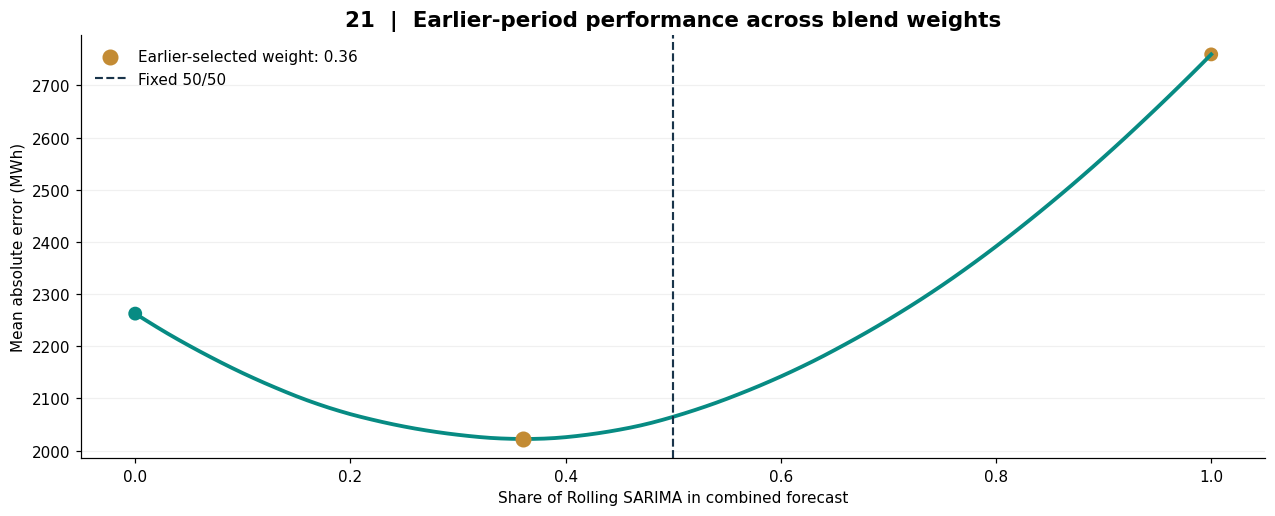

In [33]:
fig,ax=plt.subplots(figsize=(11.7,4.8))
ax.plot(WEIGHTS,weight_mae,color=TEAL,lw=2.5)
ax.scatter([best_weight],[weight_mae.min()],color=ORANGE,s=90,zorder=4,label=f'Earlier-selected weight: {best_weight:.2f}')
ax.axvline(.5,color=DEEP,ls='--',lw=1.4,label='Fixed 50/50')
ax.scatter([0,1],[weight_mae[0],weight_mae[-1]],color=[MODELCOLORS['WEATHER_XGBOOST'],MODELCOLORS['ROLLING_SARIMA']],s=65)
ax.set(title='21  |  Earlier-period performance across blend weights',
       xlabel='Share of Rolling SARIMA in combined forecast',ylabel='Mean absolute error (MWh)')
ax.legend(frameon=False);ax.yaxis.grid(True)
finish_figure(fig,'F21_blend_weight_sensitivity.png')

### Figure F22 — Test the idea on later hours without retuning

This is the main hybrid-experiment comparison. We evaluate the **fixed 50/50 blend** and the **earlier-selected weight** alongside the component models and ERCOT. It is important that we present both choices: the later period might favor the fixed blend even if the tuned weights looked better earlier.

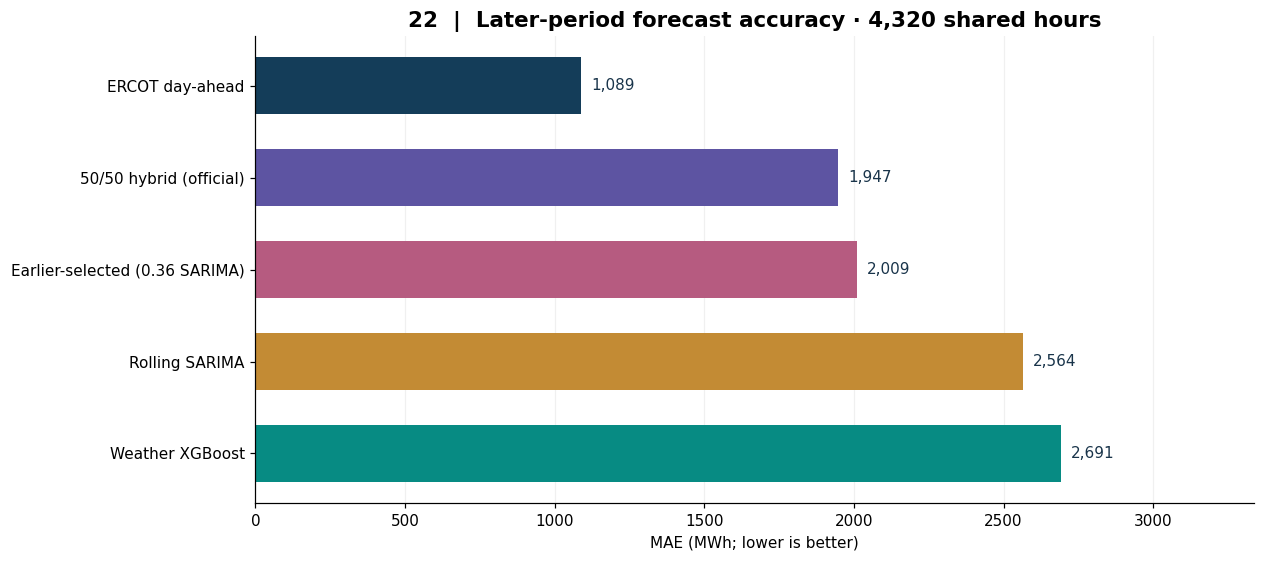

,Period,Method,Hours,MAE,RMSE,MAPE
0,Earlier: weight selection,ERCOT day-ahead,4320,1181.05,1705.96,2.28
1,Earlier: weight selection,Rolling SARIMA,4320,2759.26,3673.81,5.45
2,Earlier: weight selection,Weather XGBoost,4320,2262.53,3217.71,4.25
3,Earlier: weight selection,50/50 hybrid (official),4320,2064.82,2805.61,4.00
4,Earlier: weight selection,Earlier-selected (0.36 SARIMA),4320,2022.33,2783.74,3.88
5,Later: assessment,ERCOT day-ahead,4320,1088.54,1474.31,1.72
6,Later: assessment,Rolling SARIMA,4320,2563.89,3785.41,4.28
7,Later: assessment,Weather XGBoost,4320,2690.83,3482.41,4.11
8,Later: assessment,50/50 hybrid (official),4320,1946.88,2682.23,3.07
9,Later: assessment,Earlier-selected (0.36 SARIMA),4320,2009.17,2712.77,3.10


In [34]:
comparisons=[('ERCOT day-ahead', 'ERCOT_DAY_AHEAD',MODELCOLORS['ERCOT_DAY_AHEAD']),
             ('Rolling SARIMA','ROLLING_SARIMA',MODELCOLORS['ROLLING_SARIMA']),
             ('Weather XGBoost','WEATHER_XGBOOST',MODELCOLORS['WEATHER_XGBOOST']),
             ('50/50 hybrid (official)','BLEND_EQUAL',MODELCOLORS['HYBRID_50_50']),
             (f'Earlier-selected ({best_weight:.2f} SARIMA)','BLEND_SELECTED','#B65B80')]
rows=[]
for phase,frame in [('Earlier: weight selection',earlier),('Later: assessment',later)]:
    for label,col,color in comparisons:
        rows.append({'Period':phase,'Method':label,'Column':col,'Color':color,
                     'Hours':len(frame),'MAE':mae(frame,frame[col]),
                     'RMSE':rmse(frame,frame[col]),'MAPE':mape(frame,frame[col])})
summary_compare=pd.DataFrame(rows)
fig,ax=plt.subplots(figsize=(11.6,5.2))
selected=summary_compare.query("Period == 'Later: assessment'").sort_values('MAE')
bars=ax.barh(selected.Method,selected.MAE,color=selected.Color,height=.62)
ax.invert_yaxis();ax.set_xlim(0,selected.MAE.max()*1.24)
for b,v in zip(bars,selected.MAE):
    ax.text(v+35,b.get_y()+b.get_height()/2,f'{v:,.0f}',va='center',color=INK)
ax.set(title=f'22  |  Later-period forecast accuracy · {len(later):,} shared hours',
       xlabel='MAE (MWh; lower is better)')
ax.xaxis.grid(True)
finish_figure(fig,'F22_later_period_model_and_blend_mae.png')
display(summary_compare[['Period','Method','Hours','MAE','RMSE','MAPE']].round(2))

In [35]:
later_metrics=summary_compare.loc[summary_compare.Period=='Later: assessment'].set_index('Column')
bl_mae=later_metrics.loc['BLEND_EQUAL','MAE']; be_mae=later_metrics.loc['BLEND_SELECTED','MAE']
wx_mae=later_metrics.loc['WEATHER_XGBOOST','MAE']; sa_mae=later_metrics.loc['ROLLING_SARIMA','MAE']
ercot_mae=later_metrics.loc['ERCOT_DAY_AHEAD','MAE']
versus_best=100*(1-bl_mae/min(wx_mae,sa_mae))
display(Markdown(f"""**My interpretation:** On the later {len(later):,} common hours, the **fixed
50/50 blend** has an MAE of **{bl_mae:,.0f} MWh**, compared with **{sa_mae:,.0f}**
for Rolling SARIMA and **{wx_mae:,.0f}** for Weather XGBoost. That is about
**{versus_best:.1f}%** lower MAE than the stronger individual model on this same
later period. The earlier-selected blend has an MAE of **{be_mae:,.0f} MWh**.
Importantly, the operator's benchmark still performs better (**{ercot_mae:,.0f} MWh**),
and the blend has not passed a prospective forecast-origin/feature-availability audit.
This is an encouraging exploratory result, not a claim that we beat ERCOT."""))

**My interpretation:** On the later 4,320 common hours, the **fixed
50/50 blend** has an MAE of **1,947 MWh**, compared with **2,564**
for Rolling SARIMA and **2,691** for Weather XGBoost. That is about
**24.1%** lower MAE than the stronger individual model on this same
later period. The earlier-selected blend has an MAE of **2,009 MWh**.
Importantly, the operator's benchmark still performs better (**1,089 MWh**),
and the blend has not passed a prospective forecast-origin/feature-availability audit.
This is an encouraging exploratory result, not a claim that we beat ERCOT.

### Figure F23 — Does the later-period blend help across demand levels?

Evaluate the fixed and earlier-selected blends against both component models, **on the later segment only**. Demand bins use the *full 8,760-hour test year's observed demand cutoffs* defined in F17 to keep the visual categories stable. The small top-demand group is descriptive and should not guide direct operational model switching.

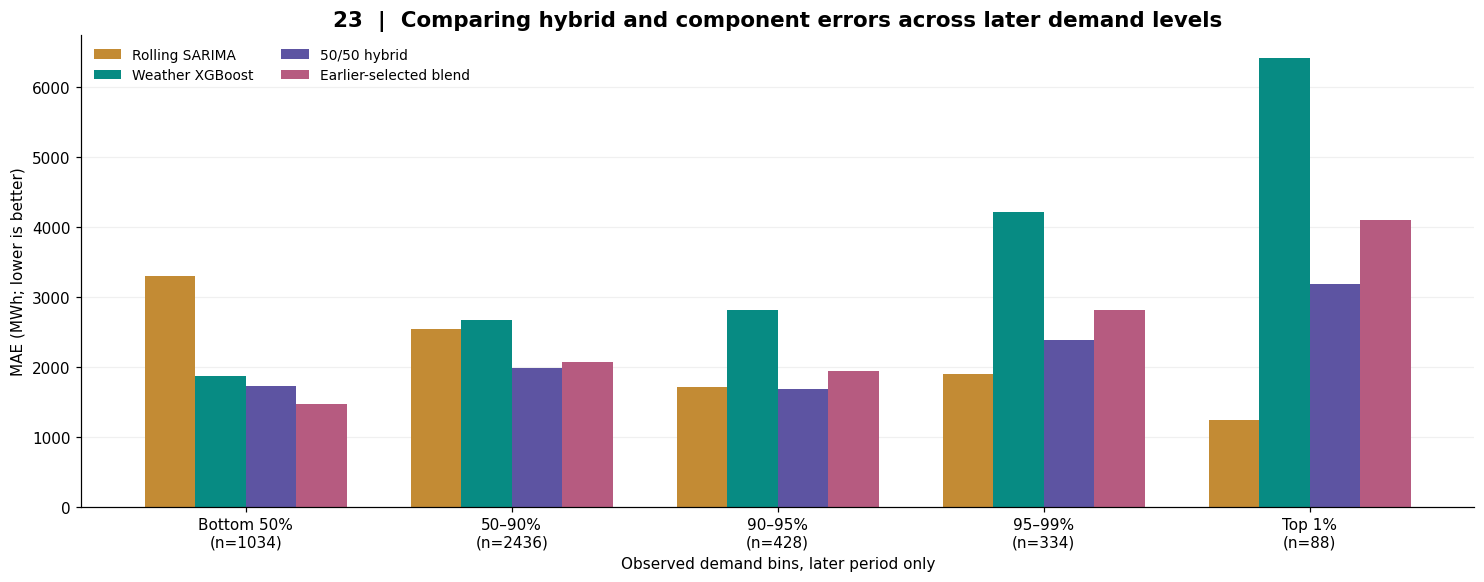

,Rolling SARIMA,Weather XGBoost,50/50 hybrid,Earlier-selected blend
Bottom 50%,3302.0,1868.0,1724.0,1472.0
50–90%,2539.0,2675.0,1983.0,2064.0
90–95%,1717.0,2814.0,1682.0,1937.0
95–99%,1898.0,4216.0,2385.0,2819.0
Top 1%,1242.0,6421.0,3189.0,4094.0


In [36]:
laterfocus=[('ROLLING_SARIMA','Rolling SARIMA',MODELCOLORS['ROLLING_SARIMA']),
            ('WEATHER_XGBOOST','Weather XGBoost',MODELCOLORS['WEATHER_XGBOOST']),
            ('BLEND_EQUAL','50/50 hybrid',MODELCOLORS['HYBRID_50_50']),
            ('BLEND_SELECTED','Earlier-selected blend','#B65B80')]
bylater=pd.DataFrame(index=BIN_LABELS)
for col,lab,_ in laterfocus:
    bylater[lab] = (later.assign(err=np.abs(later[col]-later.ACTUAL_DEMAND_MWH))
                         .groupby('actual_group',observed=True).err.mean().reindex(BIN_LABELS))
countlater=later.groupby('actual_group',observed=True).size().reindex(BIN_LABELS,fill_value=0)
fig,ax=plt.subplots(figsize=(13.6,5.4))
x=np.arange(len(BIN_LABELS)); width=.19
for j,(_,label,color) in enumerate(laterfocus):
    ax.bar(x+(j-1.5)*width,bylater[label].values,width,label=label,color=color)
ax.set_xticks(x,[f'{g}\n(n={countlater[g]})' for g in BIN_LABELS]);ax.yaxis.grid(True)
ax.set(title='23  |  Comparing hybrid and component errors across later demand levels',
       ylabel='MAE (MWh; lower is better)',xlabel='Observed demand bins, later period only')
ax.legend(frameon=False,ncol=2,fontsize=9)
finish_figure(fig,'F23_later_hybrid_by_demand_levels.png')
display(bylater.round(0))

### Figure F24 — A concrete forecast case study

We return to the same **July 19–25, 2026 (Central Time)** week used in F10/F16, now adding the **fixed blend**. Looking at one high-load week can reveal how averages hide shape and timing errors, but it cannot substitute for the full evaluation.

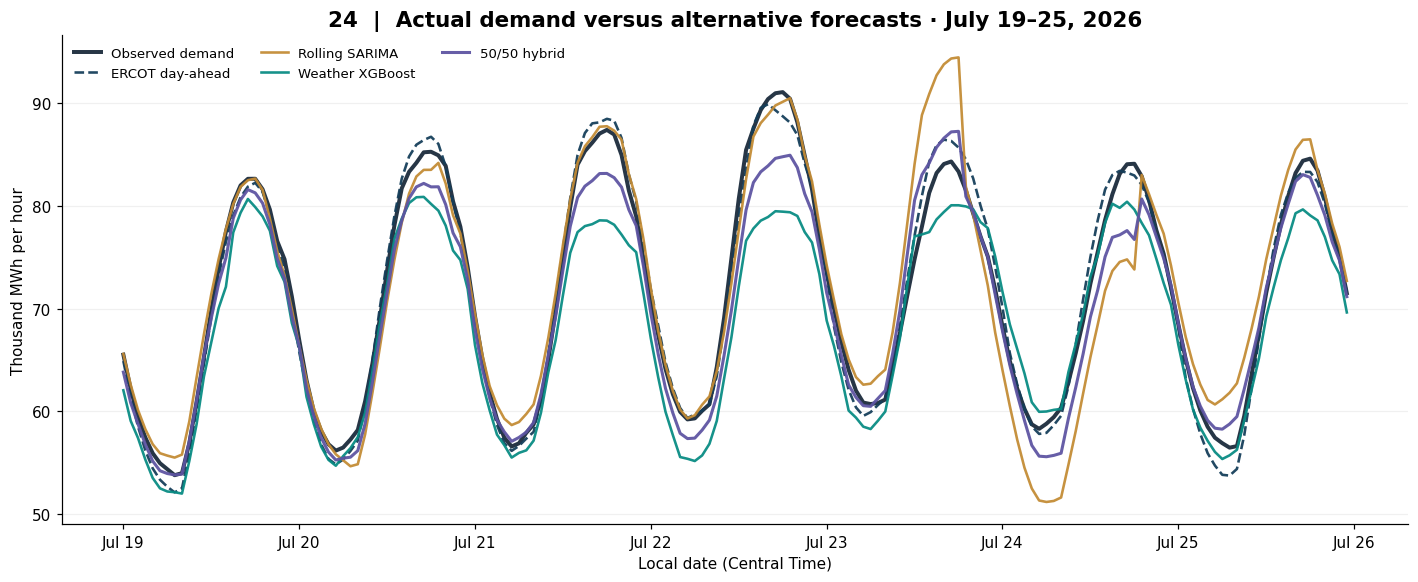

In [37]:
case_start=pd.Timestamp('2026-07-19',tz='America/Chicago').tz_convert('UTC')
case_end=pd.Timestamp('2026-07-26',tz='America/Chicago').tz_convert('UTC')
week=later[(later.timestamp_utc>=case_start)&(later.timestamp_utc<case_end)].copy()
assert 150<len(week)<=170,'Case study week is absent or has unexpectedly few shared hours.'
tm=week.timestamp_utc.dt.tz_convert('America/Chicago')
fig,ax=plt.subplots(figsize=(13,5.4))
for col,label,color,lw,ls in [
 ('ACTUAL_DEMAND_MWH','Observed demand','#19293A',2.6,'-'),
 ('ERCOT_DAY_AHEAD','ERCOT day-ahead',MODELCOLORS['ERCOT_DAY_AHEAD'],1.7,'--'),
 ('ROLLING_SARIMA','Rolling SARIMA',MODELCOLORS['ROLLING_SARIMA'],1.7,'-'),
 ('WEATHER_XGBOOST','Weather XGBoost',MODELCOLORS['WEATHER_XGBOOST'],1.7,'-'),
 ('HYBRID_50_50','50/50 hybrid',MODELCOLORS['HYBRID_50_50'],2.0,'-')]:
    ax.plot(tm,week[col]/1000,label=label,lw=lw,ls=ls,color=color,alpha=.94)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d',tz=tm.dt.tz))
ax.set(title='24  |  Actual demand versus alternative forecasts · July 19–25, 2026',
       xlabel='Local date (Central Time)',ylabel='Thousand MWh per hour')
ax.legend(ncol=3,frameon=False,fontsize=8.7);ax.yaxis.grid(True)
finish_figure(fig,'F24_july_week_hybrid_overlay.png')

### Figure F25 — How often does the 50/50 blend reduce forecast error?

This chart shows the percentage of later-period hours for which the fixed blend's **absolute error** is lower than Rolling SARIMA's, Weather XGBoost's, or **both models'** errors. These are descriptive rates, not a rule for choosing tomorrow's model. Overall MAE can improve even when the blend is not the best choice for a majority of individual hours.

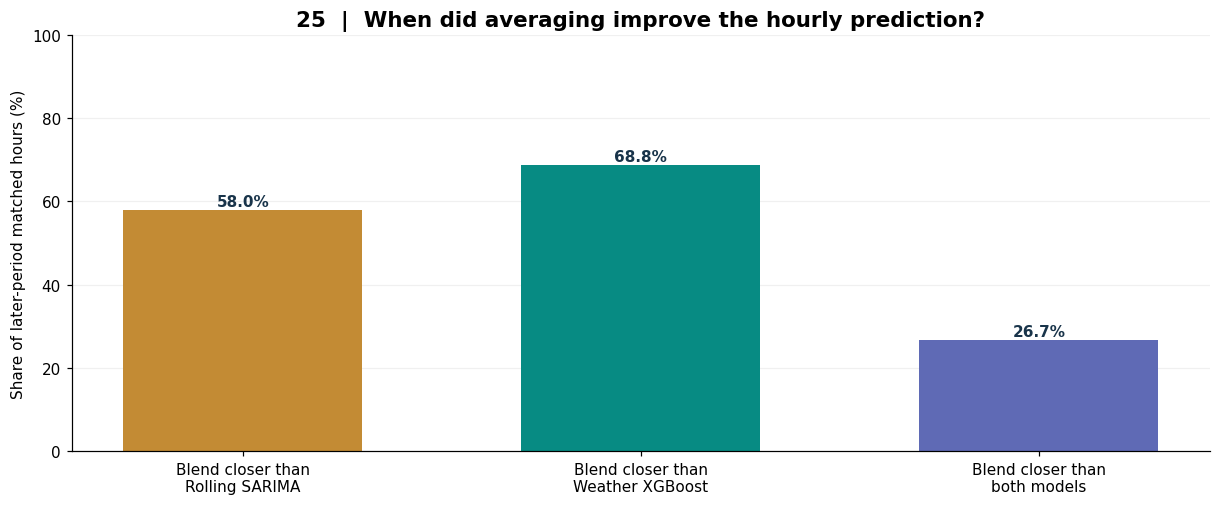

**What I take from this:** The fixed blend is closer to observed demand than
both components on **26.7%** of later hours. Its overall MAE still
improves because large error reductions can outweigh hours where blending is worse.
An impossible-to-know-in-advance "oracle" choice of the better model for each hour
would be stronger than a forecast using only advance-known information; we therefore
**do not** report that oracle as a candidate forecasting strategy.

In [38]:
# Per-hour comparison to the ORACLE (best of the two component errors).
# NOTE: This is intentionally a hard-to-beat retrospective diagnostic, NOT a tradable comparator.
comp_best = np.minimum(np.abs(later.ROLLING_SARIMA-later.ACTUAL_DEMAND_MWH),
                       np.abs(later.WEATHER_XGBOOST-later.ACTUAL_DEMAND_MWH))
bl_error = np.abs(later.BLEND_EQUAL-later.ACTUAL_DEMAND_MWH)
mean_adv = np.mean(comp_best-bl_error)
blend_better_both=(bl_error<comp_best).mean()*100
versus_s=np.mean(bl_error<np.abs(later.ROLLING_SARIMA-later.ACTUAL_DEMAND_MWH))*100
versus_w=np.mean(bl_error<np.abs(later.WEATHER_XGBOOST-later.ACTUAL_DEMAND_MWH))*100
fig,ax=plt.subplots(figsize=(11.2,4.7))
labels=['Blend closer than\nRolling SARIMA','Blend closer than\nWeather XGBoost',
        'Blend closer than\nboth models']
vals=[versus_s,versus_w,blend_better_both]
bars=ax.bar(labels,vals,color=[MODELCOLORS['ROLLING_SARIMA'],MODELCOLORS['WEATHER_XGBOOST'],'#5F6AB5'],width=.6)
for b,v in zip(bars,vals):
    ax.text(b.get_x()+b.get_width()/2,v+1,f'{v:.1f}%',ha='center',fontweight='bold',color=INK)
ax.set(title='25  |  When did averaging improve the hourly prediction?',
       ylabel='Share of later-period matched hours (%)',ylim=(0,100))
ax.yaxis.grid(True);finish_figure(fig,'F25_blend_hourly_win_rates.png')
display(Markdown(f"""**What I take from this:** The fixed blend is closer to observed demand than
both components on **{blend_better_both:.1f}%** of later hours. Its overall MAE still
improves because large error reductions can outweigh hours where blending is worse.
An impossible-to-know-in-advance "oracle" choice of the better model for each hour
would be stronger than a forecast using only advance-known information; we therefore
**do not** report that oracle as a candidate forecasting strategy."""))

## 8. MAE average divergence: when is a model stronger or weaker than its own typical performance? | F26–F33

**The idea from my note cards:** Instead of stopping at a model's *overall* MAE, use that value as a constant reference and ask whether the model's mean absolute error increases or decreases during a specific hour, month, or season. This changes the conversation from simply ranking methods to examining **when each model is reliable**.

**Definitions (for each model separately, using the same 8,640 target hours):**

- **Overall MAE:** mean of absolute errors on all matched evaluation hours. It is a **descriptive average reference**, not a forecast.
- **Period MAE:** mean absolute error during the specified hour, month, or season.
- **Absolute divergence in MWh:** period MAE − overall MAE. **Positive = worse than usual; negative = better than usual.**
- **Percent improvement vs own overall MAE:** 100 × (overall MAE − period MAE) / overall MAE. **Positive = better than usual; negative = worse.**
- **Forecast skill vs seasonal-naive:** 100 × (1 − model period MAE / seasonal-naive period MAE). **Positive = better than the simple baseline in that same period.**
- **Error gap vs ERCOT:** model period MAE − ERCOT period MAE. **Positive = worse than ERCOT in that same period.**

A model that is 20% *better than its own annual average* might still be less accurate than another model. That is why Figures F32 and F14 retain **real forecast baseline** and operator comparisons. Groups use the same matched hours and derive the period labels from Central local time; this analysis is retrospective. Calendar months in the 12-month evaluation span are grouped by local month, not by UTC month.

### F26–F27 | Hour-by-hour divergence

The dashed line represents each model’s own overall MAE. Shading and positive/negative percentage differences show which hours consistently present larger or smaller absolute forecast misses. The two panels have separate reference lines because the models have different overall errors.

Matched hourly observations: 8,640
Overall MAE reference in MWh:
ERCOT day-ahead    1134.8
50/50 Hybrid       2005.8
Weather XGBoost    2476.7
XGBoost            2647.4
Rolling SARIMA     2661.6
Weather SARIMAX    2729.8
Seasonal naive     4205.3
Prophet            4846.3
By season:
           n  ROLLING_SARIMA  WEATHER_XGBOOST  ERCOT_DAY_AHEAD  SEASONAL_NAIVE
season                                                                        
Winter  2112          2829.0           2493.0           1227.0          4647.0
Spring  2207          3521.0           2790.0           1055.0          5237.0
Summer  2160          1950.0           2536.0           1108.0          3556.0
Fall    2161          2331.0           2080.0           1153.0          3368.0
Min cell n month-hour 28 Season-hour 88


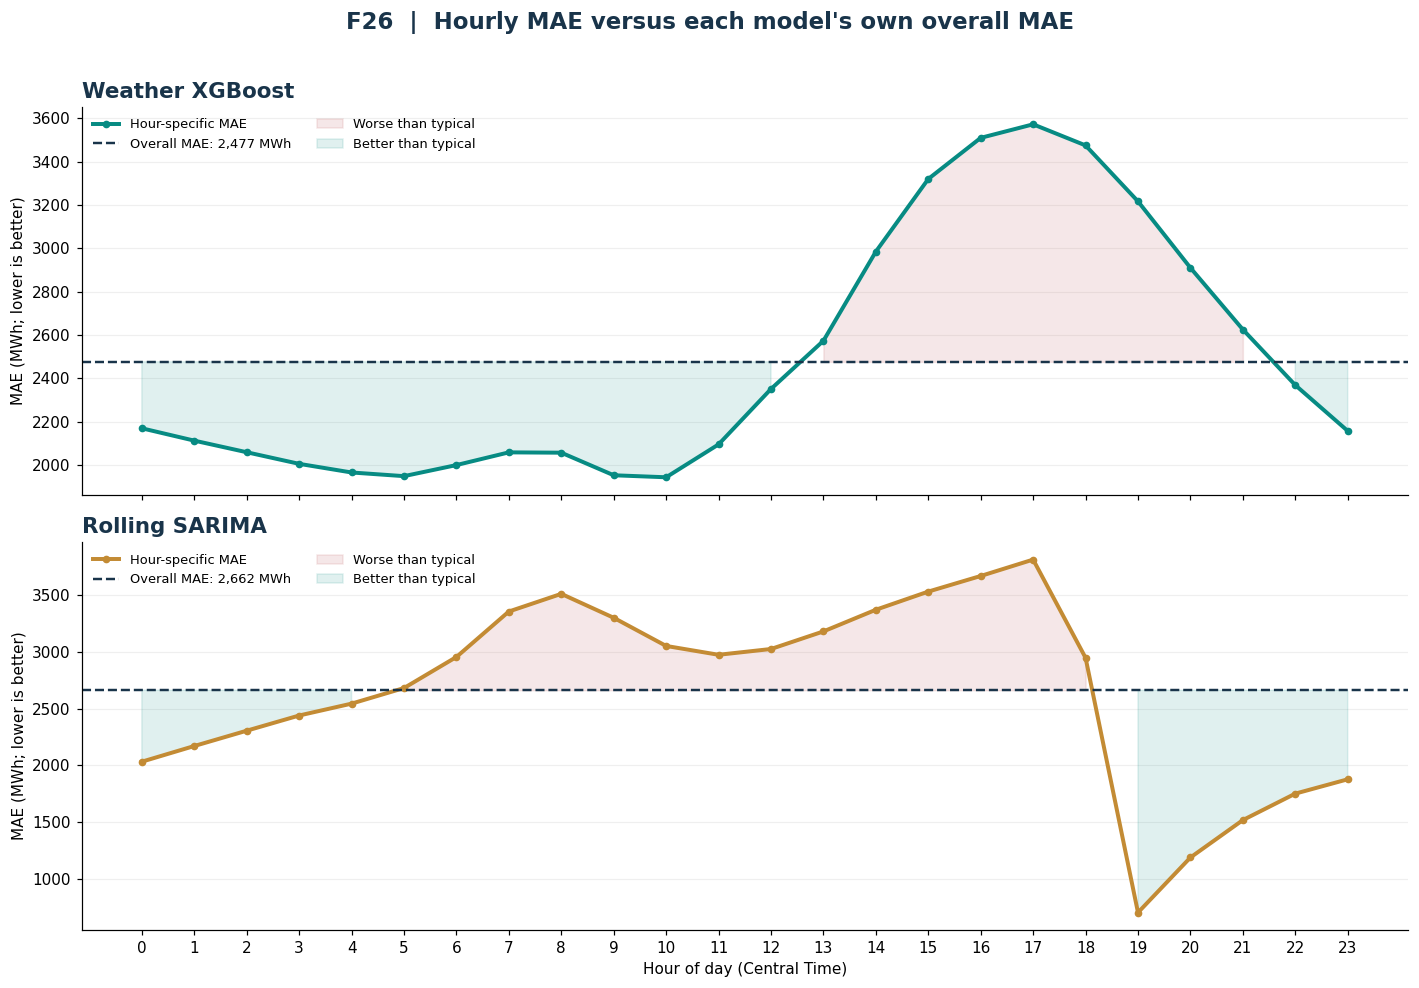

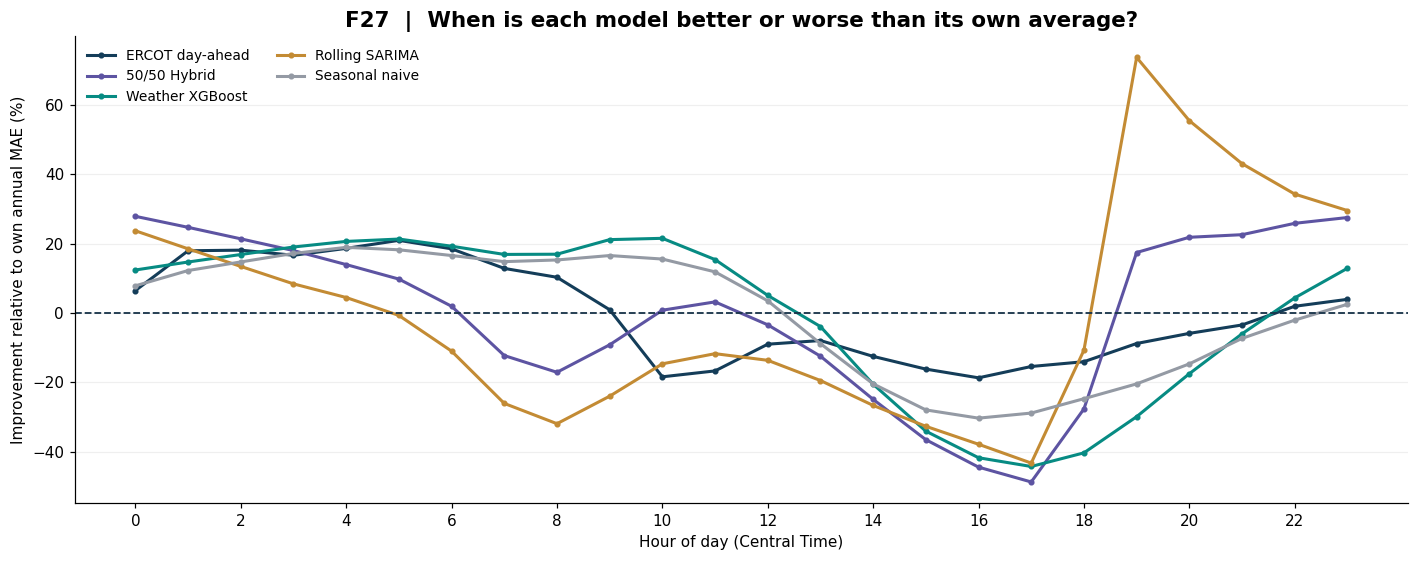

In [39]:
# --- Cell A: Common sample and overall MAE references ---
ALL_MODELS=list(MODEL_NAMES)
MAE_MODELS=['ERCOT_DAY_AHEAD','HYBRID_50_50','WEATHER_XGBOOST','ROLLING_SARIMA','SEASONAL_NAIVE']
mae_frame = eval_df.copy().sort_values('timestamp_utc')
mae_frame['central_time'] = mae_frame['timestamp_utc'].dt.tz_convert('America/Chicago')
mae_frame['local_hour'] = mae_frame['central_time'].dt.hour
mae_frame['local_month'] = mae_frame['central_time'].dt.month
mae_frame['local_date'] = mae_frame['central_time'].dt.date
season_lookup = {12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Fall',10:'Fall',11:'Fall'}
SEASONS = ['Winter','Spring','Summer','Fall']
mae_frame['season'] = pd.Categorical(mae_frame['local_month'].map(season_lookup), categories=SEASONS, ordered=True)

for model in ALL_MODELS:
    mae_frame[f'abs_{model}'] = (mae_frame[model]-mae_frame['ACTUAL_DEMAND_MWH']).abs()

OVERALL_MAE = {model:mae_frame[f'abs_{model}'].mean() for model in ALL_MODELS}
assert len(mae_frame)==8640
assert (mae_frame[[f'abs_{m}' for m in ALL_MODELS]] >= 0).all().all()

# A conditional group's error is compared against the SAME MODEL's entire-sample MAE.
# A separate skill measure compares forecasts with the seasonal-naive predictions
# on exactly the same hours, avoiding any change in the comparison sample.
def mae_by(*keys):
    groups = mae_frame.groupby(list(keys), observed=True)
    summary = groups.agg(n=('ACTUAL_DEMAND_MWH','size'),
                          **{model:(f'abs_{model}','mean') for model in ALL_MODELS})
    for model in ALL_MODELS:
        summary[f'delta_{model}'] = summary[model]-OVERALL_MAE[model]
        summary[f'improve_{model}'] = 100*(OVERALL_MAE[model]-summary[model])/OVERALL_MAE[model]
        summary[f'skill_{model}'] = 100*(1-summary[model]/summary['SEASONAL_NAIVE'])
        summary[f'gap_ercot_{model}'] = summary[model]-summary['ERCOT_DAY_AHEAD']
    return summary

by_hour = mae_by('local_hour').reindex(range(24))
by_month = mae_by('local_month').reindex(range(1,13))
by_season = mae_by('season').reindex(SEASONS)
by_month_hour = mae_by('local_month','local_hour')
by_season_hour = mae_by('season','local_hour')
assert by_hour.n.sum()==by_month.n.sum()==by_season.n.sum()==len(mae_frame)
assert (by_hour.n>0).all() and (by_month.n>0).all() and (by_season.n>0).all()

print(f'Matched hourly observations: {len(mae_frame):,}')
print('Overall MAE reference in MWh:')
print(pd.Series(OVERALL_MAE).rename(index=MODEL_NAMES).round(1).sort_values().to_string())
print('By season:')
print(by_season[['n','ROLLING_SARIMA','WEATHER_XGBOOST','ERCOT_DAY_AHEAD', 'SEASONAL_NAIVE']].round(0).to_string())
print('Min cell n month-hour',by_month_hour.n.min(),'Season-hour',by_season_hour.n.min())

def mae_figure(fig,name):
    finish_figure(fig,name)


# --- Cell B: Hour-of-day reference and % change ---
fig,axes=plt.subplots(2,1,figsize=(13,8.8),sharex=True)
for ax,model in zip(axes,['WEATHER_XGBOOST','ROLLING_SARIMA']):
    ax.plot(by_hour.index,by_hour[model],color=MODELCOLORS[model],lw=2.6,marker='o',ms=4,label='Hour-specific MAE')
    ax.axhline(OVERALL_MAE[model],color=INK,linestyle='--',lw=1.6,label=f'Overall MAE: {OVERALL_MAE[model]:,.0f} MWh')
    ax.fill_between(by_hour.index,by_hour[model],OVERALL_MAE[model],where=(by_hour[model]>OVERALL_MAE[model]),color=RED,alpha=.15,label='Worse than typical')
    ax.fill_between(by_hour.index,by_hour[model],OVERALL_MAE[model],where=(by_hour[model]<OVERALL_MAE[model]),color=TEAL,alpha=.12,label='Better than typical')
    ax.set_title(MODEL_NAMES[model],loc='left',color=INK)
    ax.set_ylabel('MAE (MWh; lower is better)')
    ax.grid(axis='y',alpha=.2)
    ax.legend(ncol=2,fontsize=8.5,frameon=False,loc='upper left')
axes[-1].set_xlabel('Hour of day (Central Time)')
axes[-1].set_xticks(range(0,24))
fig.suptitle('F26  |  Hourly MAE versus each model\'s own overall MAE',color=INK,fontweight='bold',fontsize=15,y=1.015)
mae_figure(fig,'F26_hourly_MAE_against_overall.png')

fig,ax=plt.subplots(figsize=(13,5.2))
for model in MAE_MODELS:
    ax.plot(by_hour.index,by_hour[f'improve_{model}'],label=MODEL_NAMES[model],color=MODELCOLORS[model],lw=2,marker='o',markersize=3)
ax.axhline(0,color=INK,ls='--',lw=1.2)
ax.set(xticks=range(0,24,2),xlabel='Hour of day (Central Time)',ylabel='Improvement relative to own annual MAE (%)',title='F27  |  When is each model better or worse than its own average?')
ax.legend(frameon=False,ncol=2,fontsize=9)
ax.grid(axis='y',alpha=.2)
mae_figure(fig,'F27_hourly_percent_better_worse.png')



### F28–F29 | Monthly and seasonal divergence

These figures reveal whether an overall score masks months or entire seasons where a model is less accurate. Each comparison is relative to that **same model’s own overall MAE**; the sample counts are shown for the seasonal groups.

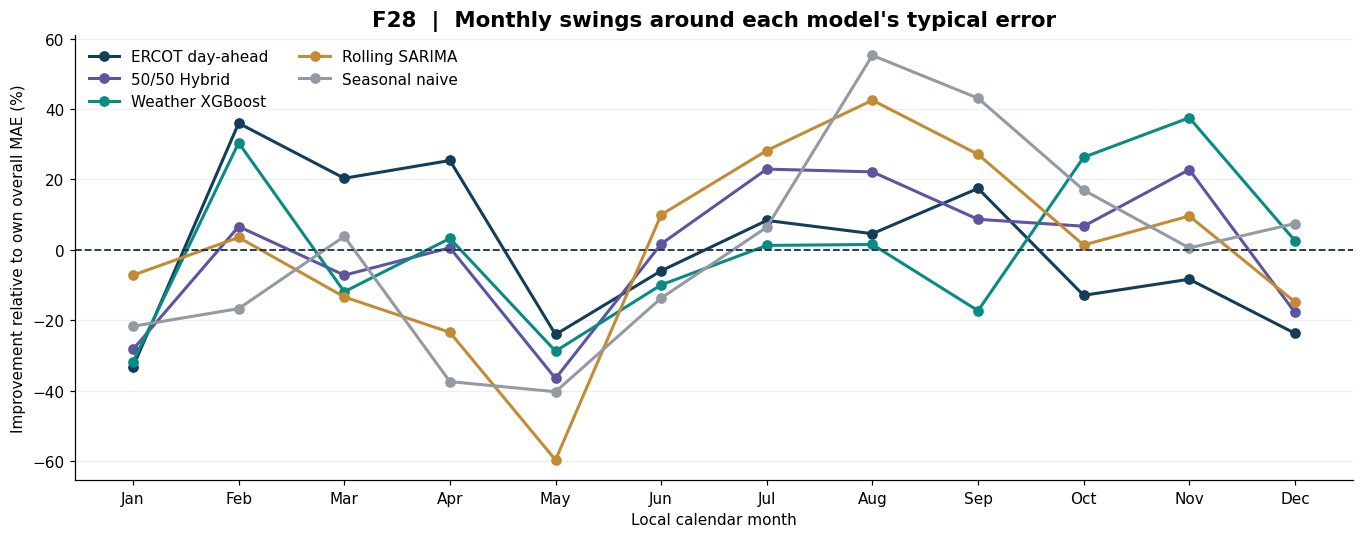

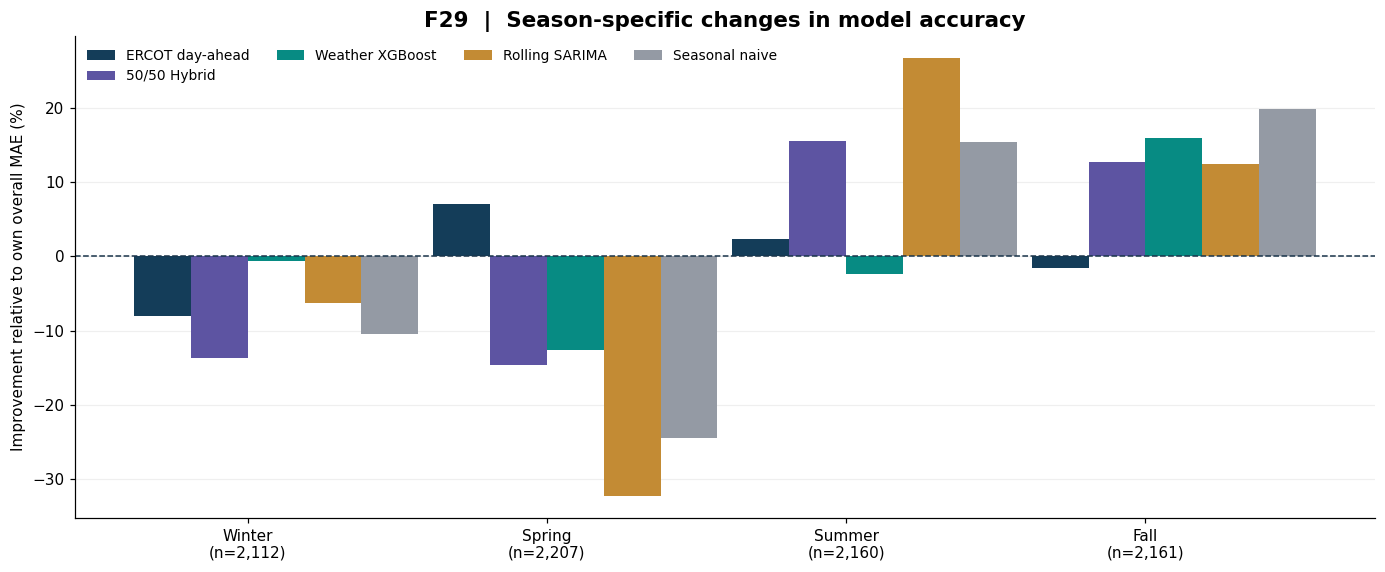

In [40]:
# --- Cell C: Month and season ---
fig,ax=plt.subplots(figsize=(12.5,5))
for model in MAE_MODELS:
    ax.plot(by_month.index,by_month[f'improve_{model}'],label=MODEL_NAMES[model],color=MODELCOLORS[model],lw=2,marker='o')
ax.axhline(0,color=INK,ls='--',lw=1.2)
ax.set(xticks=range(1,13),xlabel='Local calendar month',ylabel='Improvement relative to own overall MAE (%)',title='F28  |  Monthly swings around each model\'s typical error')
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.legend(ncol=2,frameon=False)
ax.grid(axis='y',alpha=.2)
mae_figure(fig,'F28_monthly_percent_better_worse.png')

fig,ax=plt.subplots(figsize=(12.7,5.3))
x=np.arange(len(SEASONS)); width=.19
for j,model in enumerate(MAE_MODELS):
    ax.bar(x+(j-1.5)*width,by_season[f'improve_{model}'],width,label=MODEL_NAMES[model],color=MODELCOLORS[model])
ax.axhline(0,color=INK,ls='--',lw=1)
ax.set(xticks=x,xticklabels=[f'{s}\n(n={int(by_season.loc[s,"n"]):,})' for s in SEASONS],ylabel='Improvement relative to own overall MAE (%)',title='F29  |  Season-specific changes in model accuracy')
ax.legend(ncol=4,frameon=False,fontsize=9)
ax.grid(axis='y',alpha=.2)
mae_figure(fig,'F29_seasonal_percent_better_worse.png')



### F30–F31 | Month-by-hour and season-by-hour error heatmaps

A monthly or seasonal average can hide within-day changes. Green cells indicate model MAE below its overall reference; red cells indicate above-reference error. These are **error heatmaps**, distinct from the descriptive observed-demand heatmaps F03A–F03E.

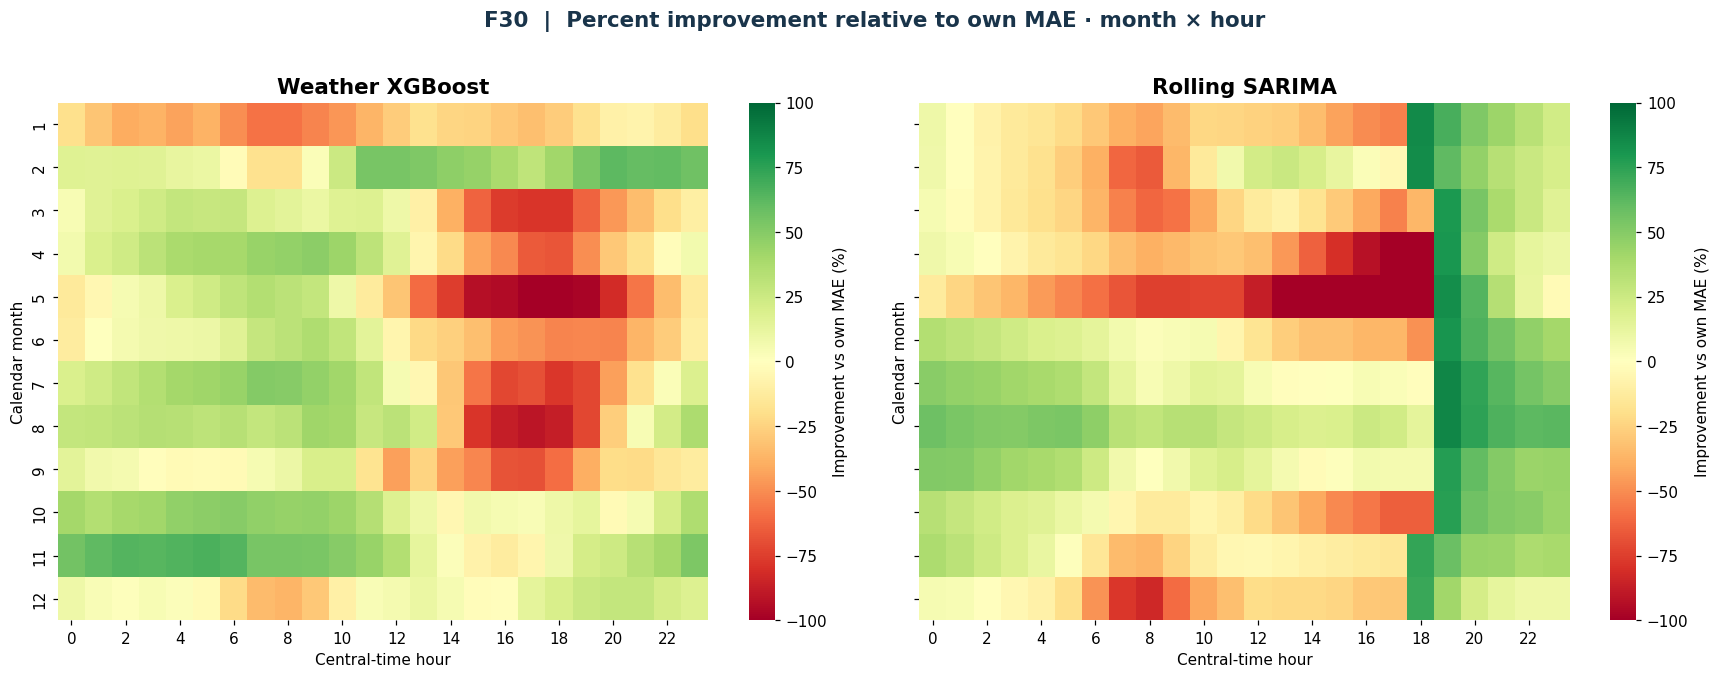

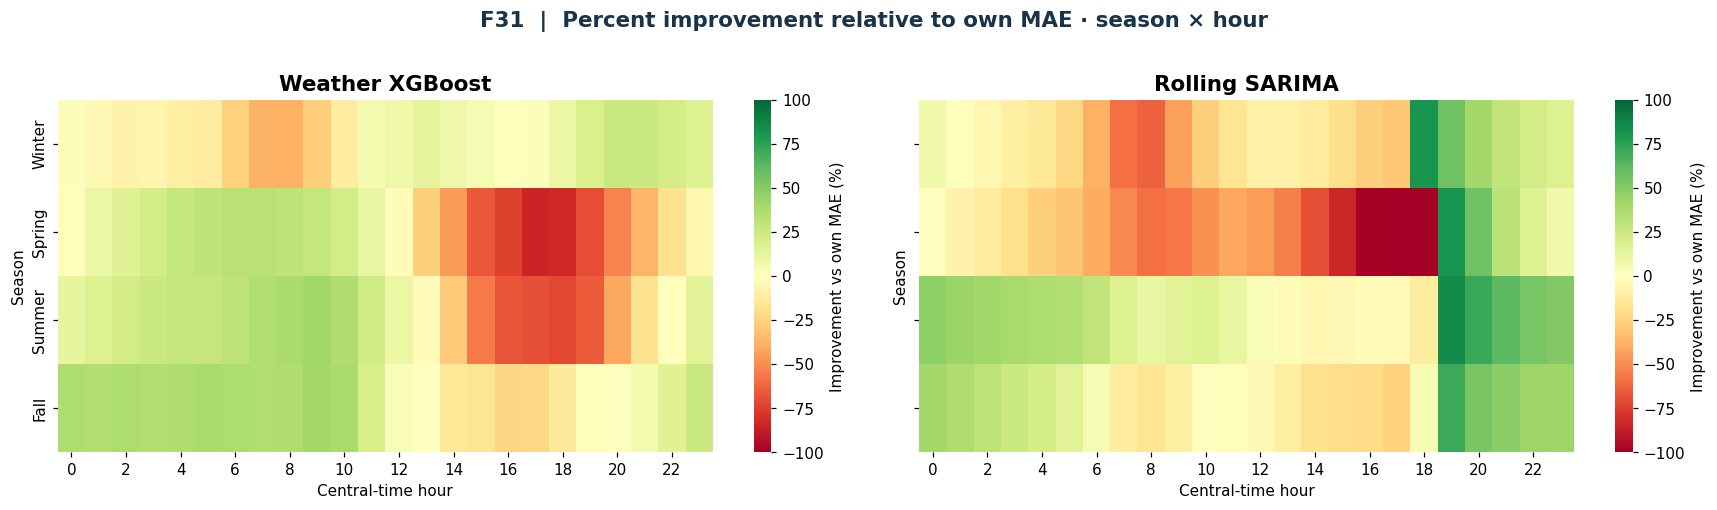

In [41]:
# --- Cell D: Heatmaps to see interactions (month x hour and season x hour) ---
for grouping,index,filename,title in [
    (by_month_hour,list(range(1,13)),'F30_month_hour_model_improvement.png','F30  |  Percent improvement relative to own MAE · month × hour'),
    (by_season_hour,SEASONS,'F31_season_hour_model_improvement.png','F31  |  Percent improvement relative to own MAE · season × hour')
]:
    fig,axes=plt.subplots(1,2,figsize=(16,6.0 if len(index)==12 else 4.5),sharex=True,sharey=True)
    for ax,model in zip(axes,['WEATHER_XGBOOST','ROLLING_SARIMA']):
        matrix=grouping[f'improve_{model}'].unstack('local_hour').reindex(index=index,columns=range(24))
        # Use a single fixed symmetrical color range for honest side-by-side comparison.
        # Common scale for both models, clipped only for display.
        sns.heatmap(matrix,ax=ax,cmap='RdYlGn',center=0,vmin=-100,vmax=100,cbar=True,
                    cbar_kws={'label':'Improvement vs own MAE (%)'},xticklabels=2,yticklabels=True)
        ax.set_title(MODEL_NAMES[model])
        ax.set(xlabel='Central-time hour',ylabel=('Calendar month' if len(index)==12 else 'Season'))
    fig.suptitle(title,color=INK,fontsize=14,fontweight='bold',y=1.02)
    mae_figure(fig,filename)



### F32 | Do changes relative to average also mean useful forecasting skill?

A drop below a model’s own MAE does not mean that it beats a meaningful forecasting alternative. The left panel measures improvement over the **seasonal naive** baseline using the period-specific MAE for both approaches; the right panel compares model error against **ERCOT day-ahead** on the identical hours.

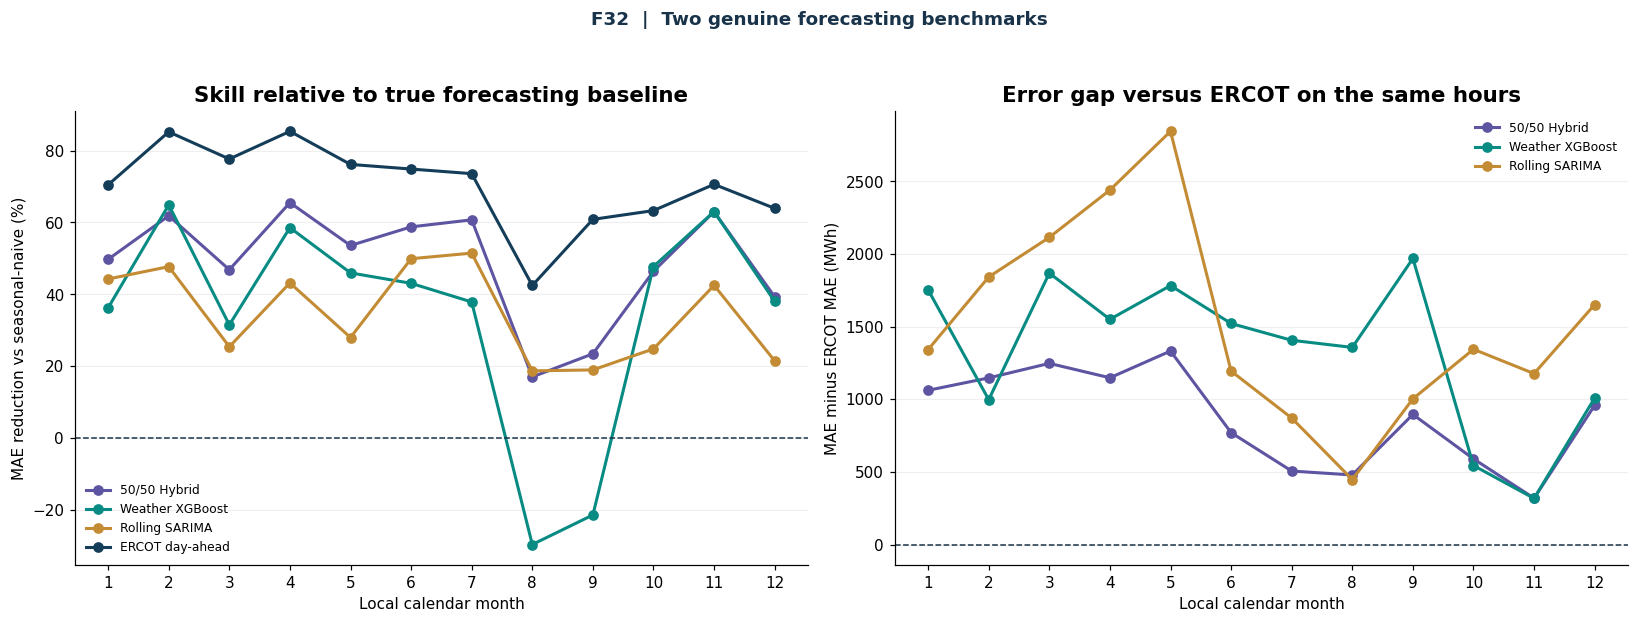

In [42]:
# --- Cell E: Real forecast baseline and external ERCOT benchmark ---
fig,axes=plt.subplots(1,2,figsize=(15,5.4))
for model in ['HYBRID_50_50','WEATHER_XGBOOST','ROLLING_SARIMA','ERCOT_DAY_AHEAD']:
    axes[0].plot(by_month.index,by_month[f'skill_{model}'],color=MODELCOLORS[model],lw=2,marker='o',label=MODEL_NAMES[model])
axes[0].axhline(0,color=INK,linestyle='--',lw=1)
axes[0].set(xlabel='Local calendar month',ylabel='MAE reduction vs seasonal-naive (%)',title='Skill relative to true forecasting baseline',xticks=range(1,13))
axes[0].legend(frameon=False,fontsize=8)
axes[0].grid(axis='y',alpha=.2)
for model in ['HYBRID_50_50','WEATHER_XGBOOST','ROLLING_SARIMA']:
    axes[1].plot(by_month.index,by_month[f'gap_ercot_{model}'],color=MODELCOLORS[model],lw=2,marker='o',label=MODEL_NAMES[model])
axes[1].axhline(0,color=INK,linestyle='--',lw=1)
axes[1].set(xlabel='Local calendar month',ylabel='MAE minus ERCOT MAE (MWh)',title='Error gap versus ERCOT on the same hours',xticks=range(1,13))
axes[1].legend(frameon=False,fontsize=8)
axes[1].grid(axis='y',alpha=.2)
fig.suptitle('F32  |  Two genuine forecasting benchmarks',fontweight='bold',color=INK,y=1.04)
mae_figure(fig,'F32_seasonal_naive_skill_and_ERCOT_gap.png')



### F33 | How did errors behave during a real peak week?

The previous figures average groups of hours. Here we show actual individual hourly absolute errors for the July 19–25 case study, keeping the typical MAE reference as a horizontal line. An individual large miss is not itself an MAE; MAE is the average over many such misses.

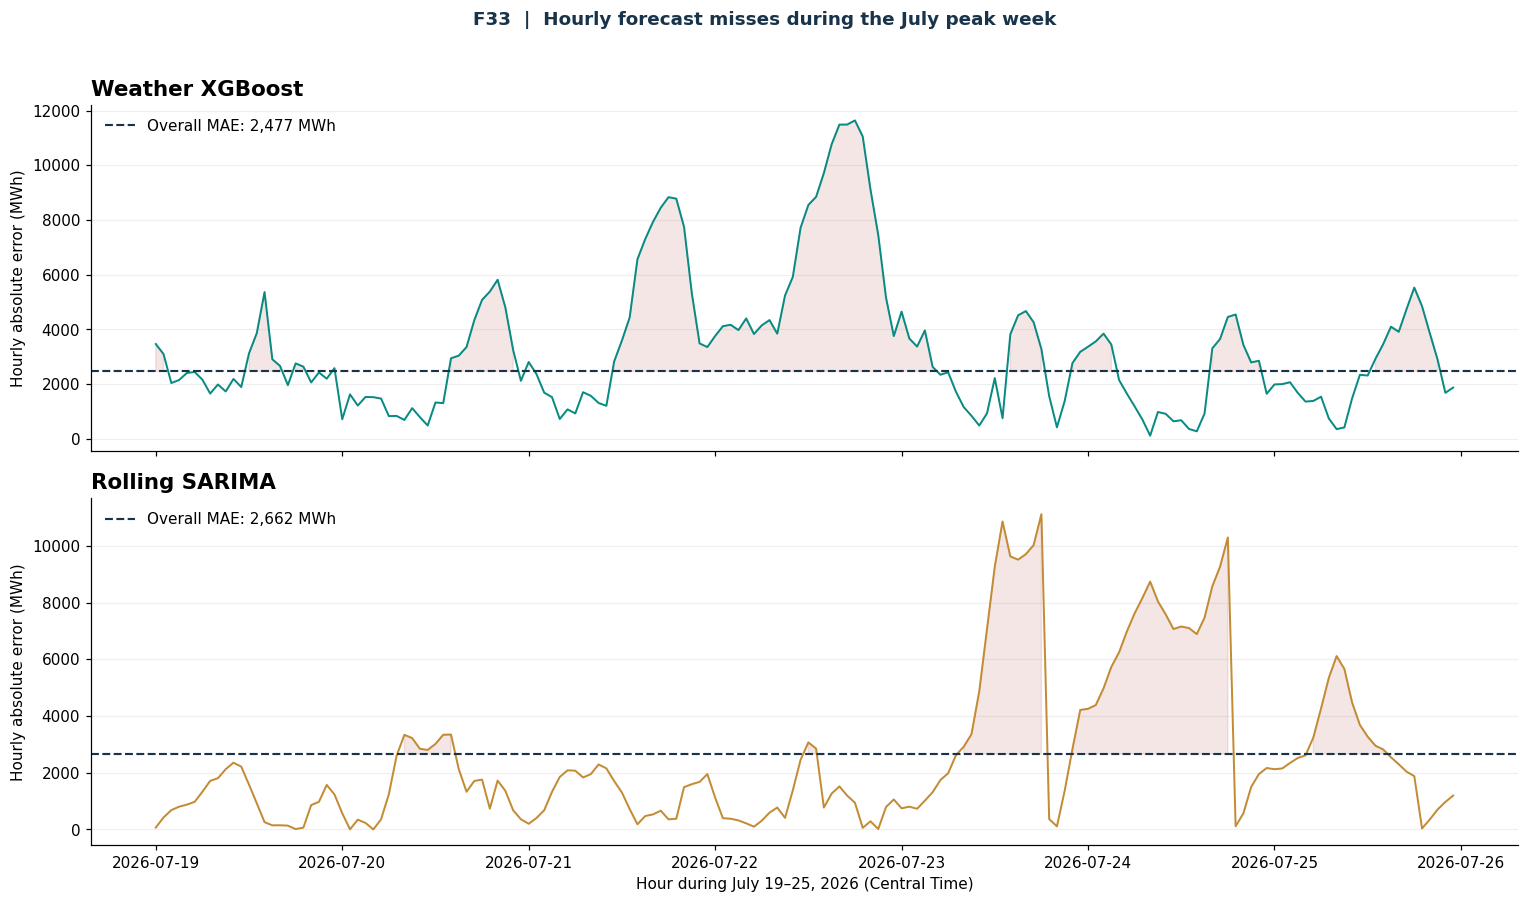


By month weather and sarima:
               n  improve_WEATHER_XGBOOST  improve_ROLLING_SARIMA  skill_WEATHER_XGBOOST  skill_ROLLING_SARIMA
local_month                                                                                                   
1            744                    -31.8                    -7.2                   36.2                  44.3
2            672                     30.4                     3.5                   64.9                  47.7
3            743                    -11.9                   -13.4                   31.5                  25.4
4            720                      3.2                   -23.5                   58.5                  43.2
5            744                    -28.8                   -59.7                   45.9                  28.0
6            720                    -10.0                    10.0                   43.0                  49.9
7            744                      1.3                    28.2                 

In [43]:
# --- Cell F: Single-day/hour investigation vs overall MAE ---
# We use a preselected peak-demand week that appears elsewhere in the notebook.
case_start=pd.Timestamp('2026-07-19',tz='America/Chicago').tz_convert('UTC')
case_end=pd.Timestamp('2026-07-26',tz='America/Chicago').tz_convert('UTC')
case=mae_frame[(mae_frame.timestamp_utc>=case_start)&(mae_frame.timestamp_utc<case_end)]
assert len(case)==168
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
for ax,model in zip(axes,['WEATHER_XGBOOST','ROLLING_SARIMA']):
    ax.plot(case.central_time,case[f'abs_{model}'],color=MODELCOLORS[model],lw=1.3)
    ax.axhline(OVERALL_MAE[model],ls='--',color=INK,lw=1.4,label=f'Overall MAE: {OVERALL_MAE[model]:,.0f} MWh')
    ax.fill_between(case.central_time,case[f'abs_{model}'],OVERALL_MAE[model],where=case[f'abs_{model}']>OVERALL_MAE[model],color=RED,alpha=.16)
    ax.set_ylabel('Hourly absolute error (MWh)')
    ax.set_title(MODEL_NAMES[model],loc='left')
    ax.legend(loc='upper left',frameon=False)
    ax.grid(axis='y',alpha=.2)
axes[-1].set_xlabel('Hour during July 19–25, 2026 (Central Time)')
fig.suptitle('F33  |  Hourly forecast misses during the July peak week',color=INK,fontweight='bold',y=1.02)
mae_figure(fig,'F33_july_week_hourly_errors_vs_MAE.png')

print('\nBy month weather and sarima:')
print(by_month[['n','improve_WEATHER_XGBOOST','improve_ROLLING_SARIMA','skill_WEATHER_XGBOOST','skill_ROLLING_SARIMA']].round(1).to_string())
print('\nSeasons summary:')
print(by_season[['n','improve_WEATHER_XGBOOST','improve_ROLLING_SARIMA','skill_WEATHER_XGBOOST','skill_ROLLING_SARIMA']].round(1).to_string())


### Interpretation and presentation recommendation

The average-error reference helps me explain model behavior in a way that an overall ranking cannot. In the matched holdout, Rolling SARIMA is approximately **26.7% better than its own overall MAE during summer** but approximately **32.3% worse than its own overall MAE during spring**. Weather XGBoost improves approximately **16.0% relative to its own reference during fall**, but its seasonal changes are different from SARIMA's. Those are descriptive within-model comparisons, not head-to-head percentage improvements. F32 tells us whether either model also beats seasonal naive and how close it gets to ERCOT.

**Suggested slide:** Start with F26 (hourly MAE and reference lines) or F29 (seasonal divergence), and use F30/F31 as a detailed supporting visual. Pair F32 with the already-existing F14 overall MAE chart so the audience does not mistake a relative within-model improvement for a better absolute forecast. These graphics show *where to investigate*; they do not establish why a model struggled or that a weather feature was available at forecast issuance.

## 9. Milestone 2 synthesis and handoff to the team — updated October 25

### Verified results using Andrea's hybrid-inclusive prediction CSV

1. **Demand has structure.** Calendar and weather-related patterns motivate the features without proving a single causal predictor.
2. **ERCOT remains the external benchmark.** Its matched-sample MAE is about **1,135 MWh**. The **official 50/50 hybrid** of rolling SARIMA and weather-enhanced XGBoost is the best team approach at **2,006 MWh MAE**, an approximately **52% improvement** versus seasonal naive (**4,205 MWh**). Weather XGBoost alone achieves **2,477 MWh**.
3. **Peak-hour ranking is different.** Across the **88 top-one-percent demand hours**, rolling SARIMA (**1,242 MWh MAE**) and weather SARIMAX (**1,176 MWh**) outperform the hybrid (**3,189 MWh**). Weather XGBoost alone reaches **6,421 MWh** in the same hours.
4. **Averaging complementary models helps overall, but cannot solve every regime.** The 50/50 hybrid is not a new algorithm trained independently; it averages the two exported forecasts. F21–F25 additionally examine candidate non-50/50 weights, a separate exploratory exercise.
5. **The evaluation remains retrospective.** Matched timestamps do not guarantee that models have equivalent forecast issuance times, weather knowledge, or lag availability. Observed peak classification cannot be used to choose an operational forecast before the true demand is known.

### Updated report figure connections

| Milestone 2 report figure | Source notebook section | Main point |
|---|---|---|
| **Figure 1** | **F03 month-hour heatmap** | Historical demand differs by season and hour. |
| **Figure 2** | **F14 matched-sample model MAE** | Eight approaches including ERCOT and the hybrid; the hybrid is the top team model. |
| **Figure 3** | **F16 weekly forecast overlay** | Actual demand, ERCOT, both hybrid components, and their 50/50 average in July. |
| **Figure 4** | **F17 demand-level MAE** | The hybrid leads overall but SARIMA-family models perform better at observed peak demand. |

**Recommended presentation storyline:** Show Figure 2 for model ranking, Figure 3 for an intuitive forecast example, and Figure 4 for the crucial operational limitation. Report Figure 4 uses demand cutoffs from all 8,760 test-year actuals and measures MAE on the 8,640 matched hours; the peak group contains **88 hours**. The three final document-ready PNGs are also supplied separately, with a small reproducibility notebook that runs from Andrea's CSV alone.

**Still to verify before any deployment claims:** data/feature availability at forecast issuance (especially observed weather), consistent forecast horizons, and a genuine external evaluation after all model and blending decisions. These retrospective plots do not demonstrate readiness to replace operator forecasts.

### Supplementary original visuals worth preserving

| Recommended size | Figure | Why it answers the business question |
|---|---|---|
| Quarter page | **F03A · Daily heatmap comparison (four seasons)** | Shows how seasonal averages conceal day-to-day variation and peak-load timing. |
| Quarter page | **F14 · Matched-sample model MAE** | Gives the central eight-approach, identical-hour accuracy result. |
| Quarter page | **F17 · Accuracy across demand levels** | Explains why evaluating peak load adds important nuance beyond one overall metric. |
| Half page | **F29 · Seasonal MAE divergence** | Shows when each model departs from its typical error; F32 verifies performance against the seasonal-naive baseline. |

### Before anyone claims forecast readiness

- **Andrea:** confirm how rolling SARIMA's 24-hour UTC blocks, XGBoost's target-hour lags, ERCOT's published forecast vintage, and Prophet's forecast origins map to the same day-ahead decision.
- **Andrea / Sarah:** verify that temperature values and lag features are available (or forecast) by issuance time; observed same-hour weather alone is not a day-ahead feature.
- **Matthew:** keep the table and figure captions explicit about **MWh**, sample sizes, retrospective bins, UTC matching, and local clock labeling.
- **Team:** decide whether any exploratory blend-weight tuning (F21–F25) should be highlighted, or whether to restrict the report to Andrea's official fixed 50/50 hybrid. An additional genuinely out-of-time evaluation is needed before operational conclusions.

**Methods/sources to cite in the written report:** U.S. Energy Information Administration (EIA-930); ERCOT public demand forecasts; statsmodels SARIMAX documentation; Hyndman and Athanasopoulos, *Forecasting: Principles and Practice*; Chen and Guestrin, XGBoost; Taylor and Letham, Prophet. Numerical results in this notebook derive from **the team's supplied CSVs**, not from those publications.

**Figure expansion:** F03A–F03E provide daily seasonal heatmaps, and F26–F33 provide overall-MAE divergence, period-specific baseline skill, ERCOT comparison, and a single-week error case study. Select a few clear plots for the report while leaving the complete notebook and supporting figures available to the team.


In [44]:
# Final run audit: source alignment, shared hours, daily heatmaps and MAE divergence.
assert len(df)==41616 and len(preds)==8760 and len(eval_df)==8640
assert len(earlier)+len(later)==8640
assert not earlier[['BLEND_EQUAL','BLEND_SELECTED']].isna().any().any()
assert not later[['BLEND_EQUAL','BLEND_SELECTED']].isna().any().any()
assert eval_df.timestamp_utc.is_unique
assert 'HYBRID_50_50' in eval_df.columns and abs(OVERALL_MAE['HYBRID_50_50']-2005.849332)<1
assert counts.loc['Top 1%']==88
assert by_hour.n.sum()==by_month.n.sum()==by_season.n.sum()==8640
assert len(DAILY_HEATMAPS)==4
expected_prefixes=['F01', 'F02', 'F03', 'F04', 'F05', 'F06', 'F07', 'F08', 'F09', 'F10', 'F11', 'F12', 'F13', 'F14', 'F15', 'F16', 'F17', 'F18', 'F19', 'F20', 'F21', 'F22', 'F23', 'F24', 'F25', 'F03A', 'F03B', 'F03C', 'F03D', 'F03E', 'F26', 'F27', 'F28', 'F29', 'F30', 'F31', 'F32', 'F33']
figure_files=list(FIG_DIR.glob('F*.png'))
missing=[tag for tag in expected_prefixes if not any(f.name.startswith(tag+'_') for f in figure_files)]
assert not missing, f'Missing expected figures: {missing}'
print(f'PASS: {len(df):,} historical hours, {len(preds):,} prediction rows, {len(eval_df):,} matched benchmark hours.')
print('PASS: two CSVs loaded from the source menu / auto-discovery.')
print('PASS: four complete-season day/hour matrices built and shared-color-scale figures saved.')
print('PASS: eight MAE-divergence/baseline figures include official hybrid where applicable.')
print(f'PASS: {len(expected_prefixes)} expected figures are available in {FIG_DIR.resolve()}')


PASS: 41,616 historical hours, 8,760 prediction rows, 8,640 matched benchmark hours.
PASS: two CSVs loaded from the source menu / auto-discovery.
PASS: four complete-season day/hour matrices built and shared-color-scale figures saved.
PASS: eight MAE-divergence/baseline figures include official hybrid where applicable.
PASS: 38 expected figures are available in /content/milestone2_figures
